# Step 1

## Imports

In [1]:
# Import all libraries

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline

from matplotlib import *
import seaborn as sns

import datetime
import mplfinance as mpf
import cufflinks as cs

import tensorflow as tf
from tensorflow import keras

from tqdm import tqdm

import random

from sklearn.model_selection import train_test_split

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, mean_absolute_error, mean_squared_error, r2_score

import talib as ta

2024-12-16 08:41:16.367672: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1734338476.655398    4579 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1734338476.737837    4579 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-12-16 08:41:17.451771: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
np.random.seed(42)

## Load CSV

In [4]:
# load csv files
df_Ask = pd.read_csv("ETHGBP_1 Min_Ask_2024.09.01_2024.11.30.csv")
df_Bid = pd.read_csv("ETHGBP_1 Min_Bid_2024.09.01_2024.11.30.csv")

In [5]:
# print information
print(df_Ask)

                 Time (UTC)    Open    High     Low   Close  Volume 
0       2024.09.01 00:00:00  1919.2  1919.2  1918.5  1918.9  0.02592
1       2024.09.01 00:01:00  1918.9  1918.9  1917.6  1917.6  0.00936
2       2024.09.01 00:02:00  1917.6  1919.5  1917.6  1919.5  0.02016
3       2024.09.01 00:03:00  1919.4  1919.5  1918.0  1918.1  0.01224
4       2024.09.01 00:04:00  1918.2  1919.5  1918.2  1919.4  0.01656
...                     ...     ...     ...     ...     ...      ...
131035  2024.11.30 23:55:00  2916.0  2916.6  2914.0  2916.1  0.03942
131036  2024.11.30 23:56:00  2915.3  2916.2  2915.3  2915.4  0.03078
131037  2024.11.30 23:57:00  2915.5  2915.5  2913.2  2914.0  0.03726
131038  2024.11.30 23:58:00  2914.1  2914.4  2912.6  2912.8  0.05400
131039  2024.11.30 23:59:00  2912.9  2913.4  2912.4  2913.4  0.03888

[131040 rows x 6 columns]


In [6]:
print(df_Bid)

                 Time (UTC)    Open    High     Low   Close  Volume 
0       2024.09.01 00:00:00  1911.6  1911.6  1910.8  1911.2  0.02340
1       2024.09.01 00:01:00  1911.3  1911.3  1909.9  1909.9  0.00845
2       2024.09.01 00:02:00  1910.0  1911.8  1910.0  1911.8  0.01820
3       2024.09.01 00:03:00  1911.8  1911.9  1910.4  1910.4  0.01105
4       2024.09.01 00:04:00  1910.6  1911.8  1910.5  1911.7  0.01495
...                     ...     ...     ...     ...     ...      ...
131035  2024.11.30 23:55:00  2908.8  2909.3  2906.7  2908.8  0.03577
131036  2024.11.30 23:56:00  2908.0  2908.8  2908.0  2908.1  0.02793
131037  2024.11.30 23:57:00  2908.2  2908.2  2905.9  2906.7  0.03381
131038  2024.11.30 23:58:00  2906.8  2907.1  2905.3  2905.5  0.04900
131039  2024.11.30 23:59:00  2905.6  2906.2  2905.1  2906.1  0.03528

[131040 rows x 6 columns]


In [7]:
df_Ask.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131040 entries, 0 to 131039
Data columns (total 6 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Time (UTC)  131040 non-null  object 
 1   Open        131040 non-null  float64
 2   High        131040 non-null  float64
 3   Low         131040 non-null  float64
 4   Close       131040 non-null  float64
 5   Volume      131040 non-null  float64
dtypes: float64(5), object(1)
memory usage: 6.0+ MB


In [8]:
df_Bid.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131040 entries, 0 to 131039
Data columns (total 6 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Time (UTC)  131040 non-null  object 
 1   Open        131040 non-null  float64
 2   High        131040 non-null  float64
 3   Low         131040 non-null  float64
 4   Close       131040 non-null  float64
 5   Volume      131040 non-null  float64
dtypes: float64(5), object(1)
memory usage: 6.0+ MB


## Merge CSV

In [10]:
# merge csv file and show info
df = df_Bid.merge(df_Ask, left_on="Time (UTC)", right_on="Time (UTC)", how="outer")
print(df)

                 Time (UTC)  Open_x  High_x   Low_x  Close_x  Volume _x  \
0       2024.09.01 00:00:00  1911.6  1911.6  1910.8   1911.2    0.02340   
1       2024.09.01 00:01:00  1911.3  1911.3  1909.9   1909.9    0.00845   
2       2024.09.01 00:02:00  1910.0  1911.8  1910.0   1911.8    0.01820   
3       2024.09.01 00:03:00  1911.8  1911.9  1910.4   1910.4    0.01105   
4       2024.09.01 00:04:00  1910.6  1911.8  1910.5   1911.7    0.01495   
...                     ...     ...     ...     ...      ...        ...   
131035  2024.11.30 23:55:00  2908.8  2909.3  2906.7   2908.8    0.03577   
131036  2024.11.30 23:56:00  2908.0  2908.8  2908.0   2908.1    0.02793   
131037  2024.11.30 23:57:00  2908.2  2908.2  2905.9   2906.7    0.03381   
131038  2024.11.30 23:58:00  2906.8  2907.1  2905.3   2905.5    0.04900   
131039  2024.11.30 23:59:00  2905.6  2906.2  2905.1   2906.1    0.03528   

        Open_y  High_y   Low_y  Close_y  Volume _y  
0       1919.2  1919.2  1918.5   1918.9    0.0

## Rename columns

In [12]:
# rename columns
df.columns = ['Local time', 'Open_Bid', 'High_Bid', 'Low_Bid', 'Close_Bid', 'Volume_Bid',
                   'Open_Ask', 'High_Ask', 'Low_Ask', 'Close_Ask', 'Volume_Ask']

## Set time object to datetime

In [14]:
# transform date
df["Local_time_T"] = pd.to_datetime(df["Local time"], utc=True)

## Feature Engineering

### Create technical indicators

In [17]:
# 2. Create Technical Indicators (Ask and Bid prices separately)

# For Ask prices
df['Alligator_Jaw_Ask'] = ta.EMA(df['High_Ask'], timeperiod=13).shift(8)
df['Alligator_Teeth_Ask'] = ta.EMA(df['High_Ask'], timeperiod=8).shift(5)
df['Alligator_Lips_Ask'] = ta.EMA(df['High_Ask'], timeperiod=5).shift(3)

df['MACD_Ask'], df['MACD_Signal_Ask'], df['MACD_Hist_Ask'] = ta.MACD(df['High_Ask'], fastperiod=12, slowperiod=26, signalperiod=9)
df['RSI_Ask'] = ta.RSI(df['Close_Ask'], timeperiod=14)
df['Bollinger_Upper_Ask'], df['Bollinger_Middle_Ask'], df['Bollinger_Lower_Ask'] = ta.BBANDS(df['High_Ask'], timeperiod=20, nbdevup=2, nbdevdn=2, matype=0)

# Add EMA for Ask prices
df['EMA_50_Ask'] = ta.EMA(df['High_Ask'], timeperiod=50)
df['EMA_200_Ask'] = ta.EMA(df['High_Ask'], timeperiod=200)

# For Bid prices
df['Alligator_Jaw_Bid'] = ta.EMA(df['Low_Bid'], timeperiod=13).shift(8)
df['Alligator_Teeth_Bid'] = ta.EMA(df['Low_Bid'], timeperiod=8).shift(5)
df['Alligator_Lips_Bid'] = ta.EMA(df['Low_Bid'], timeperiod=5).shift(3)

df['MACD_Bid'], df['MACD_Signal_Bid'], df['MACD_Hist_Bid'] = ta.MACD(df['Low_Bid'], fastperiod=12, slowperiod=26, signalperiod=9)
df['RSI_Bid'] = ta.RSI(df['Close_Bid'], timeperiod=14)
df['Bollinger_Upper_Bid'], df['Bollinger_Middle_Bid'], df['Bollinger_Lower_Bid'] = ta.BBANDS(df['Low_Bid'], timeperiod=20, nbdevup=2, nbdevdn=2, matype=0)

# Add EMA for Bid prices
df['EMA_50_Bid'] = ta.EMA(df['Low_Bid'], timeperiod=50)
df['EMA_200_Bid'] = ta.EMA(df['Low_Bid'], timeperiod=200)

# Drop NaN values
df.dropna(inplace=True)

### Create deltas

In [19]:
# Delta of trading volumes (as well as the modulus of this delta) between Ask
# and Bid volumes are added as additional parameters
df["Volume_Delta"] = df["Volume_Ask"] - df["Volume_Bid"]
df["Volume_Delta_abs"] = (df["Volume_Ask"] - df["Volume_Bid"]).abs()
df["Open_Delta"] = df["Open_Ask"]  - df["Open_Bid"]
df["High_Delta"] = df["High_Ask"]  - df["High_Bid"]
df["Low_Delta"]  = df["Low_Ask"]   - df["Low_Bid"]
df["Close_Delta"]= df["Close_Ask"] - df["Close_Bid"]
print(df)

                 Local time  Open_Bid  High_Bid  Low_Bid  Close_Bid  \
199     2024.09.01 03:19:00    1896.0    1896.0   1894.4     1894.4   
200     2024.09.01 03:20:00    1894.4    1894.4   1893.6     1893.8   
201     2024.09.01 03:21:00    1893.8    1894.4   1893.8     1894.3   
202     2024.09.01 03:22:00    1894.4    1894.9   1894.2     1894.9   
203     2024.09.01 03:23:00    1895.0    1895.9   1895.0     1895.7   
...                     ...       ...       ...      ...        ...   
131035  2024.11.30 23:55:00    2908.8    2909.3   2906.7     2908.8   
131036  2024.11.30 23:56:00    2908.0    2908.8   2908.0     2908.1   
131037  2024.11.30 23:57:00    2908.2    2908.2   2905.9     2906.7   
131038  2024.11.30 23:58:00    2906.8    2907.1   2905.3     2905.5   
131039  2024.11.30 23:59:00    2905.6    2906.2   2905.1     2906.1   

        Volume_Bid  Open_Ask  High_Ask  Low_Ask  Close_Ask  ...  \
199        0.02470    1903.6    1903.7   1901.9     1902.0  ...   
200        0.

In [20]:
print(df.describe())

            Open_Bid       High_Bid        Low_Bid      Close_Bid  \
count  130841.000000  130841.000000  130841.000000  130841.000000   
mean     2073.385799    2074.238001    2072.533392    2073.391303   
std       313.729298     314.008385     313.464975     313.745693   
min      1634.300000    1642.700000    1633.400000    1634.200000   
25%      1856.200000    1856.800000    1855.400000    1856.200000   
50%      1951.500000    1952.200000    1950.800000    1951.500000   
75%      2244.900000    2245.800000    2244.000000    2245.000000   
max      2931.500000    2932.700000    2927.000000    2931.500000   

          Volume_Bid       Open_Ask       High_Ask        Low_Ask  \
count  130841.000000  130841.000000  130841.000000  130841.000000   
mean        0.025206    2078.429145    2079.280849    2077.577024   
std         0.018962     313.313242     313.604637     313.037192   
min         0.000000    1646.100000    1654.500000    1645.600000   
25%         0.011760    1860.9000

In [21]:
df.shape

(130841, 42)

In [22]:
df.isnull().sum()

Local time              0
Open_Bid                0
High_Bid                0
Low_Bid                 0
Close_Bid               0
Volume_Bid              0
Open_Ask                0
High_Ask                0
Low_Ask                 0
Close_Ask               0
Volume_Ask              0
Local_time_T            0
Alligator_Jaw_Ask       0
Alligator_Teeth_Ask     0
Alligator_Lips_Ask      0
MACD_Ask                0
MACD_Signal_Ask         0
MACD_Hist_Ask           0
RSI_Ask                 0
Bollinger_Upper_Ask     0
Bollinger_Middle_Ask    0
Bollinger_Lower_Ask     0
EMA_50_Ask              0
EMA_200_Ask             0
Alligator_Jaw_Bid       0
Alligator_Teeth_Bid     0
Alligator_Lips_Bid      0
MACD_Bid                0
MACD_Signal_Bid         0
MACD_Hist_Bid           0
RSI_Bid                 0
Bollinger_Upper_Bid     0
Bollinger_Middle_Bid    0
Bollinger_Lower_Bid     0
EMA_50_Bid              0
EMA_200_Bid             0
Volume_Delta            0
Volume_Delta_abs        0
Open_Delta  

In [23]:
data = df.drop(["Local time"], axis = 1)
print(data.info())
df_Ask = []
df_Bid = []
df = []

<class 'pandas.core.frame.DataFrame'>
Index: 130841 entries, 199 to 131039
Data columns (total 41 columns):
 #   Column                Non-Null Count   Dtype              
---  ------                --------------   -----              
 0   Open_Bid              130841 non-null  float64            
 1   High_Bid              130841 non-null  float64            
 2   Low_Bid               130841 non-null  float64            
 3   Close_Bid             130841 non-null  float64            
 4   Volume_Bid            130841 non-null  float64            
 5   Open_Ask              130841 non-null  float64            
 6   High_Ask              130841 non-null  float64            
 7   Low_Ask               130841 non-null  float64            
 8   Close_Ask             130841 non-null  float64            
 9   Volume_Ask            130841 non-null  float64            
 10  Local_time_T          130841 non-null  datetime64[ns, UTC]
 11  Alligator_Jaw_Ask     130841 non-null  float64         

## Visualizations

In [25]:
# 4. Visualization (Larger Plots for Better Visibility)

data_chart = data.iloc[1500:2000,:]

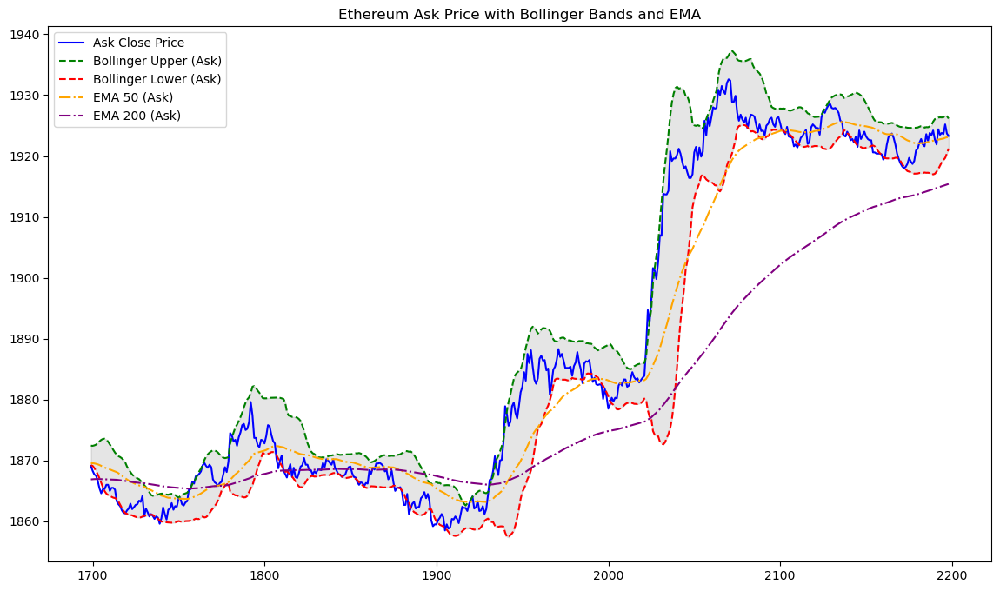

In [26]:
# Plot Ask Close and Bollinger Bands
plt.figure(figsize=(14, 8))
plt.plot(data_chart['Close_Ask'], label='Ask Close Price', color='blue')
plt.plot(data_chart['Bollinger_Upper_Ask'], label='Bollinger Upper (Ask)', linestyle='--', color='green')
plt.plot(data_chart['Bollinger_Lower_Ask'], label='Bollinger Lower (Ask)', linestyle='--', color='red')
plt.fill_between(data_chart.index, data_chart['Bollinger_Lower_Ask'], data_chart['Bollinger_Upper_Ask'], color='gray', alpha=0.2)
plt.plot(data_chart['EMA_50_Ask'], label='EMA 50 (Ask)', color='orange', linestyle='-.')
plt.plot(data_chart['EMA_200_Ask'], label='EMA 200 (Ask)', color='purple', linestyle='-.')
plt.title('Ethereum Ask Price with Bollinger Bands and EMA')
plt.legend()
plt.show()

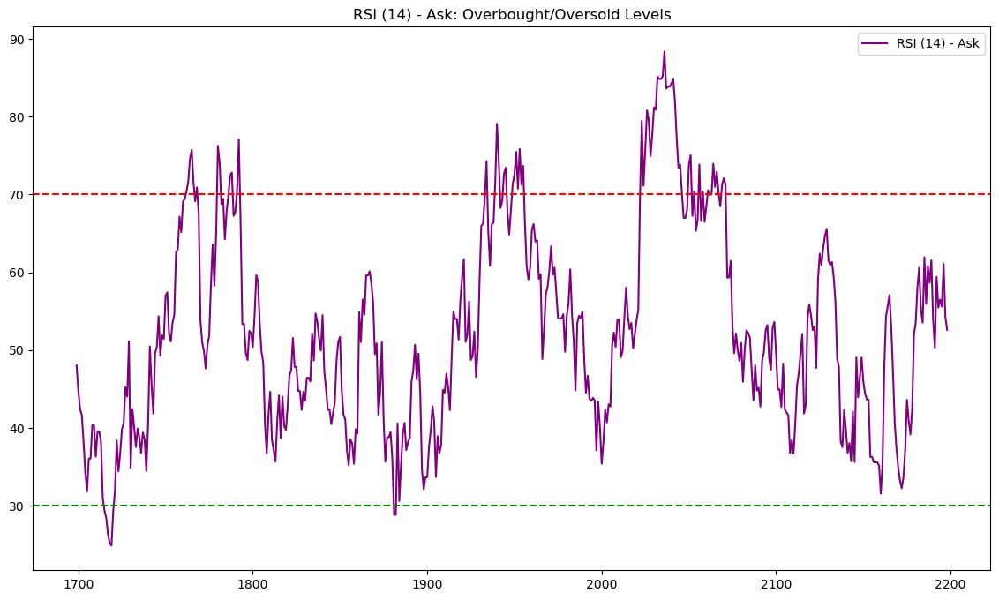

In [27]:
# Plot RSI for Ask
plt.figure(figsize=(14, 8))
plt.plot(data_chart['RSI_Ask'], label='RSI (14) - Ask', color='purple')
plt.axhline(70, color='red', linestyle='--')
plt.axhline(30, color='green', linestyle='--')
plt.title('RSI (14) - Ask: Overbought/Oversold Levels')
plt.legend()
plt.show()

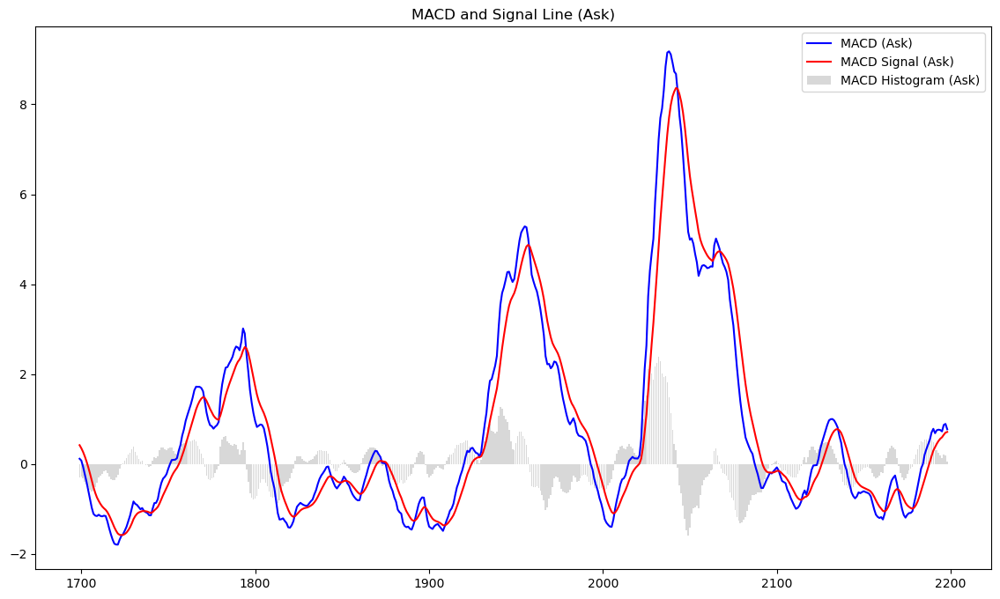

In [28]:
# Plot MACD for Ask
plt.figure(figsize=(14, 8))
plt.plot(data_chart['MACD_Ask'], label='MACD (Ask)', color='blue')
plt.plot(data_chart['MACD_Signal_Ask'], label='MACD Signal (Ask)', color='red')
plt.bar(data_chart.index, data_chart['MACD_Hist_Ask'], label='MACD Histogram (Ask)', color='gray', alpha=0.3)
plt.title('MACD and Signal Line (Ask)')
plt.legend()
plt.show()

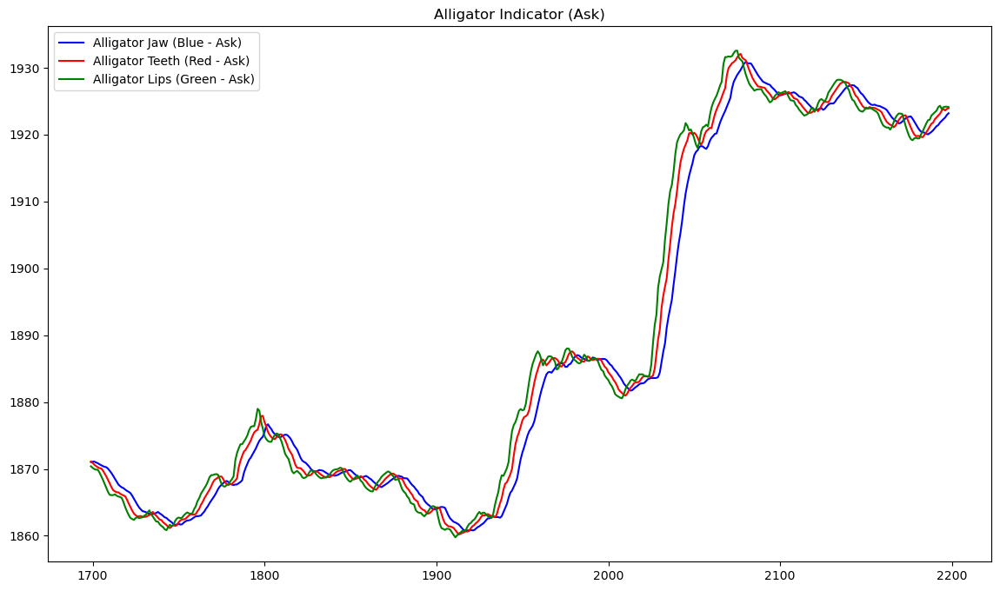

In [29]:
# Plot Alligator for Ask
plt.figure(figsize=(14, 8))
plt.plot(data_chart['Alligator_Jaw_Ask'], label='Alligator Jaw (Blue - Ask)', color='blue')
plt.plot(data_chart['Alligator_Teeth_Ask'], label='Alligator Teeth (Red - Ask)', color='red')
plt.plot(data_chart['Alligator_Lips_Ask'], label='Alligator Lips (Green - Ask)', color='green')
plt.title('Alligator Indicator (Ask)')
plt.legend()
plt.show()

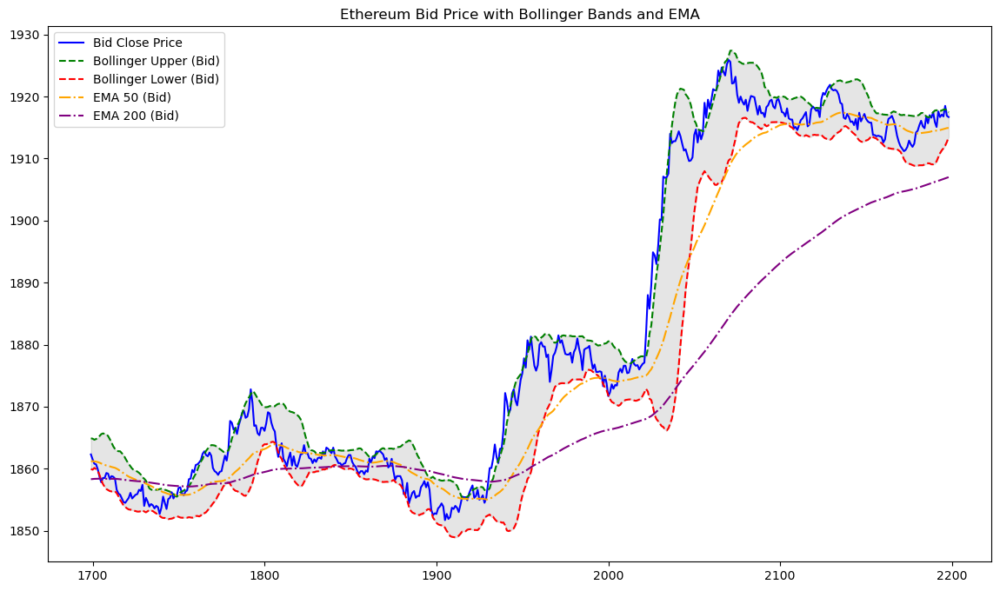

In [30]:
# Plot Bid Close and Bollinger Bands
plt.figure(figsize=(14, 8))
plt.plot(data_chart['Close_Bid'], label='Bid Close Price', color='blue')
plt.plot(data_chart['Bollinger_Upper_Bid'], label='Bollinger Upper (Bid)', linestyle='--', color='green')
plt.plot(data_chart['Bollinger_Lower_Bid'], label='Bollinger Lower (Bid)', linestyle='--', color='red')
plt.fill_between(data_chart.index, data_chart['Bollinger_Lower_Bid'], data_chart['Bollinger_Upper_Bid'], color='gray', alpha=0.2)
plt.plot(data_chart['EMA_50_Bid'], label='EMA 50 (Bid)', color='orange', linestyle='-.')
plt.plot(data_chart['EMA_200_Bid'], label='EMA 200 (Bid)', color='purple', linestyle='-.')
plt.title('Ethereum Bid Price with Bollinger Bands and EMA')
plt.legend()
plt.show()

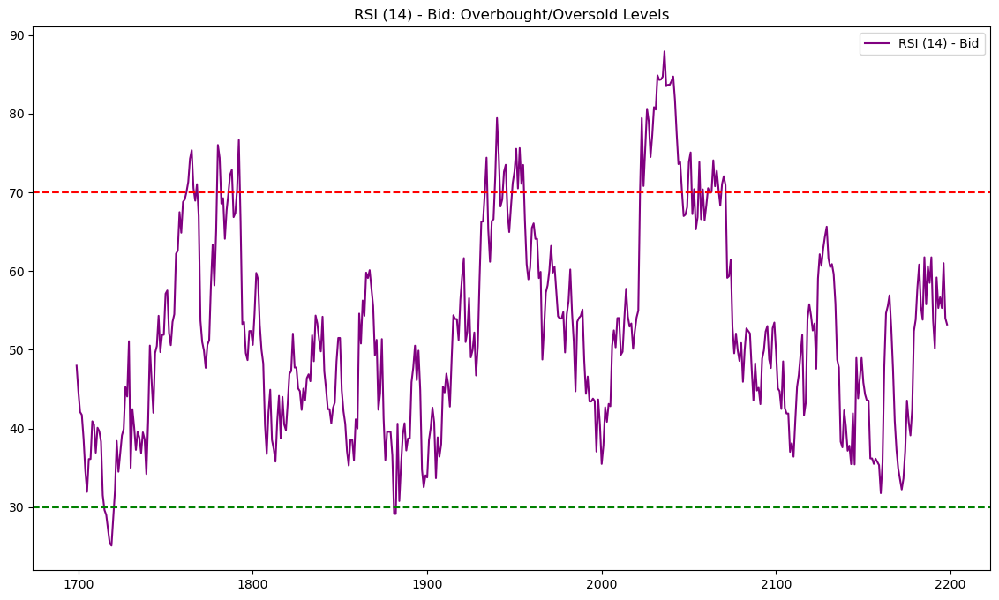

In [31]:
# Plot RSI for Bid
plt.figure(figsize=(14, 8))
plt.plot(data_chart['RSI_Bid'], label='RSI (14) - Bid', color='purple')
plt.axhline(70, color='red', linestyle='--')
plt.axhline(30, color='green', linestyle='--')
plt.title('RSI (14) - Bid: Overbought/Oversold Levels')
plt.legend()
plt.show()

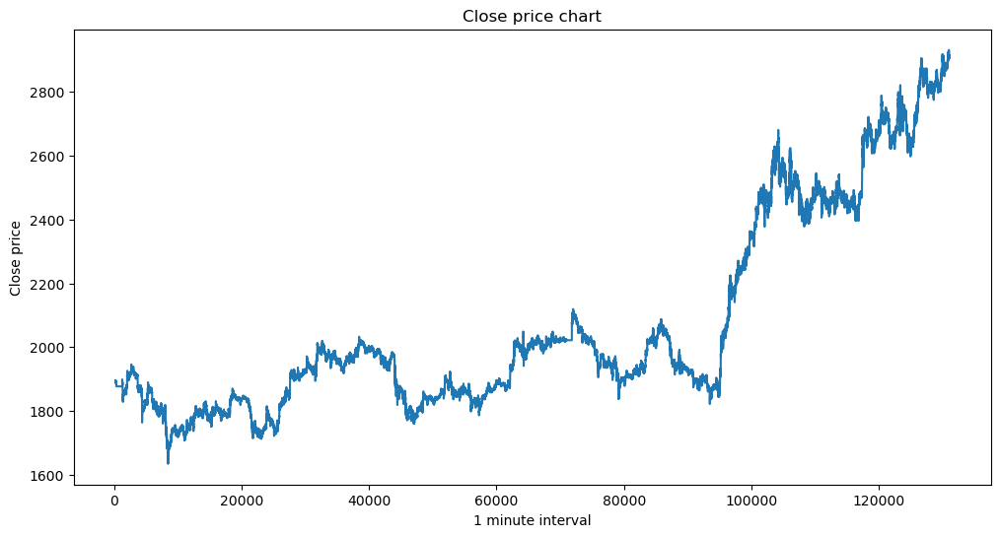

In [32]:
plt.figure(figsize=(12,6))
plt.plot(data['Close_Bid'])
plt.title('Close price chart')
plt.xlabel('1 minute interval')
plt.ylabel('Close price')
plt.show()

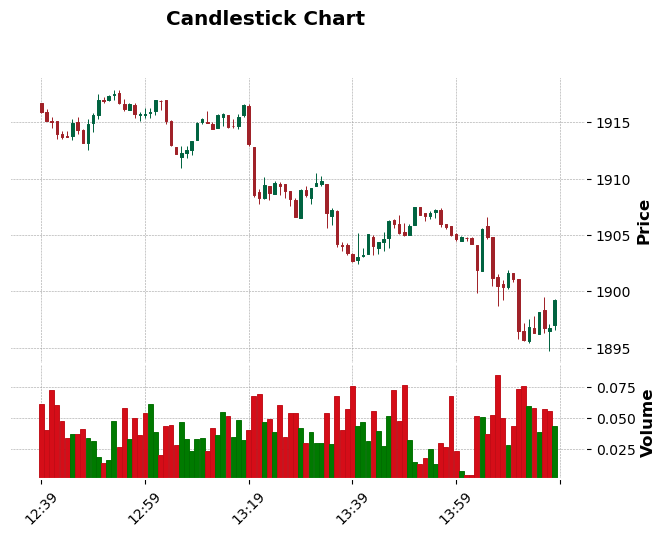

In [33]:
data_chart = data.set_index("Local_time_T", inplace = False)
data_chart = data_chart.drop([
    'Open_Ask', 'High_Ask', 'Low_Ask', 'Close_Ask', 'Volume_Ask',
    'Alligator_Jaw_Ask', 'Alligator_Teeth_Ask', 'Alligator_Lips_Ask',
    'MACD_Ask', 'MACD_Signal_Ask', 'MACD_Hist_Ask', 'RSI_Ask', 'Bollinger_Upper_Ask',
    'Bollinger_Middle_Ask', 'Bollinger_Lower_Ask', 'EMA_50_Ask', 'EMA_200_Ask',
    'Alligator_Jaw_Bid', 'Alligator_Teeth_Bid', 'Alligator_Lips_Bid',
    'MACD_Bid', 'MACD_Signal_Bid', 'MACD_Hist_Bid', 'RSI_Bid', 'Bollinger_Upper_Bid',
    'Bollinger_Middle_Bid', 'Bollinger_Lower_Bid', 'EMA_50_Bid', 'EMA_200_Bid',
    'Volume_Delta', 'Volume_Delta_abs',
    'Open_Delta', 'High_Delta', 'Low_Delta', 'Close_Delta'],axis=1)

data_chart.columns = ["Open", "High", "Low", "Close", "Volume"]
mpf.plot(data_chart.iloc[2000:2100], type = "candle", style = "charles", title = "Candlestick Chart", volume = True)

data_chart = []

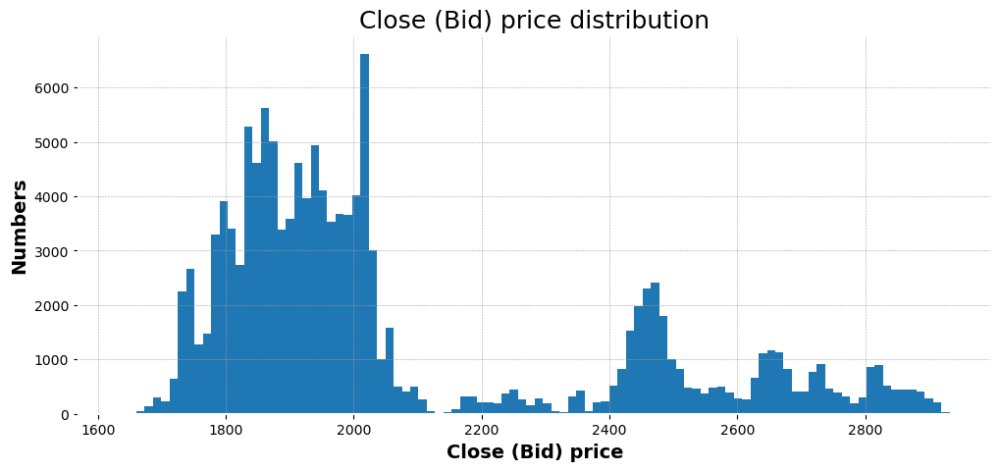

In [34]:
plt.figure(num=1,figsize=(12,5))
plt.hist(data['Close_Bid'],bins=100)
plt.title('Close (Bid) price distribution',size=18)
plt.ylabel('Numbers',size=14)
plt.xlabel('Close (Bid) price',size=14);

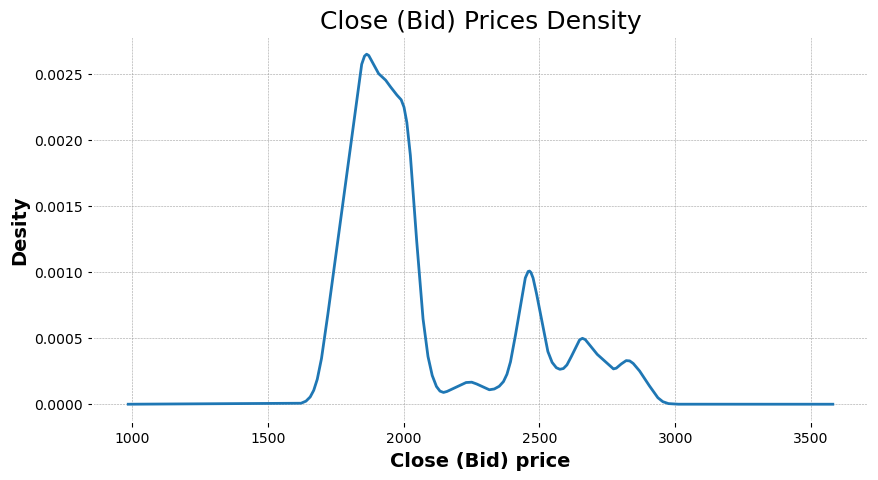

In [35]:
plt.figure(num=1,figsize=(10,5))
data["Close_Bid"].plot.kde()
plt.title("Close (Bid) Prices Density",size=18)
plt.ylabel("Desity",size=14)
plt.xlabel("Close (Bid) price",size=14);

<Figure size 1200x500 with 0 Axes>

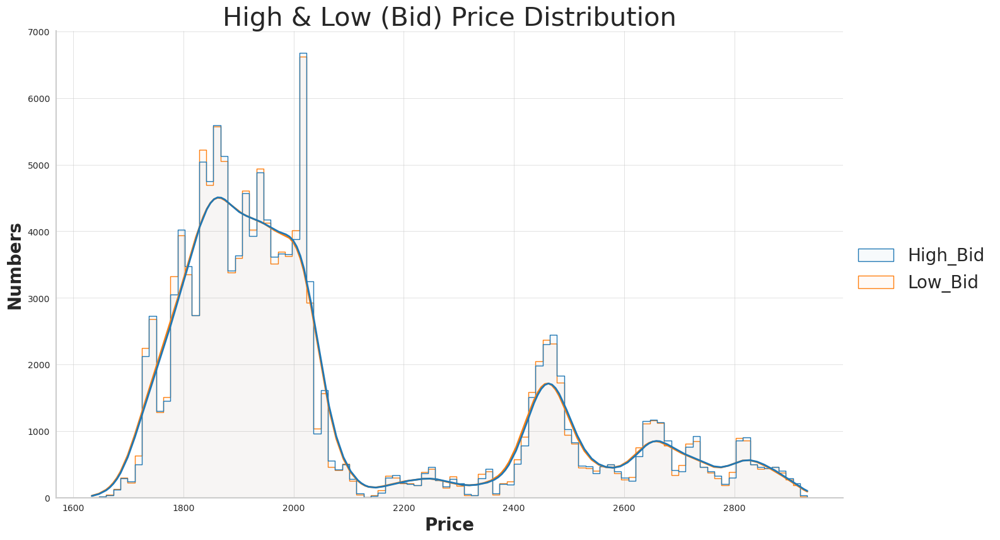

In [36]:
fig = plt.figure(figsize=(12, 5))
plt.rc('axes', titlesize= 30 )
sns.set_style('whitegrid')
sns.set_context(rc={'legend.fontsize': 20.0})

sns.displot(
            data[['High_Bid', 'Low_Bid']],
            height=8,
            aspect=1.7,
            #hue="species",
            kde=True,
            element="step",
            bins=100,
            alpha=0.03,

)

plt.title('High & Low (Bid) Price Distribution')
plt.xlabel('Price', size= 20)
#plt.ylabel('count (%)')
plt.ylabel('Numbers', size= 20)
plt.show();

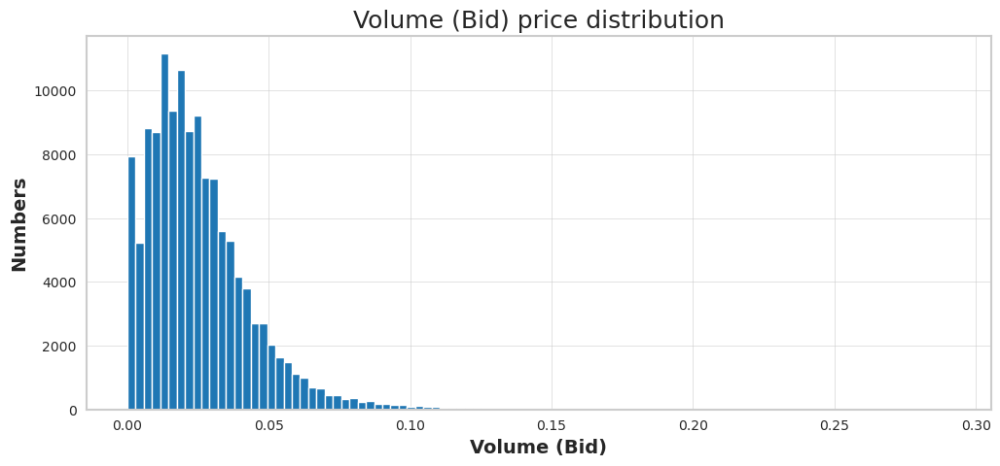

In [37]:
plt.figure(num=1,figsize=(12,5))
plt.hist(data['Volume_Bid'],bins=100)
plt.title('Volume (Bid) price distribution',size=18)
plt.ylabel('Numbers',size=14)
plt.xlabel('Volume (Bid)',size=14);

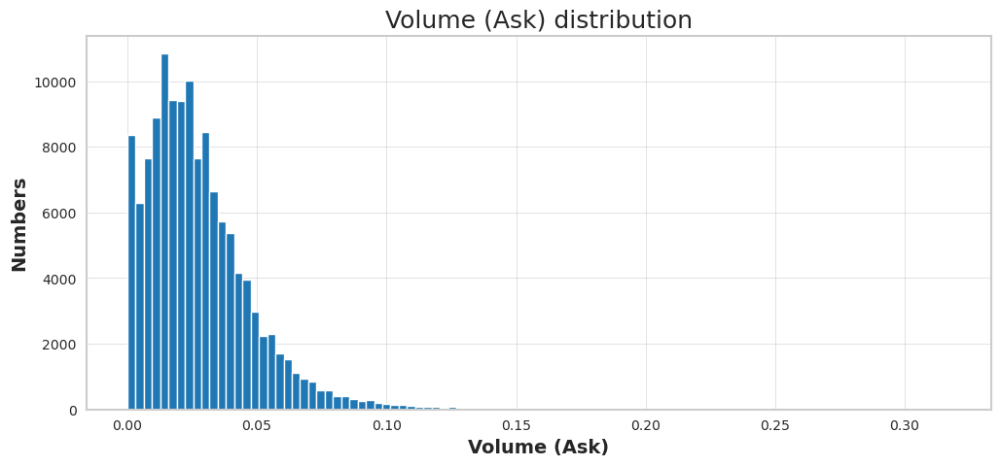

In [38]:
plt.figure(num=1,figsize=(12,5))
plt.hist(data['Volume_Ask'],bins=100)
plt.title('Volume (Ask) distribution',size=18)
plt.ylabel('Numbers',size=14)
plt.xlabel('Volume (Ask)',size=14);

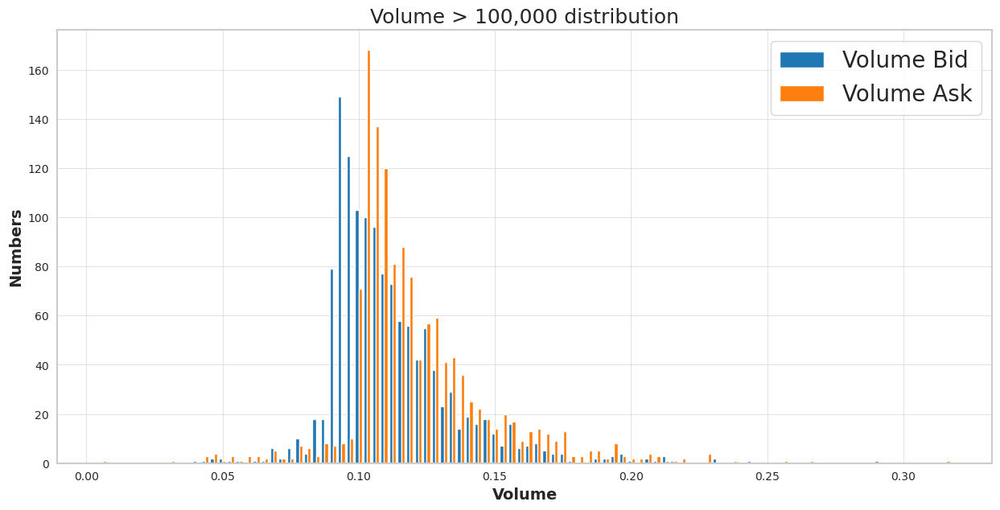

In [39]:
vol_350k = data[ (data["Volume_Bid"] > 0.1) | (data["Volume_Ask"] > 0.1) ]

plt.figure(num=1,figsize=(15,7))

plt.hist(vol_350k[['Volume_Bid', "Volume_Ask"]],bins=100)
plt.legend(["Volume Bid", "Volume Ask"])
plt.title('Volume > 100,000 distribution',size=18)
plt.ylabel('Numbers',size = 14)
plt.xlabel('Volume',size = 14);

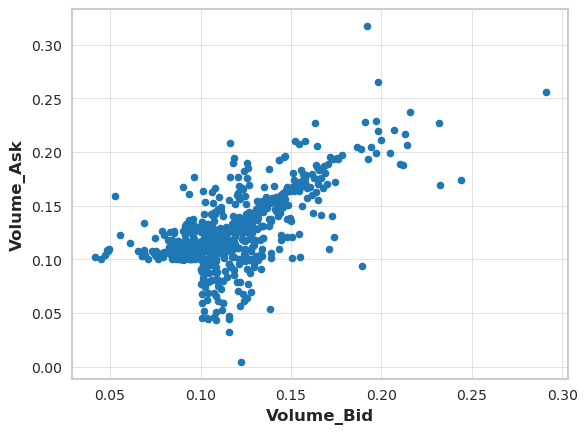

In [40]:
vol_350k.plot.scatter(x = "Volume_Bid", y = "Volume_Ask");

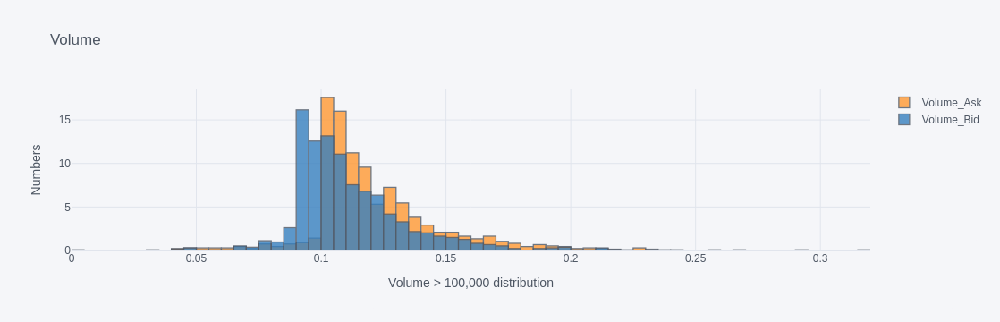

In [41]:
cs.go_offline()

vol_350k[['Volume_Ask', 'Volume_Bid']].iplot(
                            kind='hist',
                            histnorm='percent',
                            barmode='overlay',
                            xTitle='Volume > 100,000 distribution',
                            yTitle='Numbers',
                            title='Volume')

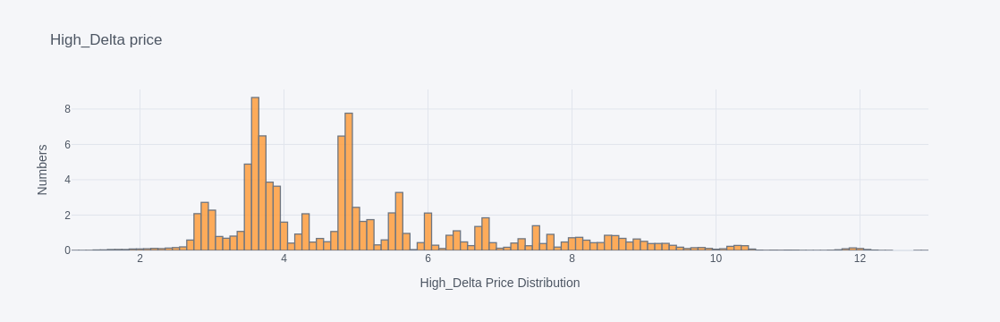

In [42]:
data[['High_Delta']].iplot(
                            kind='hist',
                            histnorm='percent',
                            barmode='overlay',
                            xTitle='High_Delta Price Distribution',
                            yTitle='Numbers',
                            title='High_Delta price')

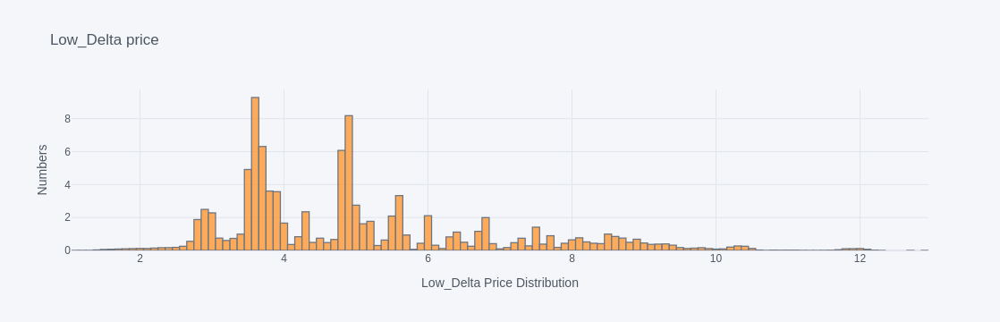

In [43]:
data[['Low_Delta']].iplot(
                            kind='hist',
                            histnorm='percent',
                            barmode='overlay',
                            xTitle='Low_Delta Price Distribution',
                            yTitle='Numbers',
                            title='Low_Delta price')

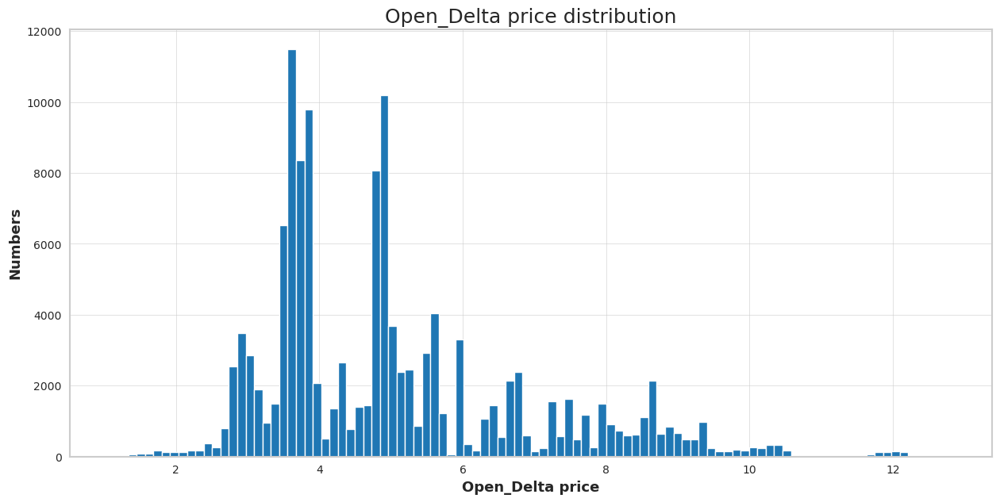

In [44]:
plt.figure(num=1,figsize=(15,7))
plt.hist(data['Open_Delta'],bins=100)
plt.title('Open_Delta price distribution',size=18)
plt.ylabel('Numbers',size = 13)
plt.xlabel('Open_Delta price',size = 13);

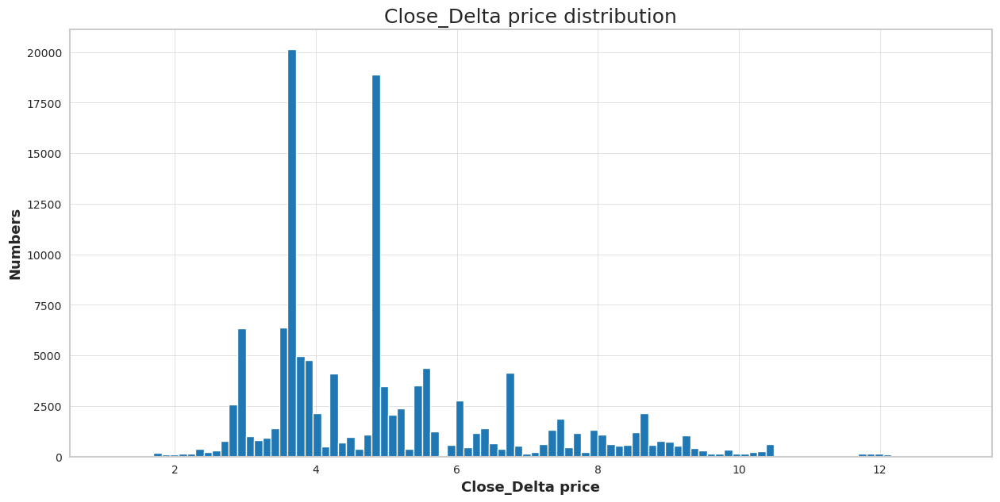

In [45]:
plt.figure(num=1,figsize=(15,7))
plt.hist(data['Close_Delta'],bins=100)
plt.title('Close_Delta price distribution',size=18)
plt.ylabel('Numbers',size = 13)
plt.xlabel('Close_Delta price',size = 13);

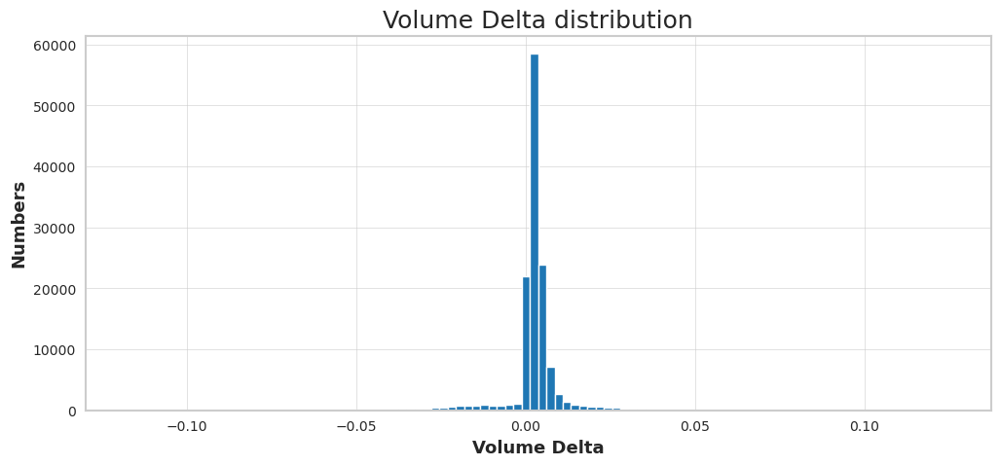

In [46]:
plt.figure(num=1,figsize=(12,5))
plt.hist(data['Volume_Delta'],bins=100)
plt.title('Volume Delta distribution',size=18)
plt.ylabel('Numbers',size = 13)
plt.xlabel('Volume Delta',size = 13);

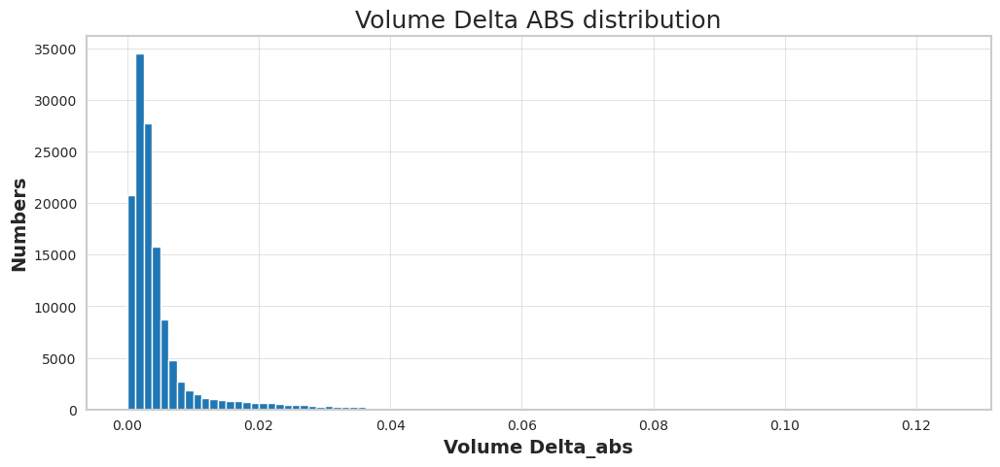

In [47]:
plt.figure(num=1,figsize=(12,5))
plt.hist(data['Volume_Delta_abs'],bins=100)
plt.title('Volume Delta ABS distribution',size=18)
plt.ylabel('Numbers',size = 14)
plt.xlabel('Volume Delta_abs',size = 14);

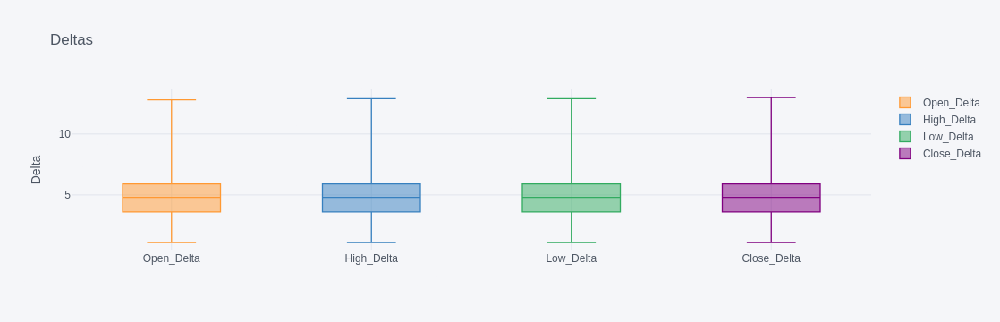

In [48]:
data[["Open_Delta", "High_Delta", "Low_Delta", "Close_Delta"]].iplot(
    kind="box",
    yTitle="Delta",
    title="Deltas")

/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/cufflinks/plotlytools.py:117: FutureWarning:

DatetimeIndex.format is deprecated and will be removed in a future version. Convert using index.astype(str) or index.map(formatter) instead.



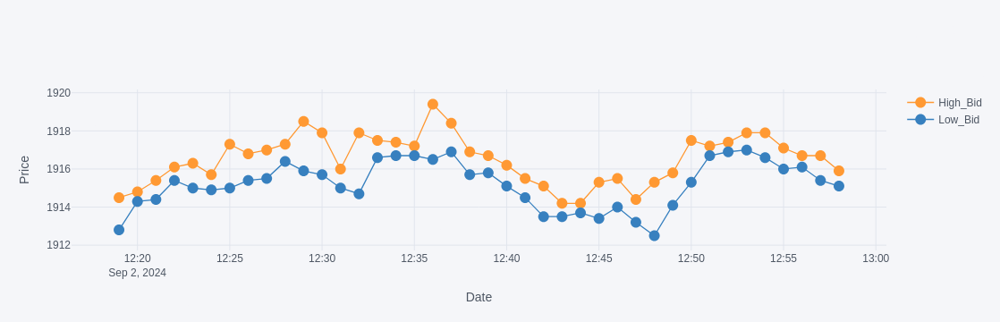

In [49]:
# plot the part of the whole dataset using iplot()
# The time period equals 400 minutes: from 19800 to 20200

data.iloc[1980:2020,:][['High_Bid', 'Low_Bid', 'Local_time_T', 'Volume_Ask','Volume_Bid']].iplot(
                                                x='Local_time_T', y=['High_Bid', 'Low_Bid'],
                                                mode='lines+markers',
                                                xTitle='Date', yTitle='Price',
                                                title='')

<Figure size 1200x500 with 0 Axes>

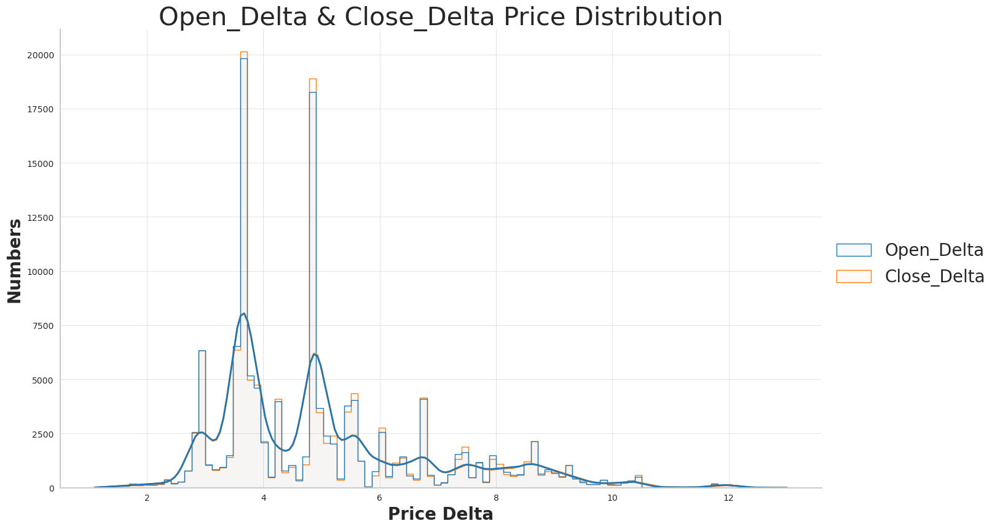

In [50]:
fig = plt.figure(figsize=(12, 5))
plt.rc('axes', titlesize= 30 )
sns.set_style('whitegrid')
sns.set_context(rc={'legend.fontsize': 20.0})

sns.displot(
            data[['Open_Delta', 'Close_Delta']],
            height=8,
            aspect=1.7,
            kde=True,
            element="step",
            bins=100,
            alpha=0.03,

)

plt.title('Open_Delta & Close_Delta Price Distribution')
plt.xlabel('Price Delta', size= 20)
plt.ylabel('Numbers', size= 20)
plt.show();

## Create start of day and week

In [52]:
# Create a new time column by moving it down one row

data['Local_time_T_shipt_1_Down'] = data['Local_time_T'].shift(1)
data["Local_time_T_Delta"] = data["Local_time_T"] - data["Local_time_T_shipt_1_Down"]
print(data)

        Open_Bid  High_Bid  Low_Bid  Close_Bid  Volume_Bid  Open_Ask  \
199       1896.0    1896.0   1894.4     1894.4     0.02470    1903.6   
200       1894.4    1894.4   1893.6     1893.8     0.02015    1901.9   
201       1893.8    1894.4   1893.8     1894.3     0.01690    1901.4   
202       1894.4    1894.9   1894.2     1894.9     0.01690    1902.1   
203       1895.0    1895.9   1895.0     1895.7     0.02275    1902.6   
...          ...       ...      ...        ...         ...       ...   
131035    2908.8    2909.3   2906.7     2908.8     0.03577    2916.0   
131036    2908.0    2908.8   2908.0     2908.1     0.02793    2915.3   
131037    2908.2    2908.2   2905.9     2906.7     0.03381    2915.5   
131038    2906.8    2907.1   2905.3     2905.5     0.04900    2914.1   
131039    2905.6    2906.2   2905.1     2906.1     0.03528    2912.9   

        High_Ask  Low_Ask  Close_Ask  Volume_Ask  ...   EMA_50_Bid  \
199       1903.7   1901.9     1902.0     0.02736  ...  1892.31741

In [53]:
# The start of the year is the start of a week
# Therefore, we change the time interval to 2 days (the duration of the weekend).

data['Local_time_T_Delta'].iloc[0] = "2 days 01:05:00"
print(data['Local_time_T_Delta'].iloc[0])

2 days 01:05:00


/tmp/ipykernel_4579/793878446.py:4: FutureWarning:

ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy




In [54]:
print(data[["Local_time_T_Delta"]][data["Local_time_T_Delta"] > "0 days 00:05:00"].value_counts(sort=False))

Local_time_T_Delta
2 days 01:05:00       1
Name: count, dtype: int64


In [55]:
new_day = data[["Local_time_T_Delta"]][data["Local_time_T_Delta"] > "0 days 00:05:00"]
print(new_day["Local_time_T_Delta"].value_counts(sort=False))

Local_time_T_Delta
2 days 01:05:00    1
Name: count, dtype: int64


In [56]:
data["New_day"] = 0
data["New_week"] = 0

In [57]:
print(data[["Local_time_T_Delta"]][data["Local_time_T_Delta"] > "1 days 00:00:00"].value_counts(sort=False))
new_week = data[data["Local_time_T_Delta"] > "1 days 00:00:00"]
print(new_week["Local_time_T_Delta"].value_counts(sort=False))

Local_time_T_Delta
2 days 01:05:00       1
Name: count, dtype: int64
Local_time_T_Delta
2 days 01:05:00    1
Name: count, dtype: int64


In [58]:
data.loc[data["Local_time_T_Delta"] > "0 days 00:05:00", "New_day"] = 1
print(data[data["New_day"] == 1])

     Open_Bid  High_Bid  Low_Bid  Close_Bid  Volume_Bid  Open_Ask  High_Ask  \
199    1896.0    1896.0   1894.4     1894.4      0.0247    1903.6    1903.7   

     Low_Ask  Close_Ask  Volume_Ask  ... Volume_Delta  Volume_Delta_abs  \
199   1901.9     1902.0     0.02736  ...      0.00266           0.00266   

     Open_Delta  High_Delta  Low_Delta  Close_Delta  \
199         7.6         7.7        7.5          7.6   

     Local_time_T_shipt_1_Down  Local_time_T_Delta  New_day  New_week  
199                        NaT     2 days 01:05:00        1         0  

[1 rows x 45 columns]


In [59]:
data.loc[data["Local_time_T_Delta"] > "1 days 00:00:00", "New_week"] = 1
print(data[data["New_week"] == 1])

     Open_Bid  High_Bid  Low_Bid  Close_Bid  Volume_Bid  Open_Ask  High_Ask  \
199    1896.0    1896.0   1894.4     1894.4      0.0247    1903.6    1903.7   

     Low_Ask  Close_Ask  Volume_Ask  ... Volume_Delta  Volume_Delta_abs  \
199   1901.9     1902.0     0.02736  ...      0.00266           0.00266   

     Open_Delta  High_Delta  Low_Delta  Close_Delta  \
199         7.6         7.7        7.5          7.6   

     Local_time_T_shipt_1_Down  Local_time_T_Delta  New_day  New_week  
199                        NaT     2 days 01:05:00        1         1  

[1 rows x 45 columns]


In [60]:
# drop the columns that are no longer needed,
# since the time series is regular
# (each line is the next minute, except for the marked lines in the New_day and New_week columns

data2 = data.drop(['Local_time_T', 'Local_time_T_shipt_1_Down', 'Local_time_T_Delta'],axis=1)
print(data2.info())
data = []

<class 'pandas.core.frame.DataFrame'>
Index: 130841 entries, 199 to 131039
Data columns (total 42 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Open_Bid              130841 non-null  float64
 1   High_Bid              130841 non-null  float64
 2   Low_Bid               130841 non-null  float64
 3   Close_Bid             130841 non-null  float64
 4   Volume_Bid            130841 non-null  float64
 5   Open_Ask              130841 non-null  float64
 6   High_Ask              130841 non-null  float64
 7   Low_Ask               130841 non-null  float64
 8   Close_Ask             130841 non-null  float64
 9   Volume_Ask            130841 non-null  float64
 10  Alligator_Jaw_Ask     130841 non-null  float64
 11  Alligator_Teeth_Ask   130841 non-null  float64
 12  Alligator_Lips_Ask    130841 non-null  float64
 13  MACD_Ask              130841 non-null  float64
 14  MACD_Signal_Ask       130841 non-null  float64
 15  MAC

## Read hourly or daily csv for analysis

In [62]:
# Take 1-hour and 1-day data (Gold price and Volume 1st 6 months of 2024)

Ask_1h = pd.read_csv("ETHGBP_Hourly_Ask_2024.01.01_2024.12.04.csv")
Ask_1d = pd.read_csv("ETHGBP_Daily_Ask_2023.03.14_2024.12.03.csv")

In [63]:
Ask_1h.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8111 entries, 0 to 8110
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time (UTC)  8111 non-null   object 
 1   Open        8111 non-null   float64
 2   High        8111 non-null   float64
 3   Low         8111 non-null   float64
 4   Close       8111 non-null   float64
 5   Volume      8111 non-null   float64
dtypes: float64(5), object(1)
memory usage: 380.3+ KB


In [64]:
Ask_1d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 631 entries, 0 to 630
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time (UTC)  631 non-null    object 
 1   Open        631 non-null    float64
 2   High        631 non-null    float64
 3   Low         631 non-null    float64
 4   Close       631 non-null    float64
 5   Volume      631 non-null    float64
dtypes: float64(5), object(1)
memory usage: 29.7+ KB


In [65]:
# Add a column with hourly volatility

Ask_1h['Volatility'] = Ask_1h['High'] - Ask_1h['Low']

In [66]:
# Add a column with dayly volatility

Ask_1d['Volatility'] = Ask_1d['High'] - Ask_1d['Low']

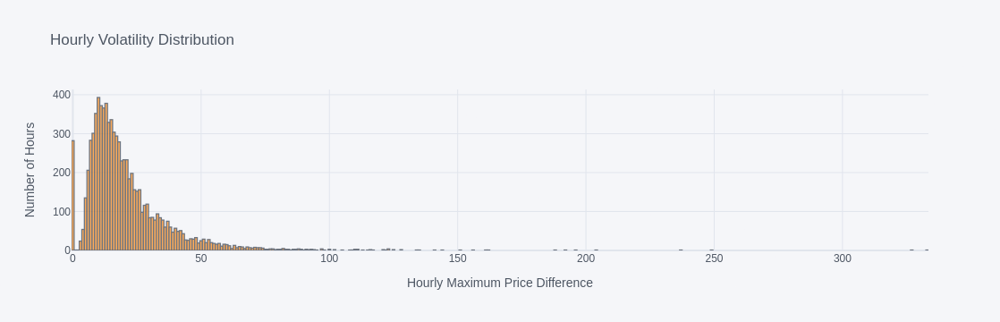

In [67]:
Ask_1h[['Volatility']].iplot(
    kind = 'hist',
    barmode = 'overlay',
    xTitle = 'Hourly Maximum Price Difference',
    yTitle = 'Number of Hours',
    title = 'Hourly Volatility Distribution')

In [68]:
Ask_1h['Volatility'].describe()

count    8111.000000
mean       20.602293
std        17.427943
min         0.000000
25%        10.400000
50%        16.300000
75%        25.500000
max       332.800000
Name: Volatility, dtype: float64

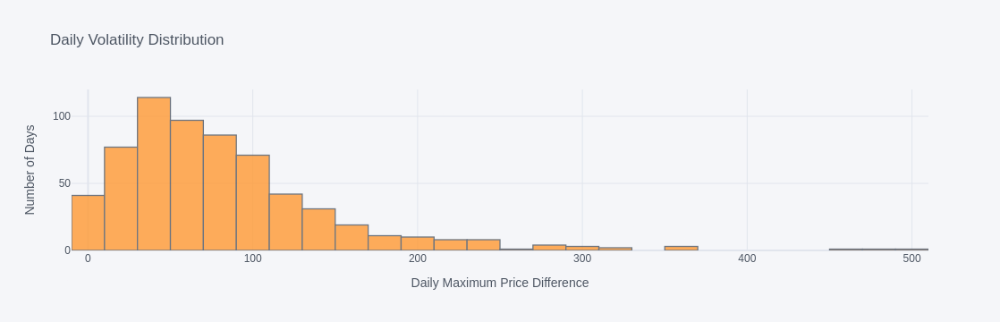

In [69]:
Ask_1d[['Volatility']].iplot(
    kind = 'hist',
    barmode = 'overlay',
    xTitle = 'Daily Maximum Price Difference',
    yTitle = 'Number of Days',
    title = 'Daily Volatility Distribution')

In [70]:
Ask_1d['Volatility'].describe()

Ask_1h = []
Ask_1d = []

## Rename output columns

In [72]:
data2['Y_High_Bid'] = data2['High_Bid']
data2['Y_Low_Ask'] = data2['Low_Ask']

In [73]:
# create output vector of answers
#data2["Y_High_Bid"] = data2["High_Bid"]
#data2["Y_Low_Ask"] = data2["Low_Bid"] + data2["Low_Delta"]
#print(data2)

## Normalization

In [75]:
# Max price is Max High_Ask = High_Bid + High_Delta
# Min price is Min Low_Bid

# Max Volume = Max{Volume_Bid, Volume_Ask}
# Min Volume = 0

# Max_Delta = Max{Open_Delta, High_Delta, Low_Delta, Close_Delta}
# Min_Delta = Min{Open_Delta, High_Delta, Low_Delta, Close_Delta}
#data_length = len(data)
#print(data_length)

In [76]:
#train_size = int(round(data_length*0.8, -3))
#print(train_size)

In [77]:
#train = data2.iloc[:train_size]
#print(train.shape)

In [78]:
#max_price = (train["High_Bid"] + train["High_Delta"]).max()
#print(max_price)

max_price = (data2['High_Ask']).max()
max_price

2940.0

In [79]:
#min_price = train["Low_Bid"].min()
#print(min_price)

min_price = data2['Low_Bid'].min()
min_price

1633.4

In [80]:
#max_volume = max(max(train["Volume_Bid"]), max(train["Volume_Ask"]))
#print(max_volume)

max_volume = max(max(data2['Volume_Bid']), max(data2['Volume_Ask']))
max_volume

0.31737

In [81]:
#max_Delta = max(max(train["Open_Delta"]), max(train["High_Delta"]), max(train["Low_Delta"]), max(train["Close_Delta"]))
#print(max_Delta)

max_Delta = max(max(data2['Open_Delta']), max(data2['High_Delta']), max(data2['Low_Delta']), max(data2['Close_Delta']))
max_Delta

13.0

In [82]:
max_Delta = round(max_Delta, 3)
print(max_Delta)

13.0


In [83]:
min_Delta = min(min(data2['Open_Delta']), min(data2['High_Delta']), min(data2['Low_Delta']), min(data2['Close_Delta']))
min_Delta

1.099999999999909

In [84]:
min_Delta = round(min_Delta, 3)
min_Delta

1.1

In [85]:
#max_volume_Delta = train["Volume_Delta"].max()
#print(max_volume_Delta)

max_volume_Delta = data2['Volume_Delta'].max()
max_volume_Delta

0.1251

In [86]:
max_volume_Delta = round(max_volume_Delta, 5)
max_volume_Delta

0.1251

In [87]:
#min_volume_Delta = train["Volume_Delta"].min()
#print(min_volume_Delta)

min_volume_Delta = data2['Volume_Delta'].min()
min_volume_Delta

-0.11769

In [88]:
min_volume_Delta = round(min_volume_Delta, 5)
min_volume_Delta

-0.11769

In [89]:
#max_volume_Delta_abs = train["Volume_Delta_abs"].max()
#print(max_volume_Delta_abs)

max_volume_Delta_abs = data2['Volume_Delta_abs'].max()
max_volume_Delta_abs

0.1251

In [90]:
max_volume_Delta_abs = round(max_volume_Delta_abs, 5)
max_volume_Delta_abs

0.1251

In [91]:
#min_volume_Delta_abs = train["Volume_Delta_abs"].min()
#print(min_volume_Delta_abs)

min_volume_Delta_abs = data2['Volume_Delta_abs'].min()
min_volume_Delta_abs

0.0

In [92]:
# normalisation
# using the normalisation formula gives better results compared to just dividing by a certain number like below
data2['Open_Bid'] = ( data2['Open_Bid'] - min_price ) / (max_price-min_price)
data2['Open_Ask'] = ( data2['Open_Ask'] - min_price ) / (max_price-min_price)
data2['High_Bid']  = ( data2['High_Bid']  - min_price ) / (max_price-min_price)
data2['High_Ask']  = ( data2['High_Ask']  - min_price ) / (max_price-min_price)
data2['Low_Bid']   = ( data2['Low_Bid']   - min_price ) / (max_price-min_price)
data2['Low_Ask']   = ( data2['Low_Ask']   - min_price ) / (max_price-min_price)
data2['Close_Bid'] = ( data2['Close_Bid'] - min_price ) / (max_price-min_price)
data2['Close_Ask'] = ( data2['Close_Ask'] - min_price ) / (max_price-min_price)
data2['Y_High_Bid'] = ( data2['Y_High_Bid'] - min_price ) / (max_price-min_price)
data2['Y_Low_Ask']  = ( data2['Y_Low_Ask']  - min_price ) / (max_price-min_price)

#data2['Open_Bid'] = ( data2['Open_Bid'] / 10)
#data2['Open_Ask'] = ( data2['Open_Ask'] / 10)
#data2['High_Bid']  = ( data2['High_Bid']  / 10)
#data2['High_Ask']  = ( data2['High_Ask']  / 10)
#data2['Low_Bid']   = ( data2['Low_Bid']   / 10)
#data2['Low_Ask']   = ( data2['Low_Ask']   / 10)
#data2['Close_Bid'] = ( data2['Close_Bid'] / 10)
#data2['Close_Ask'] = ( data2['Close_Ask'] / 10)
#data2['Y_High_Bid'] = ( data2['Y_High_Bid'] / 10)
#data2['Y_Low_Ask']  = ( data2['Y_Low_Ask']  / 10)

data2['Volume_Ask']  = data2['Volume_Ask'] / max_volume
data2['Volume_Bid']  = data2['Volume_Bid'] / max_volume

data2['Volume_Delta'] = ( data2['Volume_Delta'] - min_volume_Delta ) / (max_volume_Delta-min_volume_Delta)

data2['Volume_Delta_abs']  = data2['Volume_Delta_abs'] / max_volume_Delta_abs

data2['Open_Delta']  = ( max_Delta - data2['Open_Delta'] )  / (max_Delta-min_Delta)
data2['High_Delta']  = ( max_Delta - data2['High_Delta'] )  / (max_Delta-min_Delta)
data2['Low_Delta']   = ( max_Delta - data2['Low_Delta'] )   / (max_Delta-min_Delta)
data2['Close_Delta'] = ( max_Delta - data2['Close_Delta'] ) / (max_Delta-min_Delta)

# Step 2: Min-Max Normalization for each indicator
def min_max_normalize(series):
    return (series - series.min()) / (series.max() - series.min())

# Normalize the Ask-related indicators
data2['Alligator_Jaw_Ask'] = min_max_normalize(data2['Alligator_Jaw_Ask'])
data2['Alligator_Teeth_Ask'] = min_max_normalize(data2['Alligator_Teeth_Ask'])
data2['Alligator_Lips_Ask'] = min_max_normalize(data2['Alligator_Lips_Ask'])

data2['MACD_Ask'] = min_max_normalize(data2['MACD_Ask'])
data2['MACD_Signal_Ask'] = min_max_normalize(data2['MACD_Signal_Ask'])
data2['MACD_Hist_Ask'] = min_max_normalize(data2['MACD_Hist_Ask'])

data2['RSI_Ask'] = min_max_normalize(data2['RSI_Ask'])

data2['Bollinger_Upper_Ask'] = min_max_normalize(data2['Bollinger_Upper_Ask'])
data2['Bollinger_Middle_Ask'] = min_max_normalize(data2['Bollinger_Middle_Ask'])
data2['Bollinger_Lower_Ask'] = min_max_normalize(data2['Bollinger_Lower_Ask'])

data2['EMA_50_Ask'] = min_max_normalize(data2['EMA_50_Ask'])
data2['EMA_200_Ask'] = min_max_normalize(data2['EMA_200_Ask'])

# Normalize the Bid-related indicators
data2['Alligator_Jaw_Bid'] = min_max_normalize(data2['Alligator_Jaw_Bid'])
data2['Alligator_Teeth_Bid'] = min_max_normalize(data2['Alligator_Teeth_Bid'])
data2['Alligator_Lips_Bid'] = min_max_normalize(data2['Alligator_Lips_Bid'])

data2['MACD_Bid'] = min_max_normalize(data2['MACD_Bid'])
data2['MACD_Signal_Bid'] = min_max_normalize(data2['MACD_Signal_Bid'])
data2['MACD_Hist_Bid'] = min_max_normalize(data2['MACD_Hist_Bid'])

data2['RSI_Bid'] = min_max_normalize(data2['RSI_Bid'])

data2['Bollinger_Upper_Bid'] = min_max_normalize(data2['Bollinger_Upper_Bid'])
data2['Bollinger_Middle_Bid'] = min_max_normalize(data2['Bollinger_Middle_Bid'])
data2['Bollinger_Lower_Bid'] = min_max_normalize(data2['Bollinger_Lower_Bid'])

data2['EMA_50_Bid'] = min_max_normalize(data2['EMA_50_Bid'])
data2['EMA_200_Bid'] = min_max_normalize(data2['EMA_200_Bid'])

print(data2)

        Open_Bid  High_Bid   Low_Bid  Close_Bid  Volume_Bid  Open_Ask  \
199     0.200980  0.200980  0.199755   0.199755    0.077827  0.206796   
200     0.199755  0.199755  0.199143   0.199296    0.063491  0.205495   
201     0.199296  0.199755  0.199296   0.199679    0.053250  0.205113   
202     0.199755  0.200138  0.199602   0.200138    0.053250  0.205648   
203     0.200214  0.200903  0.200214   0.200750    0.071683  0.206031   
...          ...       ...       ...        ...         ...       ...   
131035  0.976121  0.976504  0.974514   0.976121    0.112708  0.981632   
131036  0.975509  0.976121  0.975509   0.975585    0.088005  0.981096   
131037  0.975662  0.975662  0.973902   0.974514    0.106532  0.981249   
131038  0.974591  0.974820  0.973443   0.973596    0.154394  0.980178   
131039  0.973672  0.974131  0.973289   0.974055    0.111164  0.979259   

        High_Ask   Low_Ask  Close_Ask  Volume_Ask  ...  Volume_Delta  \
199     0.206873  0.205495   0.205572    0.086209  

## Memory size reduction

In [94]:
# memory size reduction

columns_float = [
    # Price-related columns
    'Open_Bid', 'Open_Ask', 'High_Bid', 'High_Ask', 'Low_Ask', 'Low_Bid', 'Close_Ask', 'Close_Bid',

    # Volume-related columns
    'Volume_Bid', 'Volume_Ask', 'Volume_Delta', 'Volume_Delta_abs',

    # Delta-related columns
    'Open_Delta', 'High_Delta', 'Low_Delta', 'Close_Delta',

    # Target-related columns (Y_High_Bid, Y_Low_Ask)
    'Y_High_Bid', 'Y_Low_Ask',

    # Alligator indicators for Ask and Bid
    'Alligator_Jaw_Ask', 'Alligator_Teeth_Ask', 'Alligator_Lips_Ask',
    'Alligator_Jaw_Bid', 'Alligator_Teeth_Bid', 'Alligator_Lips_Bid',

    # MACD for Ask and Bid
    'MACD_Ask', 'MACD_Signal_Ask', 'MACD_Hist_Ask',
    'MACD_Bid', 'MACD_Signal_Bid', 'MACD_Hist_Bid',

    # RSI for Ask and Bid
    'RSI_Ask', 'RSI_Bid',

    # Bollinger Bands for Ask and Bid
    'Bollinger_Upper_Ask', 'Bollinger_Middle_Ask', 'Bollinger_Lower_Ask',
    'Bollinger_Upper_Bid', 'Bollinger_Middle_Bid', 'Bollinger_Lower_Bid',

    # EMA for Ask and Bid (50 and 200 period)
    'EMA_50_Ask', 'EMA_200_Ask',
    'EMA_50_Bid', 'EMA_200_Bid'
]

columns_integer =['New_day', 'New_week']

for column in columns_float:
    data2[column] = pd.to_numeric(data2[column], downcast="float")
for column in columns_integer:
    data2[column] = pd.to_numeric(data2[column], downcast="integer")

print(data2.info())

<class 'pandas.core.frame.DataFrame'>
Index: 130841 entries, 199 to 131039
Data columns (total 44 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Open_Bid              130841 non-null  float32
 1   High_Bid              130841 non-null  float32
 2   Low_Bid               130841 non-null  float32
 3   Close_Bid             130841 non-null  float32
 4   Volume_Bid            130841 non-null  float32
 5   Open_Ask              130841 non-null  float32
 6   High_Ask              130841 non-null  float32
 7   Low_Ask               130841 non-null  float32
 8   Close_Ask             130841 non-null  float32
 9   Volume_Ask            130841 non-null  float32
 10  Alligator_Jaw_Ask     130841 non-null  float32
 11  Alligator_Teeth_Ask   130841 non-null  float32
 12  Alligator_Lips_Ask    130841 non-null  float32
 13  MACD_Ask              130841 non-null  float32
 14  MACD_Signal_Ask       130841 non-null  float32
 15  MAC

<Figure size 1200x500 with 0 Axes>

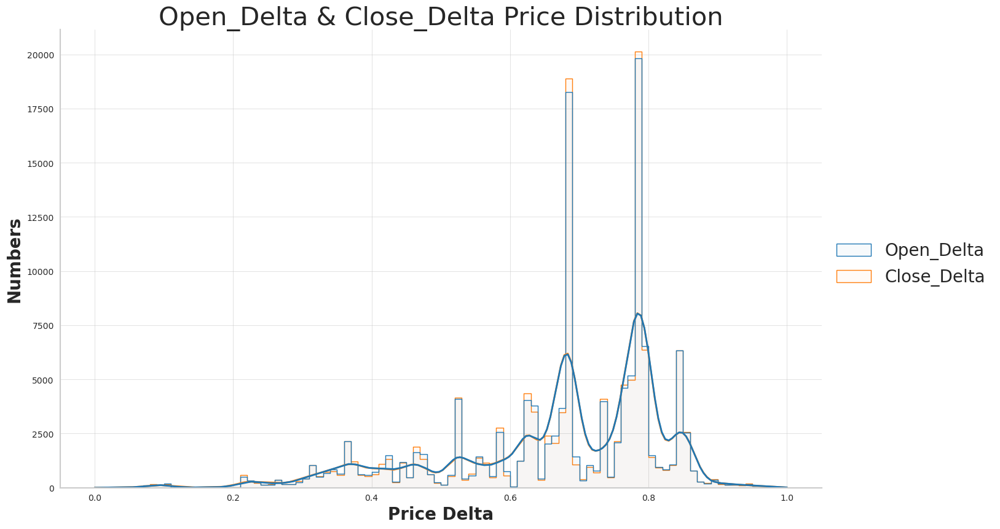

In [95]:
# inverse normalisation of price deltas, the minimum difference is more interesting

fig = plt.figure(figsize=(12, 5))
plt.rc('axes', titlesize= 30 )
sns.set_style('whitegrid')
sns.set_context(rc={'legend.fontsize': 20.0})

sns.displot(
            data2[['Open_Delta', 'Close_Delta']],
            height=8,
            aspect=1.7,
            kde=True,
            element="step",
            bins=100,
            alpha=0.03,

)

plt.title('Open_Delta & Close_Delta Price Distribution')
plt.xlabel('Price Delta', size= 20)
plt.ylabel('Numbers', size= 20)
plt.show();

# Step 2 Regression

## 3D

### Data transformation

In [99]:
### data transformation

# We will predict the Highest and Lowest prices DURING the next 5 minutes.

# To do this in the data output (vector of answers), we shift prices sequentially to 15 minutes up,
# and find max and min prices during these 15 minutes
# Then you need to delete the 3 last rows since there are no prices for the next 15 minutes.
# Therefore, we will create an array of answers "data_ay" with the Highest and Lowest prices shifted sequentially to 3 rows up.

n = data2.shape[0]
p = data2.shape[1]

print(n)
print(p)

data_ax = data2.drop(["Y_High_Bid", "Y_Low_Ask", 'High_Bid', 'Low_Ask'], axis = 1)
print(data_ax.info())
print(data_ax.shape)

data_ay = data2[["Y_High_Bid", "Y_Low_Ask"]]
print(data_ay.shape)
print(data_ay.head)

data_ay = data_ay.shift(-1)

130841
44
<class 'pandas.core.frame.DataFrame'>
Index: 130841 entries, 199 to 131039
Data columns (total 40 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Open_Bid              130841 non-null  float32
 1   Low_Bid               130841 non-null  float32
 2   Close_Bid             130841 non-null  float32
 3   Volume_Bid            130841 non-null  float32
 4   Open_Ask              130841 non-null  float32
 5   High_Ask              130841 non-null  float32
 6   Close_Ask             130841 non-null  float32
 7   Volume_Ask            130841 non-null  float32
 8   Alligator_Jaw_Ask     130841 non-null  float32
 9   Alligator_Teeth_Ask   130841 non-null  float32
 10  Alligator_Lips_Ask    130841 non-null  float32
 11  MACD_Ask              130841 non-null  float32
 12  MACD_Signal_Ask       130841 non-null  float32
 13  MACD_Hist_Ask         130841 non-null  float32
 14  RSI_Ask               130841 non-null  float3

In [100]:
# create new colomns: MIN_Lowest(Low_Ask) and MAX_Highest(High_Bid) prices of DURING NEXT 5 minutes

# Forward-looking window
indexer = pd.api.indexers.FixedForwardWindowIndexer(window_size=120)

data_ay['Y_High_Bid_120'] = data_ay['Y_High_Bid'].rolling(window=indexer).max()
data_ay['Y_Low_Ask_120']  = data_ay['Y_Low_Ask'].rolling(window=indexer).min()

data_ay = data_ay.drop(["Y_High_Bid", "Y_Low_Ask"], axis = 1)

In [102]:
# delete the 5 last rows in data_ay (because we don't have answers for the last 5 minutes)

for i in range(120):
    data_ay.drop(data_ay.shape[0]-1, axis=0, inplace=True)

# delete the last 5 rows in data_ax (because we don't have answers for the last 5 minutes)

for i in range(120):
    data_ax.drop(data_ax.shape[0]-1, axis=0, inplace=True)

In [103]:
data_ay.shape

(130721, 2)

In [104]:
data_ax.info()

<class 'pandas.core.frame.DataFrame'>
Index: 130721 entries, 199 to 131039
Data columns (total 40 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Open_Bid              130721 non-null  float32
 1   Low_Bid               130721 non-null  float32
 2   Close_Bid             130721 non-null  float32
 3   Volume_Bid            130721 non-null  float32
 4   Open_Ask              130721 non-null  float32
 5   High_Ask              130721 non-null  float32
 6   Close_Ask             130721 non-null  float32
 7   Volume_Ask            130721 non-null  float32
 8   Alligator_Jaw_Ask     130721 non-null  float32
 9   Alligator_Teeth_Ask   130721 non-null  float32
 10  Alligator_Lips_Ask    130721 non-null  float32
 11  MACD_Ask              130721 non-null  float32
 12  MACD_Signal_Ask       130721 non-null  float32
 13  MACD_Hist_Ask         130721 non-null  float32
 14  RSI_Ask               130721 non-null  float32
 15  Bol

In [105]:
data_ax.shape

(130721, 40)

In [106]:
# Create inputs Numpy

data_a = np.array(data_ax)

with np.printoptions(precision=4):
    print("data_a:")
    print(data_a[:2,:])
    print('\n')
    print(data_a[-2:,:])

print("numpy size: = ", data_a.shape)
print("type: ", data_a.dtype)

data_a:
[[0.201  0.1998 0.1998 0.0778 0.2068 0.2069 0.2056 0.0862 0.186  0.1895
  0.1919 0.5027 0.486  0.5207 0.5285 0.1822 0.1866 0.1942 0.1797 0.1759
  0.1931 0.197  0.2004 0.5356 0.5121 0.5792 0.5309 0.1856 0.1929 0.2037
  0.1843 0.1788 0.4957 0.0213 0.4538 0.4454 0.4622 0.4538 1.     1.    ]
 [0.1998 0.1991 0.1993 0.0635 0.2055 0.2055 0.205  0.0703 0.1864 0.19
  0.192  0.4966 0.4852 0.5046 0.4922 0.1821 0.1866 0.1944 0.1797 0.1759
  0.1934 0.1975 0.2005 0.5309 0.5115 0.5668 0.4987 0.1856 0.193  0.2039
  0.1844 0.1787 0.4937 0.0173 0.4622 0.4622 0.4454 0.4622 0.     0.    ]]


[[0.9746 0.9734 0.9736 0.1544 0.9802 0.9804 0.9792 0.1701 0.99   0.9868
  0.985  0.4256 0.4077 0.5042 0.3799 0.9852 0.9898 0.9901 0.9953 0.9998
  0.9905 0.988  0.9864 0.4678 0.4399 0.57   0.3793 0.9869 0.9906 0.9912
  0.9956 0.9998 0.5053 0.04   0.479  0.479  0.479  0.479  0.     0.    ]
 [0.9737 0.9733 0.9741 0.1112 0.9793 0.9796 0.9796 0.1225 0.9898 0.9866
  0.9848 0.4227 0.4065 0.4989 0.3989 0.9847 0.9894 0

In [107]:
# Create outputs Numpy

data_y = np.array(data_ay)

print("data_a:")
print(data_y[:3,:])
print('\n')
print(data_y[-3:,:])

print("numpy size: = ", data_y.shape)
print("type: ", data_y.dtype)

data_a:
[[0.20159192 0.19876014]
 [0.20159192 0.19876014]
 [0.20159192 0.19876014]]


[[nan nan]
 [nan nan]
 [nan nan]]
numpy size: =  (130721, 2)
type:  float64


In [108]:
n_small = 130000 # reduced dataset to 6053 rows
N = 50 # sliding window depth

L = n_small - N # number of sliding window slices
t = data_a.shape[1] # features number
print("Size of a three-dimensional inputs tensor: ", L, N, t)

# create imputs zeros 3D tensors with 'float32'

data_b = np.zeros( (L, N, t), dtype= 'float32' )

# create a two-dimensional zeros vector of answers - normalised the High_Bid and Low_Ask prices DURING next 15 minutes

Y = np.zeros((L, 2), dtype= 'float32') # We will predict two prices - normalised High_Bid and normalised Low_Ask

Size of a three-dimensional inputs tensor:  129950 50 40


In [109]:
# fill the imputs 3D tansor (data_b)
# and the array of answers Y

#print('L = n - N = ', n-N, L)
print('L = n_small - N - 3 = ', n_small-N-3, L)
#for k in tqdm(range(L-1)):
for k in tqdm(range(L)):
    data_b[k, :, :] = data_a[k:k+N, :]

    Y[k,0] = data_y[k+N-1,0]   # normalised Y_High_Bid - max 15 minutes future price
    Y[k,1] = data_y[k+N-1,1]   # normalised Y_Low_Ask -  min 15 minutes future price

print(k) # index value (for control)

print('data_b:', '\n', data_b)
print("Numpy size:        ", data_b.shape, '\n')

print( Y[:5,:])
print( Y[-10:,:])
print(      "Numpy size:         ", Y.shape)

L = n_small - N - 3 =  129947 129950


100%|██████████| 129950/129950 [00:01<00:00, 70470.03it/s]

129949
data_b: 
 [[[0.20097964 0.19975509 0.19975509 ... 0.45378152 1.         1.        ]
  [0.19975509 0.19914281 0.19929588 ... 0.46218488 0.         0.        ]
  [0.19929588 0.19929588 0.19967856 ... 0.45378152 0.         0.        ]
  ...
  [0.19485688 0.19485688 0.19654064 ... 0.45378152 0.         0.        ]
  [0.19661717 0.19661717 0.19699985 ... 0.45378152 0.         0.        ]
  [0.19677025 0.19654064 0.19684678 ... 0.45378152 0.         0.        ]]

 [[0.19975509 0.19914281 0.19929588 ... 0.46218488 0.         0.        ]
  [0.19929588 0.19929588 0.19967856 ... 0.45378152 0.         0.        ]
  [0.19975509 0.19960202 0.20013776 ... 0.45378152 0.         0.        ]
  ...
  [0.19661717 0.19661717 0.19699985 ... 0.45378152 0.         0.        ]
  [0.19677025 0.19654064 0.19684678 ... 0.45378152 0.         0.        ]
  [0.19677025 0.1962345  0.1962345  ... 0.45378152 0.         0.        ]]

 [[0.19929588 0.19929588 0.19967856 ... 0.45378152 0.         0.        ]
  [0.

In [112]:
# Control of the correctness of filling the array Y
# (should show MAX of the normalised prices High_Bid and Low_Ask - during 5 next minutes(step) ahead)

pp = random.randint(50, L) # (any number before 29950) - just to look at the middle of data_b
print('random int = ', pp)

print('data_b:', '\t\t','Y:')
print('Y_High_Bid ','\t\t','Y_High_Bid')

for i in range(15):
    print(data_b[pp+i,N-1,1], '\t\t', Y[pp+i,0])

random int =  127858
data_b: 		 Y:
Y_High_Bid  		 Y_High_Bid
0.9129037 		 0.917955
0.9084647 		 0.917955
0.90877086 		 0.917955
0.90999544 		 0.917955
0.909077 		 0.917955
0.9083882 		 0.917955
0.909077 		 0.917955
0.90900046 		 0.917955
0.9097658 		 0.917955
0.9111434 		 0.917955
0.9088474 		 0.917955
0.90991884 		 0.917955
0.9097658 		 0.917955
0.90945965 		 0.917955
0.9067044 		 0.917955


In [122]:
data = []
data_ax = []
data_ay = []
data_a = []
data_y = []

### Create training and test set

In [128]:
X_train, X_test, y_train, y_test = train_test_split(data_b, Y, test_size = 0.1, shuffle = False, stratify = None, random_state = 101)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(116955, 50, 40)
(116955, 2)
(12995, 50, 40)
(12995, 2)


In [131]:
epochnum = 25
batch_size = 72
patience = 6
validation_split = 0.2

### LSTM

In [117]:
tf.keras.backend.clear_session(
    free_memory=True
)

#### Create model

In [119]:
model = keras.Sequential([
    keras.layers.LSTM(100, activation="relu", input_shape = (50, 40)),
    keras.layers.Dropout(0.3),  # Dropout after the first LSTM layer
    keras.layers.Dense(2)
])

2024-12-15 22:41:34.732929: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [120]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100)            │        56,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           202 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,602 (221.10 KB)

 Trainable params: 56,602 (221.10 KB)

 Non-trainable params: 0 (0.00 B)

In [121]:
model.compile(optimizer="nadam", loss="mse", metrics=["mae"])

# Early Stopping parameters

es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_LSTMR.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

In [122]:
history = model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])

2024-12-15 22:41:38.318442: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 748512000 exceeds 10% of free system memory.


Epoch 1/25
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0035 - mae: 0.0336

2024-12-15 22:42:16.650305: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 187128000 exceeds 10% of free system memory.



Epoch 1: val_loss improved from inf to 0.00190, saving model to best_model_LSTMR.keras
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 39s 27ms/step - loss: 0.0035 - mae: 0.0336 - val_loss: 0.0019 - val_mae: 0.0374
Epoch 2/25
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 2.1525e-04 - mae: 0.0109
Epoch 2: val_loss did not improve from 0.00190
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 34s 26ms/step - loss: 2.1524e-04 - mae: 0.0109 - val_loss: 0.0054 - val_mae: 0.0668
Epoch 3/25
1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 1.7800e-04 - mae: 0.0098
Epoch 3: val_loss did not improve from 0.00190
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 34s 26ms/step - loss: 1.7799e-04 - mae: 0.0098 - val_loss: 0.0043 - val_mae: 0.0599
Epoch 4/25
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 1.6680e-04 - mae: 0.0095
Epoch 4: val_loss did not improve from 0.00190
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 35s 27ms/step - loss: 1.6680e-04 - mae: 0.0095 - val_loss: 0.2337 - val_mae: 0.1740
Epoch 5/25
1298/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/s

#### Evaluate

In [124]:
Saved_best_model_LSTM = keras.models.load_model("best_model_LSTMR.keras")

In [125]:
# Evaluate the quality of network training on test data, which the network has NOT seen.

scores_LSTMR = Saved_best_model_LSTM.evaluate(X_test, y_test, verbose=1)
y_pred_LSTMR = Saved_best_model_LSTM.predict(X_test)

scores_LSTMR = list(scores_LSTMR)
scores_LSTMR.append(r2_score(y_test, y_pred_LSTMR))
print(scores_LSTMR)
print("Mean squared error (mse): %.9f " % (scores_LSTMR[0]))
print("Mean absolute error (mae): %.9f " % (scores_LSTMR[1]))
print("R2 Score: %.9f " % (scores_LSTMR[2]))

2024-12-15 22:45:44.380333: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 103960000 exceeds 10% of free system memory.


407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0052 - mae: 0.0625
  1/407 ━━━━━━━━━━━━━━━━━━━━ 59s 147ms/step

2024-12-15 22:45:47.130751: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 103960000 exceeds 10% of free system memory.


407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
[0.005621875170618296, 0.06438076496124268, -0.43683991317756493]
Mean squared error (mse): 0.005621875 
Mean absolute error (mae): 0.064380765 
R2 Score: -0.436839913 


Text(0.5, 0, 'Mean Squared Error')

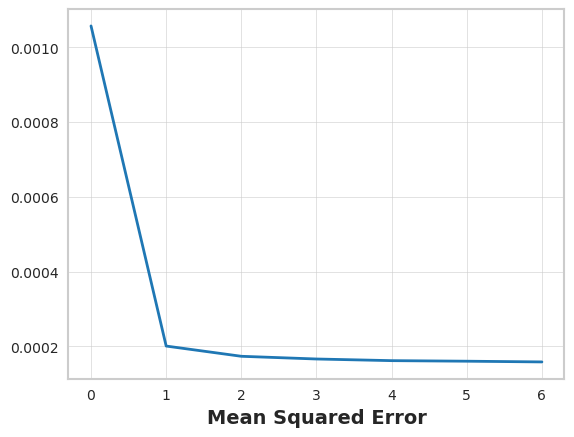

In [126]:
plt.plot(history.history["loss"])
plt.xlabel("Mean Squared Error", size = 14)

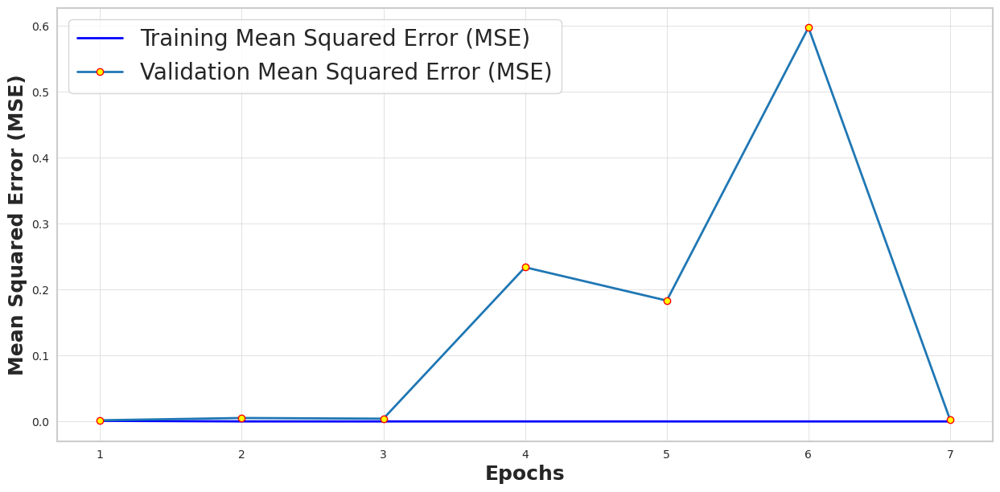

In [127]:
# More detailed MSE graph

history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

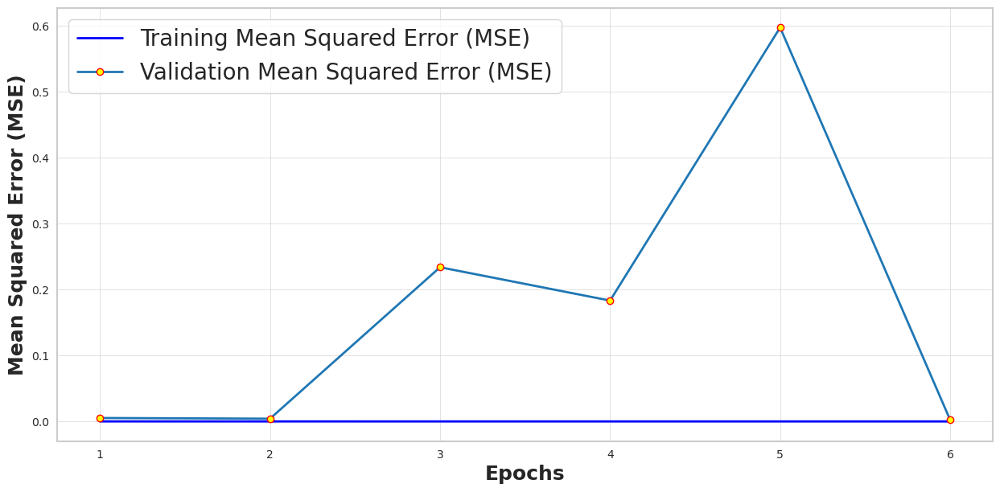

In [128]:
# deleted the 1st epoch
# to examine in detail the results of the remaining epochs

history_dict = history.history

mse_values = history_dict['loss'][1:]
val_mse_values = history_dict['val_loss'][1:]

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

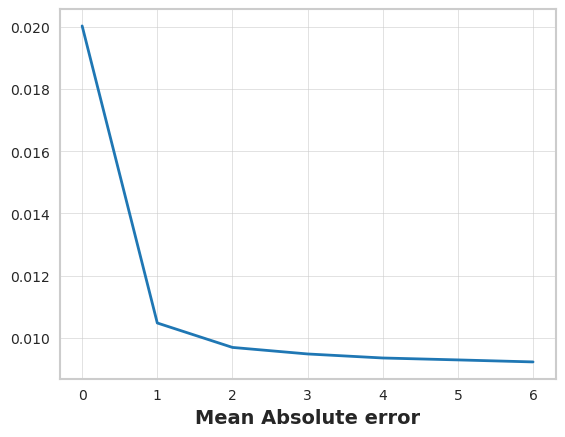

In [129]:
plt.plot(history.history["mae"])
plt.xlabel("Mean Absolute error", size = 14)
plt.show()

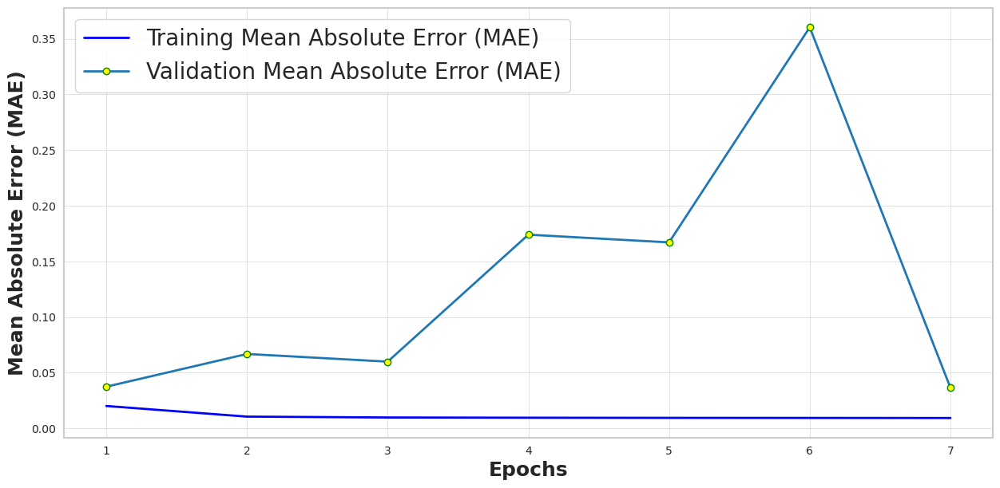

In [130]:
history_dict = history.history

mae_values = history_dict["mae"]
val_mae_values = history_dict["val_mae"]

epochs = range(1, len(mae_values) + 1)
plt.figure(num = 1, figsize = (15, 7))
plt.plot(epochs, mae_values, 'b', label="Training Mean Absolute Error (MAE)")
plt.plot(epochs, val_mae_values, marker='o', markeredgecolor="Green", markerfacecolor="yellow", label = "Validation Mean Absolute Error (MAE)")
plt.xlabel("Epochs", size = 18)
plt.ylabel("Mean Absolute Error (MAE)", size = 18)
plt.legend()
plt.show()

In [131]:
pred = Saved_best_model_LSTM(X_test)
print(pred)

2024-12-15 22:45:51.341055: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 103960000 exceeds 10% of free system memory.


tf.Tensor(
[[0.6063293  0.6045051 ]
 [0.6050137  0.6046349 ]
 [0.6041465  0.603735  ]
 ...
 [0.8437215  0.91491073]
 [0.8447906  0.9155958 ]
 [0.8462601  0.9161857 ]], shape=(12995, 2), dtype=float32)


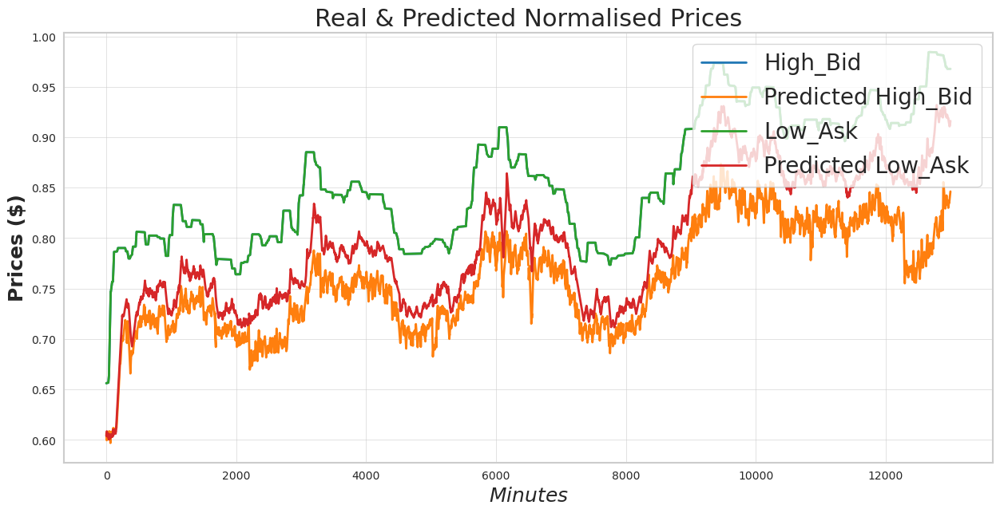

In [132]:
N1=0  # The first minute for the chart
LL = 130000 # Duration (in minutes) for the chart
N2=N1+LL  # the last minute for the chart

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)
line1, = ax1.plot(y_test[N1:N2,0], label='High_Bid')
line2, = ax1.plot(y_pred_LSTMR[N1:N2,0], label='Predicted High_Bid')
line3, = ax1.plot(y_test[N1:N2,0], label='Low_Ask')
line4, = ax1.plot(y_pred_LSTMR[N1:N2,1], label='Predicted Low_Ask')

plt.title('Real & Predicted Normalised Prices', size=22)
plt.ylabel('Prices ($)', size=18)
plt.xlabel('$Minutes$', size=18)
plt.legend(loc='upper right')

plt.show()

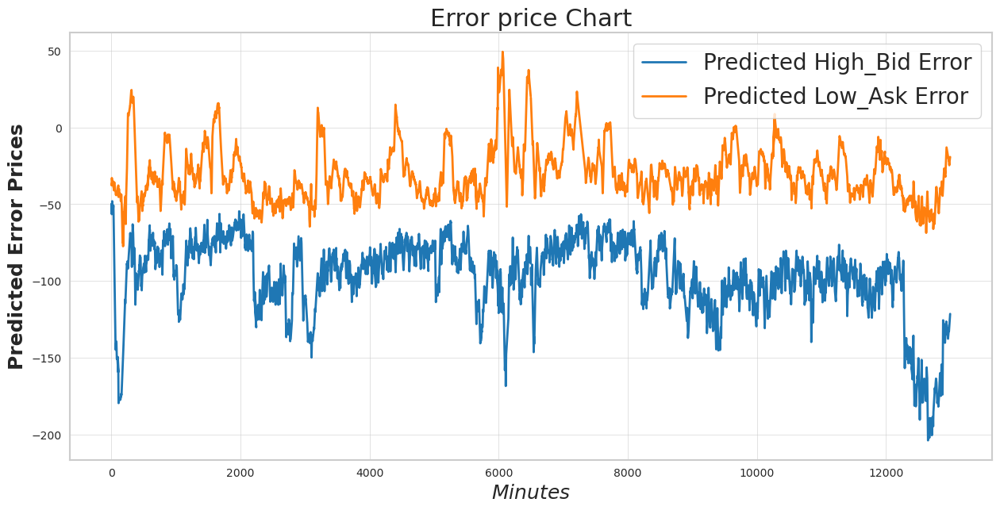

In [133]:
N1=0  # The first minute for the chart
LL = 13000  # leigt (in minutes) for the chart
N2=N1+LL  # the last minute for the chart
# N2 should be < len(pred)

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)

# in $ (absolute price)
a = (y_pred_LSTMR[N1:N2,0] - y_test[N1:N2,0]) * 1000
b = (y_pred_LSTMR[N1:N2,1] - y_test[N1:N2,1]) * 1000

# in %
#a = (pred[N1:N2,0] - y_test[N1:N2,0]) *1000/ average_price *100
#b = (pred[N1:N2,1] - y_test[N1:N2,1]) *1000/ average_price *100


line1, = ax1.plot(a, label='Predicted High_Bid Error')
line2, = ax1.plot(b, label='Predicted Low_Ask Error')

plt.title('Error price Chart', size=22)
plt.ylabel('Predicted Error Prices', size=18)
plt.xlabel('$Minutes$', size=18)
plt.legend(loc='upper right')

plt.show()

### CNN

In [135]:
tf.keras.backend.clear_session(
    free_memory=True
)

#### Create model

In [137]:
model = keras.Sequential([

    keras.layers.Conv1D(50, 9, padding = "same", input_shape = (50, 40), activation = "relu", kernel_initializer = "he_normal"),
    keras.layers.MaxPooling1D(7),
    keras.layers.Conv1D(100, 7, padding = "same", activation = "relu", kernel_initializer = "he_normal"),
    keras.layers.GlobalMaxPooling1D(),
    keras.layers.Dense(25, activation = "relu", kernel_initializer = "he_normal"),

    keras.layers.Dense(2)
])

print(model.summary())

/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 50, 50)         │        18,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 7, 50)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 7, 100)         │        35,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 100)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         2,525 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            52 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,727 (217.68 KB)

 Trainable params: 55,727 (217.68 KB)

 Non-trainable params: 0 (0.00 B)

None


In [138]:
model.compile(optimizer="nadam", loss="mse", metrics=["mae"])

# Early Stopping parameters

es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_CNNR.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

In [139]:
history = model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])

Epoch 1/25
1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0033 - mae: 0.0231
Epoch 1: val_loss improved from inf to 0.00159, saving model to best_model_CNNR.keras
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - loss: 0.0033 - mae: 0.0231 - val_loss: 0.0016 - val_mae: 0.0296
Epoch 2/25
1293/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.5177e-04 - mae: 0.0093
Epoch 2: val_loss did not improve from 0.00159
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 1.5168e-04 - mae: 0.0093 - val_loss: 0.0027 - val_mae: 0.0436
Epoch 3/25
1292/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.1458e-04 - mae: 0.0080
Epoch 3: val_loss did not improve from 0.00159
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 1.1454e-04 - mae: 0.0080 - val_loss: 0.0021 - val_mae: 0.0368
Epoch 4/25
1295/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 9.9908e-05 - mae: 0.0074
Epoch 4: val_loss did not improve from 0.00159
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 9.9896e-05 - mae: 0.0074 - val_loss: 0.0

#### Evaluate

In [141]:
Saved_best_model_CNN = keras.models.load_model("best_model_CNNR.keras")

In [142]:
# Evaluate the quality of network training on test data, which the network has NOT seen.

scores_CNNR = Saved_best_model_CNN.evaluate(X_test, y_test, verbose=1)
y_pred_CNNR = Saved_best_model_CNN.predict(X_test)

scores_CNNR = list(scores_CNNR)
scores_CNNR.append(r2_score(y_test, y_pred_CNNR))
print(scores_CNNR)
print("Mean squared error (mse): %.9f " % (scores_CNNR[0]))
print("Mean absolute error (mae): %.9f " % (scores_CNNR[1]))
print("R2 score: %.9f " % (scores_CNNR[2]))

407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0033 - mae: 0.0482
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
[0.004104651045054197, 0.05480031669139862, -0.02266729906590187]
Mean squared error (mse): 0.004104651 
Mean absolute error (mae): 0.054800317 
R2 score: -0.022667299 


Text(0.5, 0, 'Mean Squared Error')

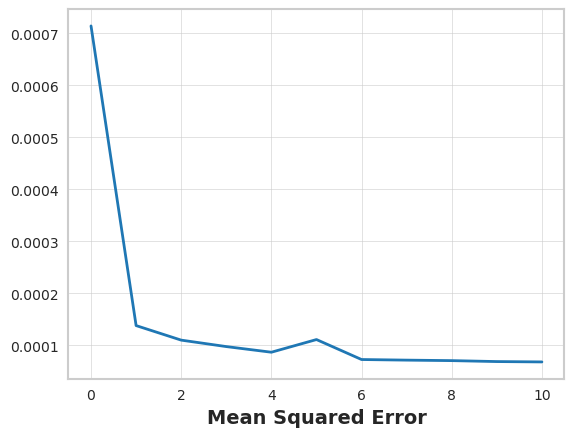

In [143]:
plt.plot(history.history["loss"])
plt.xlabel("Mean Squared Error", size = 14)

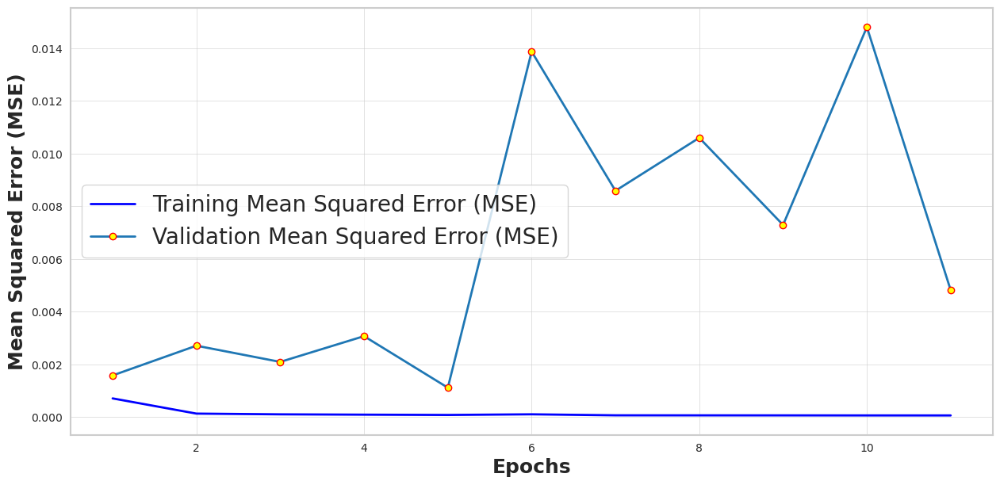

In [144]:
# More detailed MSE graph

history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

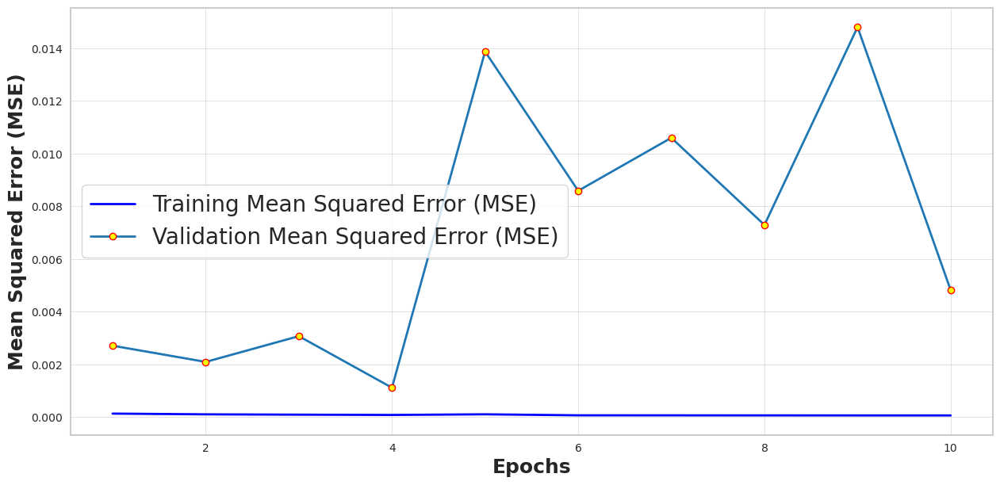

In [145]:
# deleted the 1st epoch
# to examine in detail the results of the remaining epochs

history_dict = history.history

mse_values = history_dict['loss'][1:]
val_mse_values = history_dict['val_loss'][1:]

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

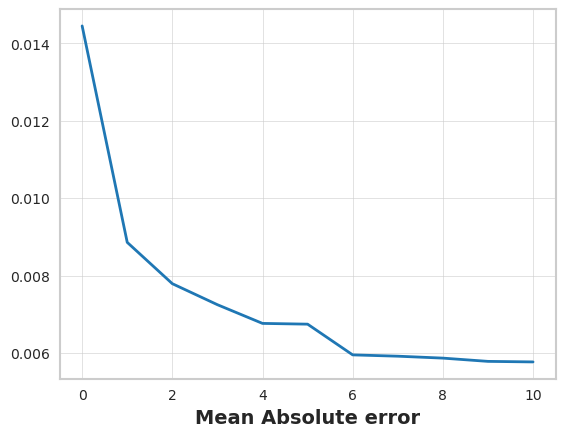

In [146]:
plt.plot(history.history["mae"])
plt.xlabel("Mean Absolute error", size = 14)
plt.show()

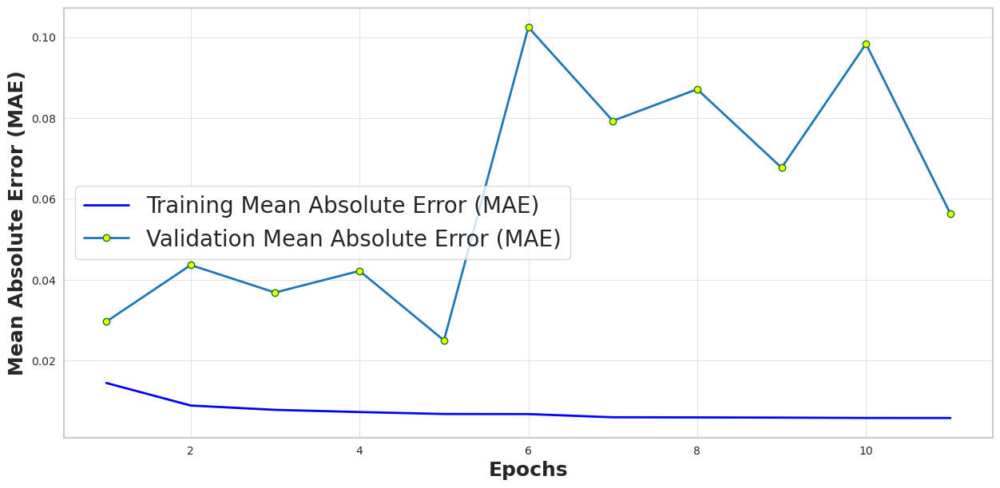

In [147]:
history_dict = history.history

mae_values = history_dict["mae"]
val_mae_values = history_dict["val_mae"]

epochs = range(1, len(mae_values) + 1)
plt.figure(num = 1, figsize = (15, 7))
plt.plot(epochs, mae_values, 'b', label="Training Mean Absolute Error (MAE)")
plt.plot(epochs, val_mae_values, marker='o', markeredgecolor="Green", markerfacecolor="yellow", label = "Validation Mean Absolute Error (MAE)")
plt.xlabel("Epochs", size = 18)
plt.ylabel("Mean Absolute Error (MAE)", size = 18)
plt.legend()
plt.show()

In [148]:
pred = Saved_best_model_CNN(X_test)
print(pred)

tf.Tensor(
[[0.6677868  0.64419246]
 [0.67079836 0.6440711 ]
 [0.6717388  0.64822763]
 ...
 [1.0904684  1.0731976 ]
 [1.0895174  1.0742483 ]
 [1.0923231  1.0789694 ]], shape=(12995, 2), dtype=float32)


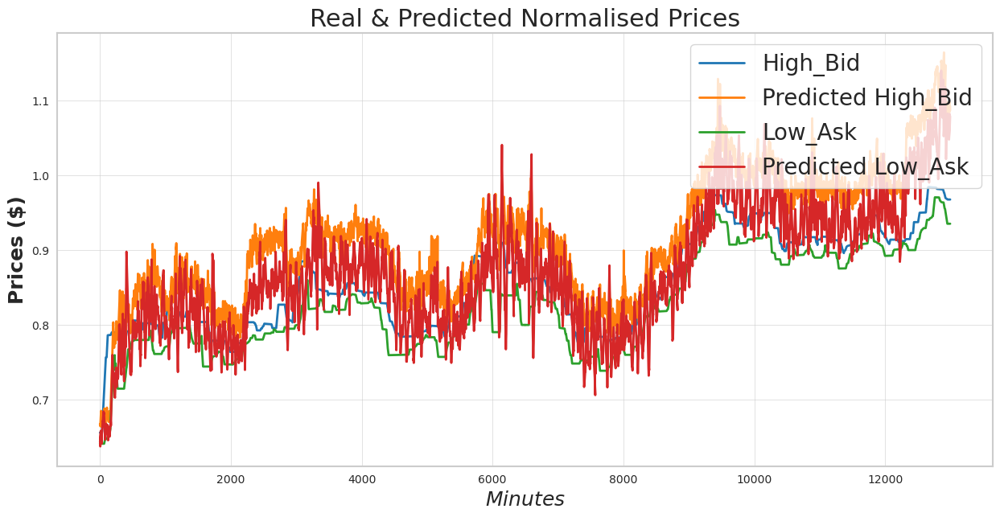

In [149]:
N1=0  # The first minute for the chart
LL = 130000  # Duration (in minutes) for the chart
N2=N1+LL  # the last minute for the chart

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)
line1, = ax1.plot(y_test[N1:N2,0], label='High_Bid')
line2, = ax1.plot(y_pred_CNNR[N1:N2,0], label='Predicted High_Bid')
line3, = ax1.plot(y_test[N1:N2,1], label='Low_Ask')
line4, = ax1.plot(y_pred_CNNR[N1:N2,1], label='Predicted Low_Ask')

plt.title('Real & Predicted Normalised Prices', size=22)
plt.ylabel('Prices ($)', size=18)
plt.xlabel('$Minutes$', size=18)
plt.legend(loc='upper right')

plt.show()

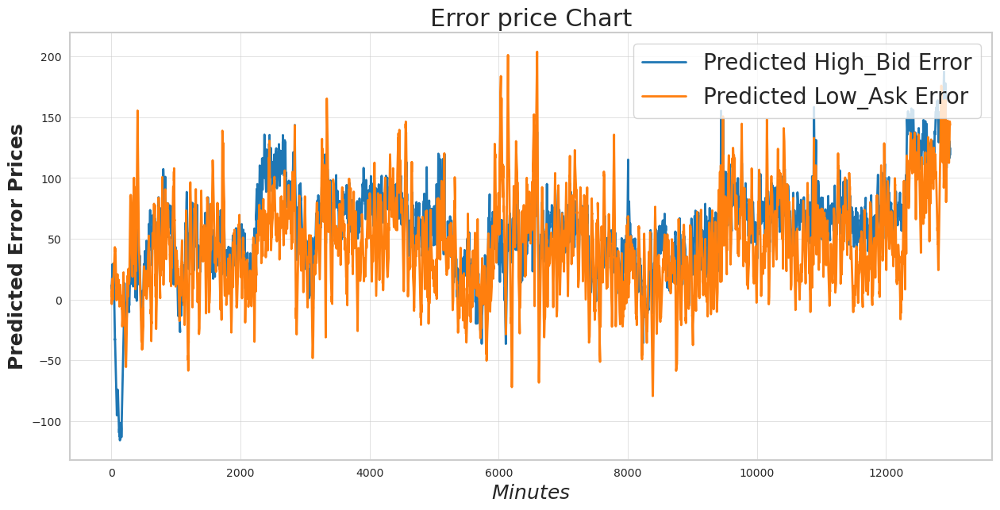

In [150]:
N1=0  # The first minute for the chart
LL = 130000  # leigt (in minutes) for the chart
N2=N1+LL  # the last minute for the chart
# N2 should be < len(pred)

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)

# in $ (absolute price)
a = (y_pred_CNNR[N1:N2,0] - y_test[N1:N2,0]) * 1000
b = (y_pred_CNNR[N1:N2,1] - y_test[N1:N2,1]) * 1000

# in %
#a = (pred[N1:N2,0] - y_test[N1:N2,0]) *1000/ average_price *100
#b = (pred[N1:N2,1] - y_test[N1:N2,1]) *1000/ average_price *100


line1, = ax1.plot(a, label='Predicted High_Bid Error')
line2, = ax1.plot(b, label='Predicted Low_Ask Error')

plt.title('Error price Chart', size=22)
plt.ylabel('Predicted Error Prices', size=18)
plt.xlabel('$Minutes$', size=18)
plt.legend(loc='upper right')

plt.show()

### MLP

In [152]:
tf.keras.backend.clear_session(
    free_memory=True
)

#### Create model

In [154]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(50, 40)),
    keras.layers.Dense(1024, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(512, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(256, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(128, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(2)
])

print(model.summary())

/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 2000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     2,049,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,738,306 (10.45 MB)

 Trainable params: 2,738,306 (10.45 MB)

 Non-trainable params: 0 (0.00 B)

None


In [155]:
model.compile(optimizer="nadam", loss="mse", metrics=["mae"])

# Early Stopping parameters

es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_MLPR.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

In [156]:
history = model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])

Epoch 1/25
1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.0704 - mae: 0.0621
Epoch 1: val_loss improved from inf to 0.00049, saving model to best_model_MLPR.keras
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 64s 48ms/step - loss: 0.0704 - mae: 0.0621 - val_loss: 4.9311e-04 - val_mae: 0.0164
Epoch 2/25
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 3.2965e-04 - mae: 0.0103
Epoch 2: val_loss did not improve from 0.00049
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 61s 47ms/step - loss: 3.2986e-04 - mae: 0.0103 - val_loss: 5.0829e-04 - val_mae: 0.0167
Epoch 3/25
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 8.0084e-05 - mae: 0.0063
Epoch 3: val_loss improved from 0.00049 to 0.00047, saving model to best_model_MLPR.keras
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 82s 47ms/step - loss: 8.0084e-05 - mae: 0.0063 - val_loss: 4.7483e-04 - val_mae: 0.0151
Epoch 4/25
1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 8.3103e-05 - mae: 0.0065
Epoch 4: val_loss did not improve from 0.00047
1300/1300 ━━━━━━━━━━━━━━━━━━━

#### Evaluate

In [158]:
Saved_best_model_MLP = keras.models.load_model("best_model_MLPR.keras")

In [159]:
# Evaluate the quality of network training on test data, which the network has NOT seen.

scores_MLPR = Saved_best_model_LSTM.evaluate(X_test, y_test, verbose=1)
y_pred_MLPR = Saved_best_model_LSTM.predict(X_test)

scores_MLPR = list(scores_MLPR)
scores_MLPR.append(r2_score(y_test, y_pred_MLPR))
print(scores_MLPR)
print("Mean squared error (mse): %.9f " % (scores_MLPR[0]))
print("Mean absolute error (mae): %.9f " % (scores_MLPR[1]))
print("R2 score: %.9f " % (scores_MLPR[2]))

407/407 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0052 - mae: 0.0625
407/407 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
[0.005621875170618296, 0.06438076496124268, -0.43683991317756493]
Mean squared error (mse): 0.005621875 
Mean absolute error (mae): 0.064380765 
R2 score: -0.436839913 


Text(0.5, 0, 'Mean Squared Error')

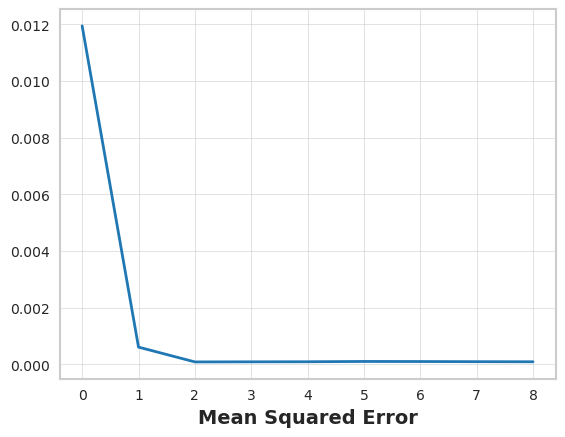

In [160]:
plt.plot(history.history["loss"])
plt.xlabel("Mean Squared Error", size = 14)

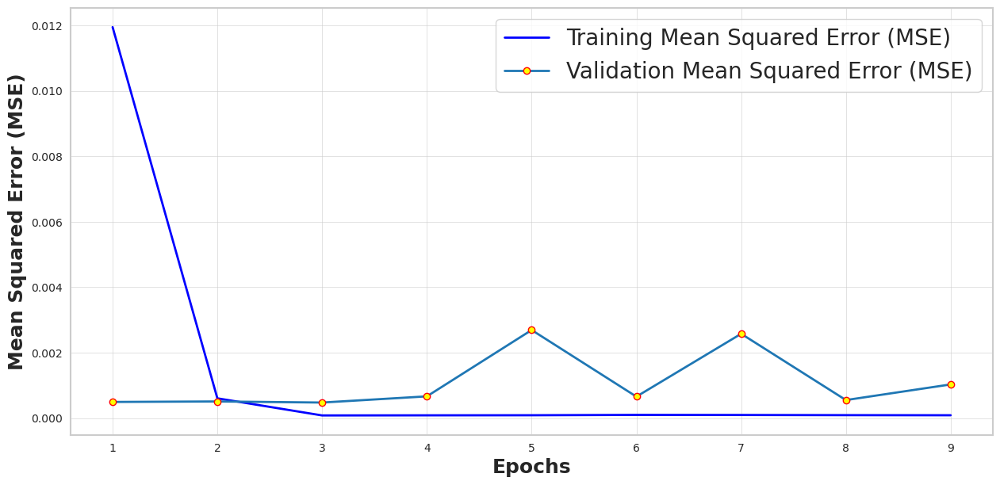

In [161]:
# More detailed MSE graph

history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

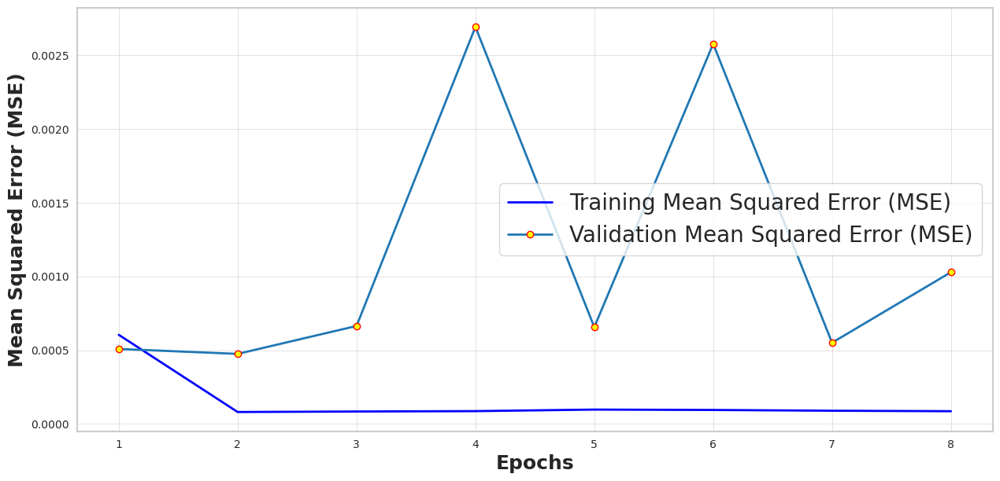

In [162]:
# deleted the 1st epoch
# to examine in detail the results of the remaining epochs

history_dict = history.history

mse_values = history_dict['loss'][1:]
val_mse_values = history_dict['val_loss'][1:]

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

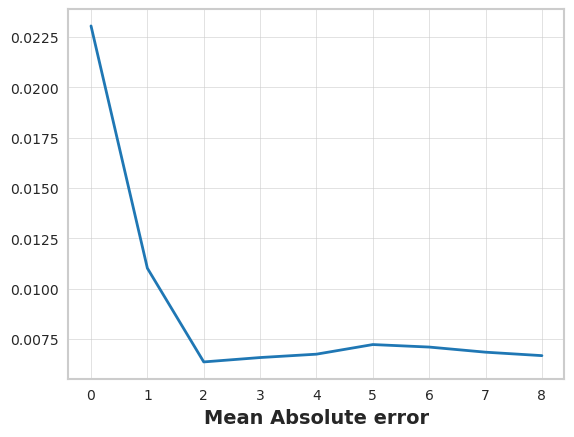

In [163]:
plt.plot(history.history["mae"])
plt.xlabel("Mean Absolute error", size = 14)
plt.show()

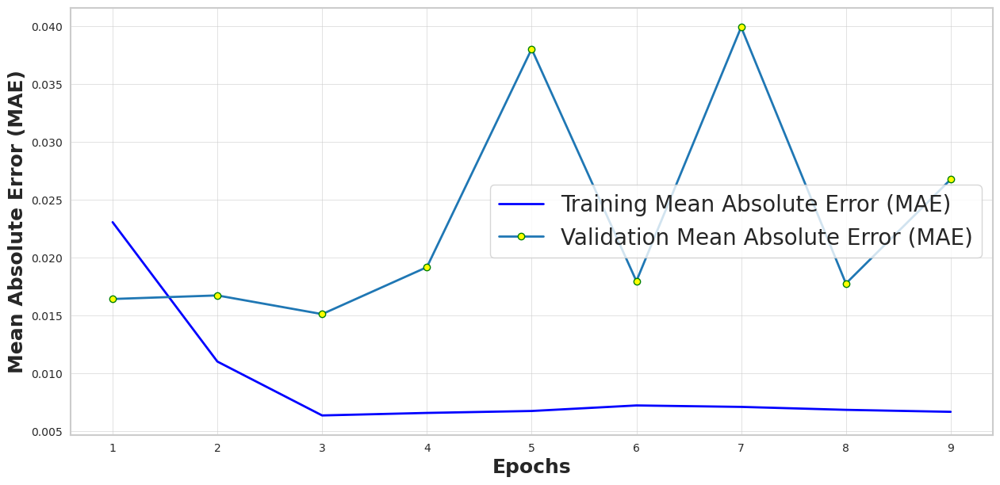

In [164]:
history_dict = history.history

mae_values = history_dict["mae"]
val_mae_values = history_dict["val_mae"]

epochs = range(1, len(mae_values) + 1)
plt.figure(num = 1, figsize = (15, 7))
plt.plot(epochs, mae_values, 'b', label="Training Mean Absolute Error (MAE)")
plt.plot(epochs, val_mae_values, marker='o', markeredgecolor="Green", markerfacecolor="yellow", label = "Validation Mean Absolute Error (MAE)")
plt.xlabel("Epochs", size = 18)
plt.ylabel("Mean Absolute Error (MAE)", size = 18)
plt.legend()
plt.show()

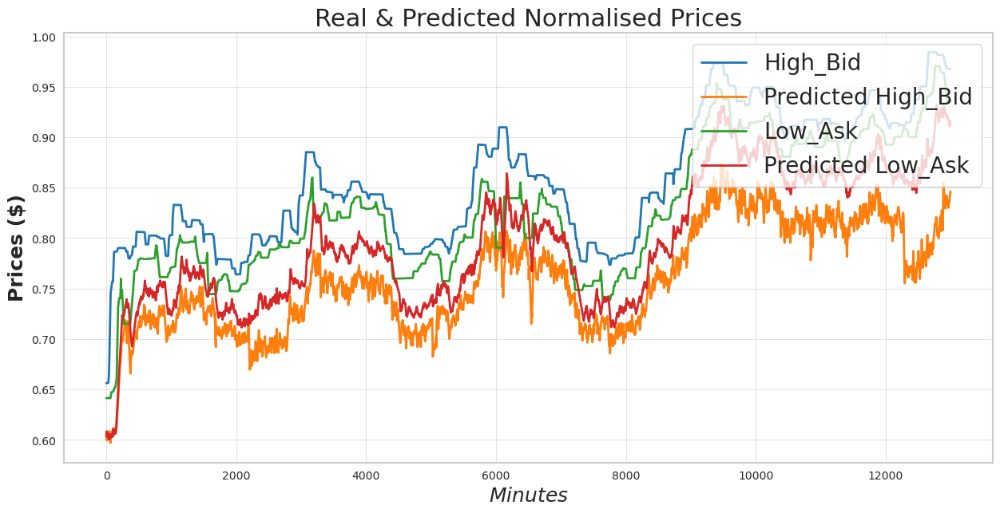

In [165]:
N1=0  # The first minute for the chart
LL = 130000  # Duration (in minutes) for the chart
N2=N1+LL  # the last minute for the chart

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)
line1, = ax1.plot(y_test[N1:N2,0], label='High_Bid')
line2, = ax1.plot(y_pred_MLPR[N1:N2,0], label='Predicted High_Bid')
line3, = ax1.plot(y_test[N1:N2,1], label='Low_Ask')
line4, = ax1.plot(y_pred_MLPR[N1:N2,1], label='Predicted Low_Ask')

plt.title('Real & Predicted Normalised Prices', size=22)
plt.ylabel('Prices ($)', size=18)
plt.xlabel('$Minutes$', size=18)
plt.legend(loc='upper right')

plt.show()

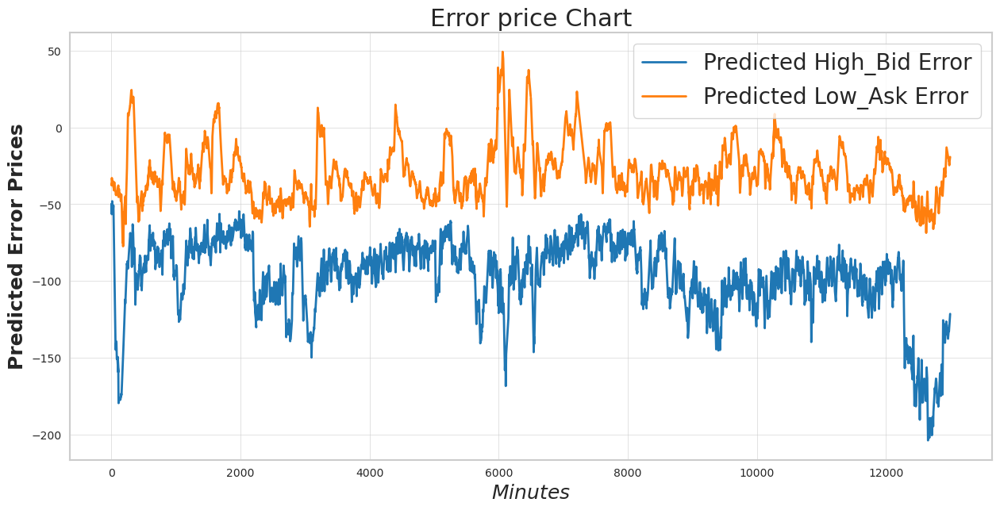

In [166]:
N1=0  # The first minute for the chart
LL = 130000  # leigt (in minutes) for the chart
N2=N1+LL  # the last minute for the chart
# N2 should be < len(pred)

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)

# in $ (absolute price)
a = (y_pred_MLPR[N1:N2,0] - y_test[N1:N2,0]) * 1000
b = (y_pred_MLPR[N1:N2,1] - y_test[N1:N2,1]) * 1000

# in %
#a = (pred[N1:N2,0] - y_test[N1:N2,0]) *1000/ average_price *100
#b = (pred[N1:N2,1] - y_test[N1:N2,1]) *1000/ average_price *100


line1, = ax1.plot(a, label='Predicted High_Bid Error')
line2, = ax1.plot(b, label='Predicted Low_Ask Error')

plt.title('Error price Chart', size=22)
plt.ylabel('Predicted Error Prices', size=18)
plt.xlabel('$Minutes$', size=18)
plt.legend(loc='upper right')

plt.show()

### GRU

In [168]:
# GRU for price prediction

import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout

tf.keras.backend.clear_session(
    free_memory=True
)

# Build GRU model
model = Sequential([
    GRU(50, return_sequences=True, input_shape=(50,40)),
    Dropout(0.2),
    GRU(50, return_sequences=False),
    Dropout(0.2),
    Dense(2)
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])


es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_GRU.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

history = model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Epoch 1/25
1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0064 - mae: 0.0420
Epoch 1: val_loss improved from inf to 0.00231, saving model to best_model_GRU.keras
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 42s 30ms/step - loss: 0.0064 - mae: 0.0420 - val_loss: 0.0023 - val_mae: 0.0421
Epoch 2/25
1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 2.6595e-04 - mae: 0.0122
Epoch 2: val_loss did not improve from 0.00231
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 38s 29ms/step - loss: 2.6589e-04 - mae: 0.0122 - val_loss: 0.0024 - val_mae: 0.0430
Epoch 3/25
1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 1.6839e-04 - mae: 0.0097
Epoch 3: val_loss improved from 0.00231 to 0.00138, saving model to best_model_GRU.keras
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 38s 29ms/step - loss: 1.6838e-04 - mae: 0.0097 - val_loss: 0.0014 - val_mae: 0.0307
Epoch 4/25
1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 1.3328e-04 - mae: 0.0085
Epoch 4: val_loss did not improve from 0.00138
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 38s 29ms/ste

In [169]:
# Evaluate the model
scores_GRU = model.evaluate(X_test, y_test, verbose=1)


407/407 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0161 - mae: 0.1233


In [170]:
# Predict future prices
predictions = model.predict(X_test)
print(predictions[:10])

407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
[[0.58955264 0.5782629 ]
 [0.5889113  0.57760227]
 [0.58914006 0.5776189 ]
 [0.5888126  0.57731974]
 [0.58816147 0.57654965]
 [0.5873959  0.5764379 ]
 [0.58728206 0.5763146 ]
 [0.5872655  0.5763722 ]
 [0.5881249  0.5773788 ]
 [0.5885861  0.5779145 ]]


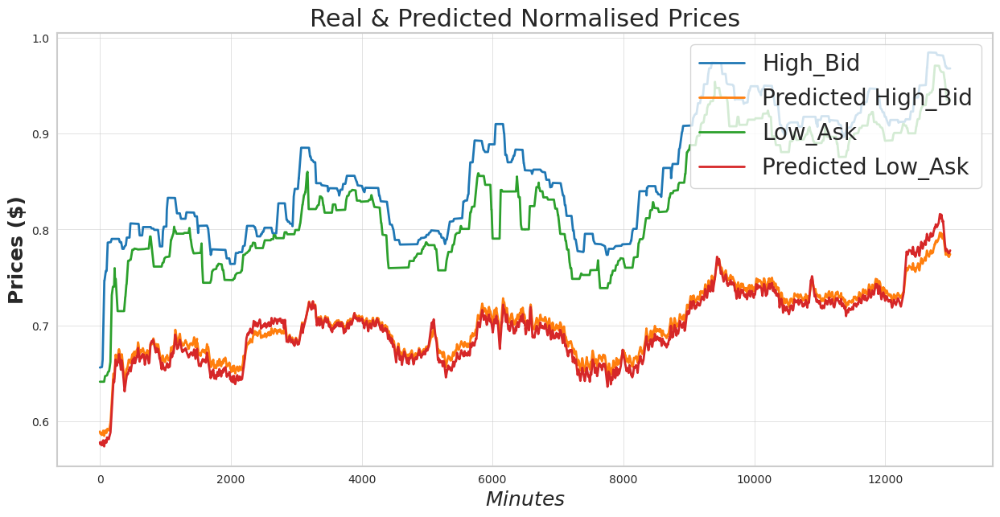

In [171]:
N1=0  # The first minute for the chart
LL = 130000  # Duration (in minutes) for the chart
N2=N1+LL  # the last minute for the chart

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)
line1, = ax1.plot(y_test[N1:N2,0], label='High_Bid')
line2, = ax1.plot(predictions[N1:N2,0], label='Predicted High_Bid')
line3, = ax1.plot(y_test[N1:N2,1], label='Low_Ask')
line4, = ax1.plot(predictions[N1:N2,1], label='Predicted Low_Ask')

plt.title('Real & Predicted Normalised Prices', size=22)
plt.ylabel('Prices ($)', size=18)
plt.xlabel('$Minutes$', size=18)
plt.legend(loc='upper right')

plt.show()

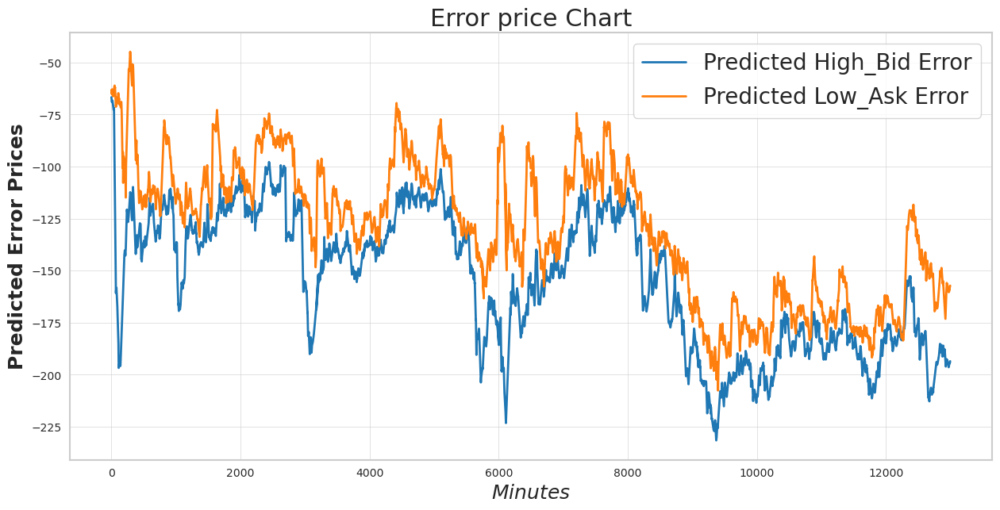

In [172]:
N1=0  # The first minute for the chart
LL = 130000  # leigt (in minutes) for the chart
N2=N1+LL  # the last minute for the chart
# N2 should be < len(pred)

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)

# in $ (absolute price)
a = (predictions[N1:N2,0] - y_test[N1:N2,0]) * 1000
b = (predictions[N1:N2,1] - y_test[N1:N2,1]) * 1000

# in %
#a = (pred[N1:N2,0] - y_test[N1:N2,0]) *1000/ average_price *100
#b = (pred[N1:N2,1] - y_test[N1:N2,1]) *1000/ average_price *100


line1, = ax1.plot(a, label='Predicted High_Bid Error')
line2, = ax1.plot(b, label='Predicted Low_Ask Error')

plt.title('Error price Chart', size=22)
plt.ylabel('Predicted Error Prices', size=18)
plt.xlabel('$Minutes$', size=18)
plt.legend(loc='upper right')

plt.show()

### TCN

In [142]:
# tcn for price prediction

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tcn import TCN

tf.keras.backend.clear_session(
    free_memory=True
)

# Define TCN model
def create_tcn_model():
    model = Sequential([
        TCN(64, input_shape=(50,40), kernel_size=3, dilations=[1, 2, 4, 8]),
        Dense(2)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# Train and predict
tcn_model = create_tcn_model()

es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_tcn.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

history = tcn_model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])

Epoch 1/25


2024-12-16 09:17:10.614434: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 748512000 exceeds 10% of free system memory.


1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - loss: 0.1032 - mae: 0.0817

2024-12-16 09:18:59.422281: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 187128000 exceeds 10% of free system memory.



Epoch 1: val_loss improved from inf to 0.03761, saving model to best_model_tcn.keras
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 115s 83ms/step - loss: 0.1030 - mae: 0.0816 - val_loss: 0.0376 - val_mae: 0.1654
Epoch 2/25
1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 4.1242e-04 - mae: 0.0152
Epoch 2: val_loss improved from 0.03761 to 0.01911, saving model to best_model_tcn.keras
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 100s 77ms/step - loss: 4.1234e-04 - mae: 0.0152 - val_loss: 0.0191 - val_mae: 0.1162
Epoch 3/25
1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 2.7001e-04 - mae: 0.0125
Epoch 3: val_loss did not improve from 0.01911
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 100s 77ms/step - loss: 2.6998e-04 - mae: 0.0125 - val_loss: 0.0213 - val_mae: 0.1213
Epoch 4/25
1299/1300 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 2.1988e-04 - mae: 0.0113
Epoch 4: val_loss improved from 0.01911 to 0.00465, saving model to best_model_tcn.keras
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 99s 76ms/step - loss: 2.1986e-04 - mae: 0.0113 - v

In [143]:
scores_tcn = tcn_model.predict(X_test)

2024-12-16 09:57:35.365494: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 103960000 exceeds 10% of free system memory.


407/407 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step


In [144]:
tcn_predictions = tcn_model.predict(X_test)
print(tcn_predictions[:10])

  9/407 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step

2024-12-16 09:57:42.217596: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 103960000 exceeds 10% of free system memory.


407/407 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step
[[0.63340986 0.68804467]
 [0.62756807 0.69123966]
 [0.62417215 0.6869919 ]
 [0.6250409  0.6936814 ]
 [0.61819106 0.6875268 ]
 [0.6247619  0.6426056 ]
 [0.6214709  0.6780812 ]
 [0.6210834  0.71330446]
 [0.6265124  0.71646184]
 [0.62138116 0.7046024 ]]


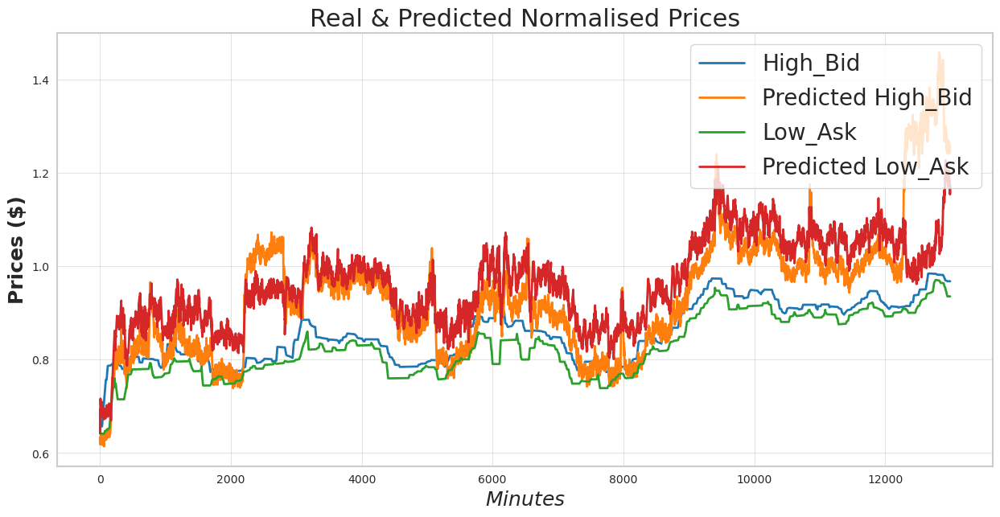

In [145]:
N1=0  # The first minute for the chart
LL = 130000  # Duration (in minutes) for the chart
N2=N1+LL  # the last minute for the chart

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)
line1, = ax1.plot(y_test[N1:N2,0], label='High_Bid')
line2, = ax1.plot(tcn_predictions[N1:N2,0], label='Predicted High_Bid')
line3, = ax1.plot(y_test[N1:N2,1], label='Low_Ask')
line4, = ax1.plot(tcn_predictions[N1:N2,1], label='Predicted Low_Ask')

plt.title('Real & Predicted Normalised Prices', size=22)
plt.ylabel('Prices ($)', size=18)
plt.xlabel('$Minutes$', size=18)
plt.legend(loc='upper right')

plt.show()

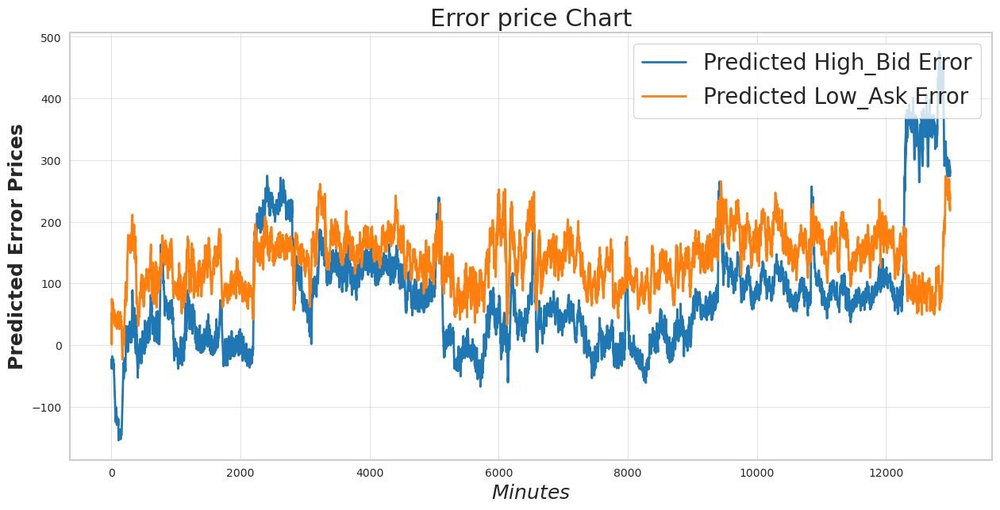

In [146]:
N1=0  # The first minute for the chart
LL = 130000  # leigt (in minutes) for the chart
N2=N1+LL  # the last minute for the chart
# N2 should be < len(pred)

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)

# in $ (absolute price)
a = (tcn_predictions[N1:N2,0] - y_test[N1:N2,0]) * 1000
b = (tcn_predictions[N1:N2,1] - y_test[N1:N2,1]) * 1000

# in %
#a = (pred[N1:N2,0] - y_test[N1:N2,0]) *1000/ average_price *100
#b = (pred[N1:N2,1] - y_test[N1:N2,1]) *1000/ average_price *100


line1, = ax1.plot(a, label='Predicted High_Bid Error')
line2, = ax1.plot(b, label='Predicted Low_Ask Error')

plt.title('Error price Chart', size=22)
plt.ylabel('Predicted Error Prices', size=18)
plt.xlabel('$Minutes$', size=18)
plt.legend(loc='upper right')

plt.show()

## 2D

### data transformation

In [ ]:
### data transformation

# We will predict the Highest and Lowest prices DURING the next 5 minutes.

# To do this in the data output (vector of answers), we shift prices sequentially to 15 minutes up,
# and find max and min prices during these 15 minutes
# Then you need to delete the 3 last rows since there are no prices for the next 15 minutes.
# Therefore, we will create an array of answers "data_ay" with the Highest and Lowest prices shifted sequentially to 3 rows up.

n = data2.shape[0]
p = data2.shape[1]

print(n)
print(p)

data_ax = data2.drop(["Y_High_Bid", "Y_Low_Ask", 'High_Bid', 'Low_Ask'], axis = 1)
print(data_ax.info())
print(data_ax.shape)

data_ay = data2[["Y_High_Bid", "Y_Low_Ask"]]
print(data_ay.shape)
print(data_ay.head)

data_ay = data_ay.shift(-1)

# create new colomns: MIN_Lowest(Low_Ask) and MAX_Highest(High_Bid) prices of DURING NEXT 5 minutes

# Forward-looking window
indexer = pd.api.indexers.FixedForwardWindowIndexer(window_size=120)

data_ay['Y_High_Bid_120'] = data_ay['Y_High_Bid'].rolling(window=indexer).max()
data_ay['Y_Low_Ask_120']  = data_ay['Y_Low_Ask'].rolling(window=indexer).min()

data_ay = data_ay.drop(["Y_High_Bid", "Y_Low_Ask"], axis = 1)

# delete the 5 last rows in data_ay (because we don't have answers for the last 5 minutes)

for i in range(120):
    data_ay.drop(data_ay.shape[0]-1, axis=0, inplace=True)

# delete the last 5 rows in data_ax (because we don't have answers for the last 5 minutes)

for i in range(120):
    data_ax.drop(data_ax.shape[0]-1, axis=0, inplace=True)

# Create inputs Numpy

data_a = np.array(data_ax)

with np.printoptions(precision=4):
    print("data_a:")
    print(data_a[:2,:])
    print('\n')
    print(data_a[-2:,:])

print("numpy size: = ", data_a.shape)
print("type: ", data_a.dtype)

# Create outputs Numpy

data_y = np.array(data_ay)

print("data_a:")
print(data_y[:3,:])
print('\n')
print(data_y[-3:,:])

print("numpy size: = ", data_y.shape)
print("type: ", data_y.dtype)

# Assuming data_a and data_y are already defined.

n_small = 10000  # Size of data subset
N = 50  # Sliding window depth
L = n_small - N  # Number of slices
t = data_a.shape[1]  # Number of features

# Initialize data_b (L, N, t)
data_b = np.zeros((L, N, t), dtype='float32')
Y = np.zeros((L, 1), dtype='float32')  # Target array for Trend-Flat signal

# Fill data_b with slices from data_a and populate Y (trend)
print('L = n_small - N = ', L)
for k in tqdm(range(L)):
    data_b[k, :, :] = data_a[k:k + N, :]  # Fill sliding window slice
    Y[k, 0] = data_y[k + N - 1, 0]  # Trend-Flat signal for the current slice

print("data_b shape:", data_b.shape)
print("Y shape:", Y.shape)

### Create training and test set

In [ ]:
# Flatten the 3D tensor into 2D (samples, features)
X = data_b.reshape(L, N * t)  # Reshaping to (L, N*t) for Random Forest
print("Flattened data shape:", X.shape)

# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

### KNN

In [ ]:
# Import necessary libraries
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define the KNN model
knn = KNeighborsRegressor()

# Define the hyperparameter grid for KNN
param_grid = {
    'n_neighbors': [7],
    'weights': ['uniform', 'distance'],
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=knn, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get the best parameters
print(f"Best parameters for KNN: {grid_search.best_params_}")

# Make predictions using the best model
y_pred_knnr = grid_search.best_estimator_.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred_knnr)
mse = mean_squared_error(y_test, y_pred_knnr)
r2 = r2_score(y_test, y_pred_knnr)
scores_KNNR = []
scores_KNNR.append(mse)
scores_KNNR.append(mae)
scores_KNNR.append(r2)
print(f"MAE: {mae}, MSE: {mse}, R²: {r2}")
print(f"KNN - Mean Absolute Error: {mae:.4f}")
print(f"KNN - Mean Squared Error: {mse:.4f}")
print(f"KNN - R² Score: {r2:.4f}")


### RandomForest

In [ ]:
# Import necessary libraries
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define the RandomForestRegressor model
rf = RandomForestRegressor()

# Define the hyperparameter grid for RandomForestRegressor
param_grid = {
    'n_estimators': [50],
    'max_depth': [10, 20],
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get the best parameters
print(f"Best parameters for RandomForestRegressor: {grid_search.best_params_}")

# Make predictions using the best model
y_pred_rf = grid_search.best_estimator_.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
r2 = r2_score(y_test, y_pred_rf)
scores_RFR = []
scores_RFR.append(mse)
scores_RFR.append(mae)
scores_RFR.append(r2)
print(f"RandomForestRegressor - Mean Absolute Error: {mae:.4f}")
print(f"RandomForestRegressor - Mean Squared Error: {mse:.4f}")
print(f"RandomForestRegressor - R² Score: {r2:.4f}")


### XGBoost

In [ ]:
# Import necessary libraries
from sklearn.model_selection import GridSearchCV, train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define the XGBRegressor model
xgb = XGBRegressor()

# Define the hyperparameter grid for XGBRegressor
param_grid = {
    'n_estimators': [100],
    'max_depth': [3, 5],
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=xgb, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get the best parameters
print(f"Best parameters for XGBRegressor: {grid_search.best_params_}")

# Make predictions using the best model
y_pred_xgb = grid_search.best_estimator_.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred_xgb)
mse = mean_squared_error(y_test, y_pred_xgb)
r2 = r2_score(y_test, y_pred_xgb)
scores_XGR = []
scores_XGR.append(mse)
scores_XGR.append(mae)
scores_XGR.append(r2)
print(f"XGBRegressor - Mean Absolute Error: {mae:.4f}")
print(f"XGBRegressor - Mean Squared Error: {mse:.4f}")
print(f"XGBRegressor - R² Score: {r2:.4f}")

### SGDRegressor

In [ ]:
# Import necessary libraries
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
\
# Define the SGDRegressor model
sgd = SGDRegressor()

# Define the hyperparameter grid for SGDRegressor
param_grid = {
    'loss': ['squared_loss', 'huber'],
    'penalty': ['l2', 'l1', 'elasticnet'],
    'learning_rate': ['constant', 'optimal', 'invscaling'],
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=sgd, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get the best parameters
print(f"Best parameters for SGDRegressor: {grid_search.best_params_}")

# Make predictions using the best model
y_pred_sgd = grid_search.best_estimator_.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred_sgd)
mse = mean_squared_error(y_test, y_pred_sgd)
r2 = r2_score(y_test, y_pred_sgd)
scores_SGDR = []
scores_SGDR.append(mse)
scores_SGDR.append(mae)
scores_SGDR.append(r2)
print(f"SGDRegressor - Mean Absolute Error: {mae:.4f}")
print(f"SGDRegressor - Mean Squared Error: {mse:.4f}")
print(f"SGDRegressor - R² Score: {r2:.4f}")


## Comparison

In [ ]:
ai_models = ['LSTM', 'CNN', 'MLP', 'KNN', 'RandomForest', 'XGBoost', 'SGDRegressor']
model_prediction = [scores_LSTMR, scores_CNNR, scores_MLPR, scores_KNNR, scores_RFR, scores_XGR, scores_SGDR]

In [ ]:
mse_scores = []
mae_scores = []
r2_scores = []

for x in model_prediction:
    mse_scores.append(x[0])
    mae_scores.append(x[1])
    r2_scores.append(x[2])

In [ ]:
model_perform  = {'AI Models':ai_models,
              'MSE':mse_scores,
               'MAE':mae_scores,
                  'R2' :r2_scores
                 }
model_data  = pd.DataFrame(model_perform)
print('Result of model')
model_data

In [ ]:
## model_imb = model_data_imb.set_index('Imbalance AI Models')

model_data.plot(kind = 'bar', figsize = (14, 6), width = 0.6)
plt.title('ML Models performance')
plt.xlabel('Performance')
plt.ylabel('ML Models')
plt.legend(loc = 'lower right')
plt.show()

# Step 3 classification Flat-trend

## 3D

### Data transformation

In [ ]:
### data transformation

# We will predict the Highest and Lowest prices DURING the next 5 minutes.

# To do this in the data output (vector of answers), we shift prices sequentially to 15 minutes up,
# and find max and min prices during these 15 minutes
# Then you need to delete the 3 last rows since there are no prices for the next 15 minutes.
# Therefore, we will create an array of answers "data_ay" with the Highest and Lowest prices shifted sequentially to 3 rows up.

n = data2.shape[0]
p = data2.shape[1]

print(n)
print(p)

In [ ]:
# Forward-looking window
indexer = pd.api.indexers.FixedForwardWindowIndexer(window_size=120)


# create new columns: MIN_Lowest(Low_Ask) and MAX_Highest(High_Bid) prices of DURING NEXT 4 hours
# 48 rows of 5-minute time-frame each

data2['Y_High_Bid_2h'] = data2['Y_High_Bid'].rolling(window=indexer).max()
data2['Y_Low_Ask_2h']  = data2['Y_Low_Ask'].rolling(window=indexer).min()

In [ ]:
data2['Trend'] = 0

# Fill in "1s" If the movement (in any direction) within 4 hours is more than $10 (0.01 after the normalisation)

data2.loc[ (data2["Y_High_Bid_2h"] - data2["Close_Ask"]) >= 0.01, 'Trend'] = 1
print( data2['Trend'].sum() )

data2.loc[ (data2["Close_Bid"] - data2["Y_Low_Ask_2h"]) >= 0.01, 'Trend'] = 1
print( data2['Trend'].sum() )

In [ ]:
data2['Trend'].value_counts(sort = False).plot.pie()
plt.show()

In [ ]:
# delete the 5 last rows in data_ay (because we don't have answers for the last 5 minutes)

data_ay = data2[['Trend']]
data_ax = data2.drop(['Trend', 'Y_High_Bid', 'Y_Low_Ask', 'Y_High_Bid_2h', 'Y_Low_Ask_2h'], axis = 1)

for i in range(120):
    data_ay.drop(data_ay.shape[0]-1, axis=0, inplace=True)

# delete the last 5 rows in data_ax (because we don't have answers for the last 5 minutes)

for i in range(120):
    data_ax.drop(data_ax.shape[0]-1, axis=0, inplace=True)

In [ ]:
data_ay.shape

In [ ]:
data_ax.info()

In [ ]:
data_ax.shape

In [ ]:
# Create inputs Numpy

data_a = np.array(data_ax)

with np.printoptions(precision=4):
    print("data_a:")
    print(data_a[:2,:])
    print('\n')
    print(data_a[-2:,:])

print("numpy size: = ", data_a.shape)
print("type: ", data_a.dtype)

In [ ]:
# Create outputs Numpy

data_y = np.array(data_ay)

print("data_a:")
print(data_y[:3,:])
print('\n')
print(data_y[-3:,:])

print("numpy size: = ", data_y.shape)
print("type: ", data_y.dtype)

In [ ]:
n_small = 130000 # reduced dataset to 6053 rows
N = 50 # sliding window depth

L = n_small - N # number of sliding window slices
t = data_a.shape[1] # features number
print("Size of a three-dimensional inputs tensor: ", L, N, t)

# create imputs zeros 3D tensors with 'float32'

data_b = np.zeros( (L, N, t), dtype= 'float32' )

# create a two-dimensional zeros vector of answers - normalised the High_Bid and Low_Ask prices DURING next 15 minutes

Y = np.zeros((L, 1), dtype= 'float32') # We will predict two prices - normalised High_Bid and normalised Low_Ask

In [ ]:
# fill the imputs 3D tansor (data_b)
# and the array of answers Y


print('L = n_small - N = ', n_small-N, L)
for k in tqdm(range(L)):
    data_b[k, :, :] = data_a[k:k+N, :]

    Y[k,0] = data_y[k+N-1,0]   # Trend-Flat signal

print(k)                       # index value (for control)

print('data_b:', '\n', data_b)
print("Numpy size:        ", data_b.shape, '\n')

print( Y[:5,:])
print( Y[-10:,:])
print(      "Numpy size:         ", Y.shape)

In [ ]:
data = []
data_ax = []
data_ay = []
data_a = []
data_y = []

### Create training and test set

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data_b, Y, test_size = 0.1, shuffle = False, stratify = None, random_state = 101)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

In [ ]:
epochnum = 25
batch_size = 72
patience = 6
validation_split = 0.2

### LSTM

In [ ]:
tf.keras.backend.clear_session(
    free_memory=True
)

#### Create model

In [ ]:
model = keras.Sequential([
    keras.layers.LSTM(100, activation="relu", input_shape = (50, 42)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1)
])

model.summary()

In [ ]:
model.compile(optimizer = 'nadam', loss = 'binary_crossentropy', metrics = ['f1_score', 'recall', 'precision', 'accuracy'])
# Early Stopping parameters

es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_LSTMC.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

In [ ]:
history = model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])

#### Evaluate

In [ ]:
Saved_best_model_LSTM = keras.models.load_model("best_model_LSTMC.keras")

In [ ]:
# Evaluate the quality of network training on test data, which the network has NOT seen.

scores_LSTM = Saved_best_model_LSTM.evaluate(X_test, y_test, verbose=1)

print(scores_LSTM)
print("loss: %.9f " % (scores_LSTM[0]))
print("accuracy: %.9f " % (scores_LSTM[1]))

In [ ]:
plt.plot(history.history["loss"])
plt.xlabel("Mean Squared Error", size = 14)

In [ ]:
# More detailed MSE graph

history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
# deleted the 1st epoch
# to examine in detail the results of the remaining epochs

history_dict = history.history

mse_values = history_dict['loss'][1:]
val_mse_values = history_dict['val_loss'][1:]

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
plt.plot(history.history["accuracy"])
plt.xlabel("Mean Absolute error", size = 14)
plt.show()

In [ ]:
history_dict = history.history

mae_values = history_dict["accuracy"]
val_mae_values = history_dict["val_accuracy"]

epochs = range(1, len(mae_values) + 1)
plt.figure(num = 1, figsize = (15, 7))
plt.plot(epochs, mae_values, 'b', label="Training Mean Absolute Error (MAE)")
plt.plot(epochs, val_mae_values, marker='o', markeredgecolor="Green", markerfacecolor="yellow", label = "Validation Mean Absolute Error (MAE)")
plt.xlabel("Epochs", size = 18)
plt.ylabel("Mean Absolute Error (MAE)", size = 18)
plt.legend()
plt.show()

In [ ]:
pred = Saved_best_model_LSTM(X_test)
print(pred)

In [ ]:
y_pred_LSTMC = Saved_best_model_LSTM.predict(X_test)

y_pred_LSTM_labels = np.round(y_pred_LSTMC).tolist()

print("Mean squared error (mse): " % (y_pred_LSTMC[0]))
print("Mean absolute error (mae): " % (y_pred_LSTMC[1]))
print("LSTM Dataset Results")
print(classification_report(y_test, y_pred_LSTM_labels))

# Confusion matrix for ANN
cm = confusion_matrix(y_test, y_pred_LSTM_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot()
plt.show()

### CNN

#### Create model

In [ ]:
tf.keras.backend.clear_session(
    free_memory=True
)

In [ ]:
model = keras.Sequential([

    keras.layers.Conv1D(50, 9, padding = "same", input_shape = (50, 42), activation = "relu", kernel_initializer = "he_normal"),
    keras.layers.MaxPooling1D(7),
    keras.layers.Conv1D(100, 7, padding = "same", activation = "relu", kernel_initializer = "he_normal"),
    keras.layers.GlobalMaxPooling1D(),
    keras.layers.Dense(25, activation = "relu", kernel_initializer = "he_normal"),

    keras.layers.Dense(1)
])

print(model.summary())

In [ ]:
model.compile(optimizer="nadam", loss="binary_crossentropy", metrics=['f1_score', 'recall', 'precision', 'accuracy'])

# Early Stopping parameters

es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_CNNC.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

In [ ]:
history = model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])

#### Evaluate

In [ ]:
Saved_best_model_CNN = keras.models.load_model("best_model_CNNC.keras")

In [ ]:
# Evaluate the quality of network training on test data, which the network has NOT seen.

scores_CNN = Saved_best_model_CNN.evaluate(X_test, y_test, verbose=1)

print(scores_CNN)
print("Mean squared error (mse): %.9f " % (scores_CNN[0]))
print("Mean absolute error (mae): %.9f " % (scores_CNN[1]))

y_pred_CNNC = Saved_best_model_CNN.predict(X_test)

y_pred_CNN_labels = np.round(y_pred_CNNC).tolist()

print("CNN Dataset Results")
print(classification_report(y_test, y_pred_CNN_labels))

# Confusion matrix for ANN
cm = confusion_matrix(y_test, y_pred_CNN_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [ ]:
plt.plot(history.history["loss"])
plt.xlabel("Mean Squared Error", size = 14)

In [ ]:
# More detailed MSE graph

history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
# deleted the 1st epoch
# to examine in detail the results of the remaining epochs

history_dict = history.history

mse_values = history_dict['loss'][1:]
val_mse_values = history_dict['val_loss'][1:]

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
plt.plot(history.history["accuracy"])
plt.xlabel("Mean Absolute error", size = 14)
plt.show()

In [ ]:
history_dict = history.history

mae_values = history_dict["accuracy"]
val_mae_values = history_dict["val_accuracy"]

epochs = range(1, len(mae_values) + 1)
plt.figure(num = 1, figsize = (15, 7))
plt.plot(epochs, mae_values, 'b', label="Training Mean Absolute Error (MAE)")
plt.plot(epochs, val_mae_values, marker='o', markeredgecolor="Green", markerfacecolor="yellow", label = "Validation Mean Absolute Error (MAE)")
plt.xlabel("Epochs", size = 18)
plt.ylabel("Mean Absolute Error (MAE)", size = 18)
plt.legend()
plt.show()

In [ ]:
pred = Saved_best_model_CNN(X_test)
print(pred)

### MLP

#### Create model

In [ ]:
tf.keras.backend.clear_session(
    free_memory=True
)

In [ ]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(50, 42)),
    keras.layers.Dense(1024, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(512, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(256, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(128, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(1)
])

print(model.summary())

In [ ]:
model.compile(optimizer="nadam", loss="binary_crossentropy", metrics=['f1_score', 'recall', 'precision', 'accuracy'])

# Early Stopping parameters

es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_MLPC.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

In [ ]:
history = model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])

#### Evaluate

In [ ]:
Saved_best_model_MLP = keras.models.load_model("best_model_MLPC.keras")

In [ ]:
# Evaluate the quality of network training on test data, which the network has NOT seen.

scores_MLP = Saved_best_model_MLP.evaluate(X_test, y_test, verbose=1)

print(scores_MLP)
print("Mean squared error (mse): %.9f " % (scores_MLP[0]))
print("Mean absolute error (mae): %.9f " % (scores_MLP[1]))

y_pred_MLPC = Saved_best_model_MLP.predict(X_test)
y_pred_MLP_labels = (y_pred_MLPC >= 0.5).astype(int)
print("MLP Dataset Results")
print(classification_report(y_test, y_pred_MLP_labels))

# Confusion matrix for ANN
cm = confusion_matrix(y_test, y_pred_MLP_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot()
plt.show()

In [ ]:
plt.plot(history.history["loss"])
plt.xlabel("Mean Squared Error", size = 14)

In [ ]:
# More detailed MSE graph

history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
# deleted the 1st epoch
# to examine in detail the results of the remaining epochs

history_dict = history.history

mse_values = history_dict['loss'][1:]
val_mse_values = history_dict['val_loss'][1:]

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
plt.plot(history.history["accuracy"])
plt.xlabel("Mean Absolute error", size = 14)
plt.show()

In [ ]:
history_dict = history.history

mae_values = history_dict["accuracy"]
val_mae_values = history_dict["val_accuracy"]

epochs = range(1, len(mae_values) + 1)
plt.figure(num = 1, figsize = (15, 7))
plt.plot(epochs, mae_values, 'b', label="Training Mean Absolute Error (MAE)")
plt.plot(epochs, val_mae_values, marker='o', markeredgecolor="Green", markerfacecolor="yellow", label = "Validation Mean Absolute Error (MAE)")
plt.xlabel("Epochs", size = 18)
plt.ylabel("Mean Absolute Error (MAE)", size = 18)
plt.legend()
plt.show()

In [ ]:
pred = Saved_best_model_MLP(X_test)
print(pred)

### transformer + cnn

In [ ]:
# transfomer + cnn for trend prediction

from tensorflow.keras.layers import MultiHeadAttention, LayerNormalization, Conv1D, Dense, Input, Flatten
from tensorflow.keras.models import Model

tf.keras.backend.clear_session(
    free_memory=True
)

# Define hybrid model
def create_transformer_cnn():
    inputs = Input(shape=(50,42))
    
    # Transformer part
    x = MultiHeadAttention(num_heads=4, key_dim=64)(inputs, inputs)
    x = LayerNormalization()(x)
    
    # CNN part
    x = Conv1D(filters=64, kernel_size=3, activation='relu')(x)
    x = Flatten()(x)
    outputs = Dense(1, activation='sigmoid')(x)  # Binary trend classification
    
    model = Model(inputs, outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


# Train and predict
transformer_cnn_model = create_transformer_cnn()
es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_tcn.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

history = transformer_cnn_model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])


In [ ]:
trend_predictions_transformer_cnn = transformer_cnn_model.predict(X_test)


In [ ]:
print(trend_predictions_transformer_cnn[:10])

In [ ]:
# Evaluate the quality of network training on test data, which the network has NOT seen.

trend_predictions_transformer_cnn_labels = (trend_predictions_transformer_cnn >= 0.5).astype(int)
print("MLP Dataset Results")
print(classification_report(y_test, trend_predictions_transformer_cnn_labels))

# Confusion matrix for ANN
cm = confusion_matrix(y_test, trend_predictions_transformer_cnn_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot()
plt.show()

## 2D

### data transformation

In [ ]:
### data transformation

# We will predict the Highest and Lowest prices DURING the next 5 minutes.

# To do this in the data output (vector of answers), we shift prices sequentially to 15 minutes up,
# and find max and min prices during these 15 minutes
# Then you need to delete the 3 last rows since there are no prices for the next 15 minutes.
# Therefore, we will create an array of answers "data_ay" with the Highest and Lowest prices shifted sequentially to 3 rows up.

n = data2.shape[0]
p = data2.shape[1]

print(n)
print(p)

data_ax = data2.drop(["Trend", 'Y_High_Bid', 'Y_Low_Ask'], axis = 1)
print(data_ax.info())
print(data_ax.shape)

data_ay = data2[["Trend"]]
print(data_ay.shape)
print(data_ay.head)

data_ay = data_ay.shift(-1)

# create new colomns: MIN_Lowest(Low_Ask) and MAX_Highest(High_Bid) prices of DURING NEXT 5 minutes

# Forward-looking window
indexer = pd.api.indexers.FixedForwardWindowIndexer(window_size=120)

data_ay['Y_Trend_120'] = data_ay['Trend'].rolling(window=indexer).max()

data_ay = data_ay.drop(["Trend"], axis = 1)

# delete the 5 last rows in data_ay (because we don't have answers for the last 5 minutes)

for i in range(120):
    data_ay.drop(data_ay.shape[0]-1, axis=0, inplace=True)

# delete the last 5 rows in data_ax (because we don't have answers for the last 5 minutes)

for i in range(120):
    data_ax.drop(data_ax.shape[0]-1, axis=0, inplace=True)

# Create inputs Numpy

data_a = np.array(data_ax)

with np.printoptions(precision=4):
    print("data_a:")
    print(data_a[:2,:])
    print('\n')
    print(data_a[-2:,:])

print("numpy size: = ", data_a.shape)
print("type: ", data_a.dtype)

# Create outputs Numpy

data_y = np.array(data_ay)

print("data_a:")
print(data_y[:3,:])
print('\n')
print(data_y[-3:,:])

print("numpy size: = ", data_y.shape)
print("type: ", data_y.dtype)

# Assuming data_a and data_y are already defined.

n_small = 6000  # Size of data subset
N = 50  # Sliding window depth
L = n_small - N  # Number of slices
t = data_a.shape[1]  # Number of features

# Initialize data_b (L, N, t)
data_b = np.zeros((L, N, t), dtype='float32')
Y = np.zeros((L, 1), dtype='float32')  # Target array for Trend-Flat signal

# Fill data_b with slices from data_a and populate Y (trend)
print('L = n_small - N = ', L)
for k in tqdm(range(L)):
    data_b[k, :, :] = data_a[k:k + N, :]  # Fill sliding window slice
    Y[k, 0] = data_y[k + N - 1, 0]  # Trend-Flat signal for the current slice

print("data_b shape:", data_b.shape)
print("Y shape:", Y.shape)

### Create training and test set

In [ ]:
# Flatten the 3D tensor into 2D (samples, features)
X = data_b.reshape(L, N * t)  # Reshaping to (L, N*t) for Random Forest
print("Flattened data shape:", X.shape)

# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

### KNN

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here

# Define the KNN model
knn = KNeighborsClassifier()

# Define hyperparameter grid
param_grid = {
    'n_neighbors': [5, 7],  # Number of neighbors
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=knn, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get best parameters
print("Best parameters found: ", grid_search.best_params_)

# Make predictions using the best model
y_pred_KNNC = grid_search.best_estimator_.predict(X_test)

# Evaluate the performance
accuracy = accuracy_score(y_test, y_pred_KNNC)
print(f"Accuracy of the best model: {accuracy * 100:.2f}%")

report = classification_report(y_test, y_pred_KNNC)
print(report)
cm = confusion_matrix(y_test, y_pred_KNNC)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

scores_KNNC = grid_search.best_estimator_.score(X_test, y_test)

print("Train score: %f" % grid_search.best_estimator_.score(X_train, y_train))
print("Test score: %f" % grid_search.best_estimator_.score(X_test, y_test))
# Cohen's Kappa score (inter-rater reliability metric)
kappa_score = cohen_kappa_score(y_test, y_pred_KNNC)
print(f"Cohen's Kappa score: {kappa_score:.6f}")

### RandomForest

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, cohen_kappa_score

# Define the RandomForestClassifier model
rf = RandomForestClassifier(random_state=42)

# Define hyperparameter grid for RandomForest
param_grid = {
    'n_estimators': [50],  # Number of trees in the forest
    'max_depth': [None, 10],  # Maximum depth of the tree
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get best parameters
print("Best parameters found: ", grid_search.best_params_)

# Make predictions using the best model
y_pred_RFC = grid_search.best_estimator_.predict(X_test)

# Evaluate the performance
accuracy = accuracy_score(y_test, y_pred_RFC)
print(f"Accuracy of the best model: {accuracy * 100:.2f}%")

# Generate classification report
report = classification_report(y_test, y_pred_RFC)
print(report)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_RFC)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

# Get the score of the best model
scores_RF = grid_search.best_estimator_.score(X_test, y_test)
print(f"Train score: {grid_search.best_estimator_.score(X_train, y_train):.6f}")
print(f"Test score: {scores_RF:.6f}")

# Cohen's Kappa score (inter-rater reliability metric)
kappa_score = cohen_kappa_score(y_test, y_pred_RFC)
print(f"Cohen's Kappa score: {kappa_score:.6f}")


### XGBoost

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, cohen_kappa_score

# Define the XGBClassifier model
xgb = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss')

# Define hyperparameter grid for XGBoost
param_grid = {
    'n_estimators': [50],  # Number of boosting rounds
    'max_depth': [5, 7],          # Maximum depth of a tree
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=xgb, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get best parameters
print("Best parameters found: ", grid_search.best_params_)

# Make predictions using the best model
y_pred_XGC = grid_search.best_estimator_.predict(X_test)

# Evaluate the performance
accuracy = accuracy_score(y_test, y_pred_XGC)
print(f"Accuracy of the best model: {accuracy * 100:.2f}%")

# Generate classification report
report = classification_report(y_test, y_pred_XGC)
print(report)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_XGC)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

# Get the score of the best model
scores_XGB = grid_search.best_estimator_.score(X_test, y_test)
print(f"Train score: {grid_search.best_estimator_.score(X_train, y_train):.6f}")
print(f"Test score: {scores_XGB:.6f}")

# Cohen's Kappa score (inter-rater reliability metric)
kappa_score = cohen_kappa_score(y_test, y_pred_XGC)
print(f"Cohen's Kappa score: {kappa_score:.6f}")


### SGDClassifier

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, cohen_kappa_score

# Define the SGDClassifier model
sgd = SGDClassifier(random_state=42)

# Define hyperparameter grid for SGDClassifier
param_grid = {
    'loss': ['hinge', 'log', 'squared_hinge', 'perceptron'],  # Loss function to use
    'penalty': ['l2', 'l1', 'elasticnet'],  # Regularization type
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=sgd, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get best parameters
print("Best parameters found: ", grid_search.best_params_)

# Make predictions using the best model
y_pred_SGDC = grid_search.best_estimator_.predict(X_test)

# Evaluate the performance
accuracy = accuracy_score(y_test, y_pred_SGDC)
print(f"Accuracy of the best model: {accuracy * 100:.2f}%")

# Generate classification report
report = classification_report(y_test, y_pred_SGDC)
print(report)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_SGDC)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

# Get the score of the best model
scores_SGD = grid_search.best_estimator_.score(X_test, y_test)
print(f"Train score: {grid_search.best_estimator_.score(X_train, y_train):.6f}")
print(f"Test score: {scores_SGD:.6f}")

# Cohen's Kappa score (inter-rater reliability metric)
kappa_score = cohen_kappa_score(y_test, y_pred_SGDC)
print(f"Cohen's Kappa score: {kappa_score:.6f}")


## Comparison

In [ ]:
ai_models = ['LSTM', 'CNN', 'MLP', 'KNN', 'RandomForest', 'XGBoost', 'SGDClassifier']
model_prediction = [y_pred_LSTMC, y_pred_CNNC, y_pred_MLPC, y_pred_KNNC, y_pred_RFC, y_pred_XGC, y_pred_SGDC]

In [ ]:
model_prediction = [np.round(pred) for pred in model_prediction]

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Assuming y_test.shape[0] provides the correct number of samples
num_samples = y_test.shape[0]

# Reshape model predictions to match y_test for classification metrics
model_prediction = [pred[-num_samples:].reshape(-1) for pred in model_prediction]

accuracy_imb = []
precision_imb = []
recall_imb =[]
f1_imb = []
auc_imb = []

for x in range(len(model_prediction)):
    # Calculate metrics, now with consistent shapes
    acc_score = np.round(accuracy_score(y_test[:, 0], model_prediction[x]) * 100, 2)  # Use y_test[:, 0] for binary classification
    accuracy_imb.append(acc_score)
    pre_score = np.round(precision_score(y_test[:, 0], model_prediction[x], average='weighted') * 100, 2)
    precision_imb.append(pre_score)
    rc_score = np.round(recall_score(y_test[:, 0], model_prediction[x], average='weighted') * 100, 2)
    recall_imb.append(rc_score)
    f_score = np.round(f1_score(y_test[:, 0], model_prediction[x], average='weighted') * 100, 2)
    f1_imb.append(f_score)
    auc_sc = np.round(roc_auc_score(y_test[:, 0], model_prediction[x]) * 100, 2)
    auc_imb.append(auc_sc)

In [ ]:
print('Type of prediction_imb', type(model_prediction))
print('Type of each element in prediction_imb', type(model_prediction[0]))
model_perform_imb  = {'Imbalance AI Models':ai_models,
              'Accuracy':accuracy_imb,
               'Precision':precision_imb,
               'Recall':recall_imb,
               'F1-Score':f1_imb,
               'AUC':auc_imb
              }
model_data_imb  = pd.DataFrame(model_perform_imb)
print('Result of testing with an Imbalanced Dataset')
model_data_imb

In [ ]:
model_imb = model_data_imb.set_index('Imbalance AI Models')

model_data_imb.plot(kind='bar', figsize=(14,6), width=0.6)
plt.title('ML Models performance on the predicton of credit risk on imbalanaced dataset')
plt.ylabel('Performance')
plt.xlabel('ML Models')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

# Step 3 classification updown

## 3D

### Data transformation

In [ ]:
### data transformation

# We will predict the Highest and Lowest prices DURING the next 5 minutes.

# To do this in the data output (vector of answers), we shift prices sequentially to 15 minutes up,
# and find max and min prices during these 15 minutes
# Then you need to delete the 3 last rows since there are no prices for the next 15 minutes.
# Therefore, we will create an array of answers "data_ay" with the Highest and Lowest prices shifted sequentially to 3 rows up.

n = data2.shape[0]
p = data2.shape[1]

print(n)
print(p)

In [ ]:
# Forward-looking window
indexer = pd.api.indexers.FixedForwardWindowIndexer(window_size=120)


# create new columns: MIN_Lowest(Low_Ask) and MAX_Highest(High_Bid) prices of DURING NEXT 4 hours
# 48 rows of 5-minute time-frame each

data2['Y_High_Bid_2h'] = data2['Y_High_Bid'].rolling(window=indexer).max()
data2['Y_Low_Ask_2h']  = data2['Y_Low_Ask'].rolling(window=indexer).min()

In [ ]:
data2['Trend'] = 0

# Fill in "1s" If the movement (in any direction) within 4 hours is more than $10 (0.01 after the normalisation)

data2.loc[ (data2["Y_High_Bid_2h"] - data2["Close_Ask"]) > 0, 'Trend'] = 1
print( data2['Trend'].sum() )

data2.loc[ (data2["Close_Bid"] - data2["Y_Low_Ask_2h"]) > 0, 'Trend'] = 0
print( data2['Trend'].sum() )

In [ ]:
data2['Trend'].value_counts(sort = False).plot.pie()
plt.show()

In [ ]:
# delete the 5 last rows in data_ay (because we don't have answers for the last 5 minutes)

data_ay = data2[['Trend']]
data_ax = data2.drop(['Trend', 'Y_High_Bid', 'Y_Low_Ask', 'Y_High_Bid_2h', 'Y_Low_Ask_2h'], axis = 1)

for i in range(120):
    data_ay.drop(data_ay.shape[0]-1, axis=0, inplace=True)

# delete the last 5 rows in data_ax (because we don't have answers for the last 5 minutes)

for i in range(120):
    data_ax.drop(data_ax.shape[0]-1, axis=0, inplace=True)

In [ ]:
data_ay.shape

In [ ]:
data_ax.info()

In [ ]:
data_ax.shape

In [ ]:
# Create inputs Numpy

data_a = np.array(data_ax)

with np.printoptions(precision=4):
    print("data_a:")
    print(data_a[:2,:])
    print('\n')
    print(data_a[-2:,:])

print("numpy size: = ", data_a.shape)
print("type: ", data_a.dtype)

In [ ]:
# Create outputs Numpy

data_y = np.array(data_ay)

print("data_a:")
print(data_y[:3,:])
print('\n')
print(data_y[-3:,:])

print("numpy size: = ", data_y.shape)
print("type: ", data_y.dtype)

In [ ]:
n_small = 130000 # reduced dataset to 6053 rows
N = 50 # sliding window depth

L = n_small - N # number of sliding window slices
t = data_a.shape[1] # features number
print("Size of a three-dimensional inputs tensor: ", L, N, t)

# create imputs zeros 3D tensors with 'float32'

data_b = np.zeros( (L, N, t), dtype= 'float32' )

# create a two-dimensional zeros vector of answers - normalised the High_Bid and Low_Ask prices DURING next 15 minutes

Y = np.zeros((L, 1), dtype= 'float32') # We will predict two prices - normalised High_Bid and normalised Low_Ask

In [ ]:
# fill the imputs 3D tansor (data_b)
# and the array of answers Y


print('L = n_small - N = ', n_small-N, L)
for k in tqdm(range(L)):
    data_b[k, :, :] = data_a[k:k+N, :]

    Y[k,0] = data_y[k+N-1,0]   # Trend-Flat signal

print(k)                       # index value (for control)

print('data_b:', '\n', data_b)
print("Numpy size:        ", data_b.shape, '\n')

print( Y[:5,:])
print( Y[-10:,:])
print(      "Numpy size:         ", Y.shape)

In [ ]:
data = []
data_ax = []
data_ay = []
data_a = []
data_y = []

### Create training and test set

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data_b, Y, test_size = 0.1, shuffle = False, stratify = None, random_state = 101)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

In [ ]:
epochnum = 25
batch_size = 72
patience = 6
validation_split = 0.2

### LSTM

In [ ]:
tf.keras.backend.clear_session(
    free_memory=True
)

#### Create model

In [ ]:
model = keras.Sequential([
    keras.layers.LSTM(100, activation="softmax", input_shape = (50, 42)),
    keras.layers.Dense(1)
])
model.summary()

In [ ]:
model.compile(optimizer = 'nadam', loss = 'binary_crossentropy', metrics = ['f1_score', 'recall', 'precision', 'accuracy'])
# Early Stopping parameters

es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_LSTMC.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

In [ ]:
history = model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])

#### Evaluate

In [ ]:
Saved_best_model_LSTM = keras.models.load_model("best_model_LSTMC.keras")

In [ ]:
# Evaluate the quality of network training on test data, which the network has NOT seen.

scores_LSTM = Saved_best_model_LSTM.evaluate(X_test, y_test, verbose=1)

print(scores_LSTM)
print("loss: %.9f " % (scores_LSTM[0]))
print("accuracy: %.9f " % (scores_LSTM[1]))

In [ ]:
plt.plot(history.history["loss"])
plt.xlabel("Mean Squared Error", size = 14)

In [ ]:
# More detailed MSE graph

history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
# deleted the 1st epoch
# to examine in detail the results of the remaining epochs

history_dict = history.history

mse_values = history_dict['loss'][1:]
val_mse_values = history_dict['val_loss'][1:]

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
plt.plot(history.history["accuracy"])
plt.xlabel("Mean Absolute error", size = 14)
plt.show()

In [ ]:
history_dict = history.history

mae_values = history_dict["accuracy"]
val_mae_values = history_dict["val_accuracy"]

epochs = range(1, len(mae_values) + 1)
plt.figure(num = 1, figsize = (15, 7))
plt.plot(epochs, mae_values, 'b', label="Training Mean Absolute Error (MAE)")
plt.plot(epochs, val_mae_values, marker='o', markeredgecolor="Green", markerfacecolor="yellow", label = "Validation Mean Absolute Error (MAE)")
plt.xlabel("Epochs", size = 18)
plt.ylabel("Mean Absolute Error (MAE)", size = 18)
plt.legend()
plt.show()

In [ ]:
pred = Saved_best_model_LSTM(X_test)
print(pred)

In [ ]:
y_pred_LSTMC = Saved_best_model_LSTM.predict(X_test)
y_pred_LSTM_labels = np.round(y_pred_LSTMC).tolist()

print("Mean squared error (mse): " % (y_pred_LSTMC[0]))
print("Mean absolute error (mae): " % (y_pred_LSTMC[1]))
print("LSTM Dataset Results")
print(classification_report(y_test, y_pred_LSTM_labels))

# Confusion matrix for ANN
cm = confusion_matrix(y_test, y_pred_LSTM_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot()
plt.show()

### CNN

#### Create model

In [ ]:
tf.keras.backend.clear_session(
    free_memory=True
)

In [ ]:
model = keras.Sequential([

    keras.layers.Conv1D(50, 9, padding = "same", input_shape = (50, 42), activation = "relu", kernel_initializer = "he_normal"),
    keras.layers.MaxPooling1D(7),
    keras.layers.Conv1D(100, 7, padding = "same", activation = "relu", kernel_initializer = "he_normal"),
    keras.layers.GlobalMaxPooling1D(),
    keras.layers.Dense(25, activation = "relu", kernel_initializer = "he_normal"),

    keras.layers.Dense(1)
])

print(model.summary())

In [ ]:
model.compile(optimizer="nadam", loss="binary_crossentropy", metrics=['f1_score', 'recall', 'precision', 'accuracy'])

# Early Stopping parameters

es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_CNNC.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

In [ ]:
history = model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])

#### Evaluate

In [ ]:
Saved_best_model_CNN = keras.models.load_model("best_model_CNNC.keras")

In [ ]:
# Evaluate the quality of network training on test data, which the network has NOT seen.

scores_CNN = Saved_best_model_CNN.evaluate(X_test, y_test, verbose=1)

print(scores_CNN)
print("Mean squared error (mse): %.9f " % (scores_CNN[0]))
print("Mean absolute error (mae): %.9f " % (scores_CNN[1]))

y_pred_CNNC = Saved_best_model_CNN.predict(X_test)
y_pred_CNN_labels = np.round(y_pred_CNNC).tolist()
print("CNN Dataset Results")
print(classification_report(y_test, y_pred_CNN_labels))

# Confusion matrix for ANN
cm = confusion_matrix(y_test, y_pred_CNN_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot()
plt.show()

In [ ]:
plt.plot(history.history["loss"])
plt.xlabel("Mean Squared Error", size = 14)

In [ ]:
# More detailed MSE graph

history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
# deleted the 1st epoch
# to examine in detail the results of the remaining epochs

history_dict = history.history

mse_values = history_dict['loss'][1:]
val_mse_values = history_dict['val_loss'][1:]

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
plt.plot(history.history["accuracy"])
plt.xlabel("Mean Absolute error", size = 14)
plt.show()

In [ ]:
history_dict = history.history

mae_values = history_dict["accuracy"]
val_mae_values = history_dict["val_accuracy"]

epochs = range(1, len(mae_values) + 1)
plt.figure(num = 1, figsize = (15, 7))
plt.plot(epochs, mae_values, 'b', label="Training Mean Absolute Error (MAE)")
plt.plot(epochs, val_mae_values, marker='o', markeredgecolor="Green", markerfacecolor="yellow", label = "Validation Mean Absolute Error (MAE)")
plt.xlabel("Epochs", size = 18)
plt.ylabel("Mean Absolute Error (MAE)", size = 18)
plt.legend()
plt.show()

In [ ]:
pred = Saved_best_model_CNN(X_test)
print(pred)

### MLP

#### Create model

In [ ]:
tf.keras.backend.clear_session(
    free_memory=True
)

In [ ]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(50, 42)),
    keras.layers.Dense(1024, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(512, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(256, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(128, activation = "relu", kernel_initializer="he_normal"),
    keras.layers.Dense(1)
])

print(model.summary())

In [ ]:
model.compile(optimizer="nadam", loss="binary_crossentropy", metrics=['f1_score', 'recall', 'precision', 'accuracy'])

# Early Stopping parameters

es = EarlyStopping(monitor='val_loss', mode='min', patience=patience, verbose=1)
mc = ModelCheckpoint('best_model_MLPC.keras', monitor='val_loss', mode='min', verbose=1, save_best_only=True)

In [ ]:
history = model.fit(X_train, y_train, batch_size = batch_size, epochs = epochnum,
                    validation_split = validation_split, shuffle = True,
                    verbose = 1, callbacks = [es, mc])

#### Evaluate

In [ ]:
Saved_best_model_MLP = keras.models.load_model("best_model_MLPC.keras")

In [ ]:
# Evaluate the quality of network training on test data, which the network has NOT seen.

scores_MLP = Saved_best_model_MLP.evaluate(X_test, y_test, verbose=1)

print(scores_MLP)
print("Mean squared error (mse): %.9f " % (scores_MLP[0]))
print("Mean absolute error (mae): %.9f " % (scores_MLP[1]))

y_pred_MLPC = Saved_best_model_MLP.predict(X_test)
y_pred_MLP_labels = np.round(y_pred_MLPC).tolist()
print("MLP Dataset Results")
print(classification_report(y_test, y_pred_MLP_labels))

# Confusion matrix for ANN
cm = confusion_matrix(y_test, y_pred_MLP_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot()
plt.show()

In [ ]:
plt.plot(history.history["loss"])
plt.xlabel("Mean Squared Error", size = 14)

In [ ]:
# More detailed MSE graph

history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
# deleted the 1st epoch
# to examine in detail the results of the remaining epochs

history_dict = history.history

mse_values = history_dict['loss'][1:]
val_mse_values = history_dict['val_loss'][1:]

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

In [ ]:
plt.plot(history.history["accuracy"])
plt.xlabel("Mean Absolute error", size = 14)
plt.show()

In [ ]:
history_dict = history.history

mae_values = history_dict["accuracy"]
val_mae_values = history_dict["val_accuracy"]

epochs = range(1, len(mae_values) + 1)
plt.figure(num = 1, figsize = (15, 7))
plt.plot(epochs, mae_values, 'b', label="Training Mean Absolute Error (MAE)")
plt.plot(epochs, val_mae_values, marker='o', markeredgecolor="Green", markerfacecolor="yellow", label = "Validation Mean Absolute Error (MAE)")
plt.xlabel("Epochs", size = 18)
plt.ylabel("Mean Absolute Error (MAE)", size = 18)
plt.legend()
plt.show()

In [ ]:
pred = Saved_best_model_MLP(X_test)
print(pred)

## 2D

### data transformation

In [ ]:
### data transformation

# We will predict the Highest and Lowest prices DURING the next 5 minutes.

# To do this in the data output (vector of answers), we shift prices sequentially to 15 minutes up,
# and find max and min prices during these 15 minutes
# Then you need to delete the 3 last rows since there are no prices for the next 15 minutes.
# Therefore, we will create an array of answers "data_ay" with the Highest and Lowest prices shifted sequentially to 3 rows up.

n = data2.shape[0]
p = data2.shape[1]

print(n)
print(p)

data_ax = data2.drop(["Trend", 'Y_High_Bid', 'Y_Low_Ask'], axis = 1)
print(data_ax.info())
print(data_ax.shape)

data_ay = data2[["Trend"]]
print(data_ay.shape)
print(data_ay.head)

data_ay = data_ay.shift(-1)

# create new colomns: MIN_Lowest(Low_Ask) and MAX_Highest(High_Bid) prices of DURING NEXT 5 minutes

# Forward-looking window
indexer = pd.api.indexers.FixedForwardWindowIndexer(window_size=120)

data_ay['Y_Trend_120'] = data_ay['Trend'].rolling(window=indexer).max()

data_ay = data_ay.drop(["Trend"], axis = 1)

# delete the 5 last rows in data_ay (because we don't have answers for the last 5 minutes)

for i in range(120):
    data_ay.drop(data_ay.shape[0]-1, axis=0, inplace=True)

# delete the last 5 rows in data_ax (because we don't have answers for the last 5 minutes)

for i in range(120):
    data_ax.drop(data_ax.shape[0]-1, axis=0, inplace=True)

# Create inputs Numpy

data_a = np.array(data_ax)

with np.printoptions(precision=4):
    print("data_a:")
    print(data_a[:2,:])
    print('\n')
    print(data_a[-2:,:])

print("numpy size: = ", data_a.shape)
print("type: ", data_a.dtype)

# Create outputs Numpy

data_y = np.array(data_ay)

print("data_a:")
print(data_y[:3,:])
print('\n')
print(data_y[-3:,:])

print("numpy size: = ", data_y.shape)
print("type: ", data_y.dtype)

# Assuming data_a and data_y are already defined.

n_small = 5000  # Size of data subset
N = 50  # Sliding window depth
L = n_small - N  # Number of slices
t = data_a.shape[1]  # Number of features

# Initialize data_b (L, N, t)
data_b = np.zeros((L, N, t), dtype='float32')
Y = np.zeros((L, 1), dtype='float32')  # Target array for Trend-Flat signal

# Fill data_b with slices from data_a and populate Y (trend)
print('L = n_small - N = ', L)
for k in tqdm(range(L)):
    data_b[k, :, :] = data_a[k:k + N, :]  # Fill sliding window slice
    Y[k, 0] = data_y[k + N - 1, 0]  # Trend-Flat signal for the current slice

print("data_b shape:", data_b.shape)
print("Y shape:", Y.shape)

### Create training and test set

In [ ]:
# Flatten the 3D tensor into 2D (samples, features)
X = data_b.reshape(L, N * t)  # Reshaping to (L, N*t) for Random Forest
print("Flattened data shape:", X.shape)

# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

### KNN

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
# What is happening here

# Define the KNN model
knn = KNeighborsClassifier()

# Define hyperparameter grid
param_grid = {
    'n_neighbors': [5, 7],  # Number of neighbors
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=knn, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get best parameters
print("Best parameters found: ", grid_search.best_params_)

# Make predictions using the best model
y_pred_KNNC = grid_search.best_estimator_.predict(X_test)

# Evaluate the performance
accuracy = accuracy_score(y_test, y_pred_KNNC)
print(f"Accuracy of the best model: {accuracy * 100:.2f}%")

report = classification_report(y_test, y_pred_KNNC)
print(report)
cm = confusion_matrix(y_test, y_pred_KNNC)
disp=ConfusionMatrixDisplay(cm)
disp.plot()

scores_KNNC = grid_search.best_estimator_.score(X_test, y_test)

print("Train score: %f" % grid_search.best_estimator_.score(X_train, y_train))
print("Test score: %f" % grid_search.best_estimator_.score(X_test, y_test))
# Cohen's Kappa score (inter-rater reliability metric)
kappa_score = cohen_kappa_score(y_test, y_pred_KNNC)
print(f"Cohen's Kappa score: {kappa_score:.6f}")

### RandomForest

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, cohen_kappa_score

# Define the RandomForestClassifier model
rf = RandomForestClassifier(random_state=42)

# Define hyperparameter grid for RandomForest
param_grid = {
    'n_estimators': [50],  # Number of trees in the forest
    'max_depth': [None, 10],  # Maximum depth of the tree
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get best parameters
print("Best parameters found: ", grid_search.best_params_)

# Make predictions using the best model
y_pred_RFC = grid_search.best_estimator_.predict(X_test)

# Evaluate the performance
accuracy = accuracy_score(y_test, y_pred_RFC)
print(f"Accuracy of the best model: {accuracy * 100:.2f}%")

# Generate classification report
report = classification_report(y_test, y_pred_RFC)
print(report)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_RFC)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

# Get the score of the best model
scores_RF = grid_search.best_estimator_.score(X_test, y_test)
print(f"Train score: {grid_search.best_estimator_.score(X_train, y_train):.6f}")
print(f"Test score: {scores_RF:.6f}")

# Cohen's Kappa score (inter-rater reliability metric)
kappa_score = cohen_kappa_score(y_test, y_pred_RFC)
print(f"Cohen's Kappa score: {kappa_score:.6f}")


### XGBoost

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, cohen_kappa_score

# Define the XGBClassifier model
xgb = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss')

# Define hyperparameter grid for XGBoost
param_grid = {
    'n_estimators': [50],  # Number of boosting rounds
    'max_depth': [5, 7],          # Maximum depth of a tree
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=xgb, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get best parameters
print("Best parameters found: ", grid_search.best_params_)

# Make predictions using the best model
y_pred_XGC = grid_search.best_estimator_.predict(X_test)

# Evaluate the performance
accuracy = accuracy_score(y_test, y_pred_XGC)
print(f"Accuracy of the best model: {accuracy * 100:.2f}%")

# Generate classification report
report = classification_report(y_test, y_pred_XGC)
print(report)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_XGC)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

# Get the score of the best model
scores_XGB = grid_search.best_estimator_.score(X_test, y_test)
print(f"Train score: {grid_search.best_estimator_.score(X_train, y_train):.6f}")
print(f"Test score: {scores_XGB:.6f}")

# Cohen's Kappa score (inter-rater reliability metric)
kappa_score = cohen_kappa_score(y_test, y_pred_XGC)
print(f"Cohen's Kappa score: {kappa_score:.6f}")


### SGDClassifier

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, cohen_kappa_score

# Define the SGDClassifier model
sgd = SGDClassifier(random_state=42)

# Define hyperparameter grid for SGDClassifier
param_grid = {
    'loss': ['hinge', 'log', 'squared_hinge', 'perceptron'],  # Loss function to use
    'penalty': ['l2', 'l1', 'elasticnet'],  # Regularization type
}

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=sgd, param_grid=param_grid, cv=2, n_jobs=-1, verbose=1)

# Fit the model with GridSearchCV
grid_search.fit(X_train, y_train)

# Get best parameters
print("Best parameters found: ", grid_search.best_params_)

# Make predictions using the best model
y_pred_SGDC = grid_search.best_estimator_.predict(X_test)

# Evaluate the performance
accuracy = accuracy_score(y_test, y_pred_SGDC)
print(f"Accuracy of the best model: {accuracy * 100:.2f}%")

# Generate classification report
report = classification_report(y_test, y_pred_SGDC)
print(report)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_SGDC)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

# Get the score of the best model
scores_SGD = grid_search.best_estimator_.score(X_test, y_test)
print(f"Train score: {grid_search.best_estimator_.score(X_train, y_train):.6f}")
print(f"Test score: {scores_SGD:.6f}")

# Cohen's Kappa score (inter-rater reliability metric)
kappa_score = cohen_kappa_score(y_test, y_pred_SGDC)
print(f"Cohen's Kappa score: {kappa_score:.6f}")


## Comparison

In [ ]:
ai_models = ['LSTM', 'CNN', 'MLP', 'KNN', 'RandomForest', 'XGBoost', 'SGDClassifier']
model_prediction = [y_pred_LSTMC, y_pred_CNNC, y_pred_MLPC, y_pred_KNNC, y_pred_RFC, y_pred_XGC, y_pred_SGDC]

In [ ]:
model_prediction = [np.round(pred) for pred in model_prediction]

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Assuming y_test.shape[0] provides the correct number of samples
num_samples = y_test.shape[0]

# Reshape model predictions to match y_test for classification metrics
model_prediction = [pred[-num_samples:].reshape(-1) for pred in model_prediction]

accuracy_imb = []
precision_imb = []
recall_imb =[]
f1_imb = []
auc_imb = []

for x in range(len(model_prediction)):
    # Calculate metrics, now with consistent shapes
    acc_score = np.round(accuracy_score(y_test[:, 0], model_prediction[x]) * 100, 2)  # Use y_test[:, 0] for binary classification
    accuracy_imb.append(acc_score)
    pre_score = np.round(precision_score(y_test[:, 0], model_prediction[x], average='weighted') * 100, 2)
    precision_imb.append(pre_score)
    rc_score = np.round(recall_score(y_test[:, 0], model_prediction[x], average='weighted') * 100, 2)
    recall_imb.append(rc_score)
    f_score = np.round(f1_score(y_test[:, 0], model_prediction[x], average='weighted') * 100, 2)
    f1_imb.append(f_score)
    auc_sc = np.round(roc_auc_score(y_test[:, 0], model_prediction[x]) * 100, 2)
    auc_imb.append(auc_sc)

In [ ]:
print('Type of prediction_imb', type(model_prediction))
print('Type of each element in prediction_imb', type(model_prediction[0]))
model_perform_imb  = {'Imbalance AI Models':ai_models,
              'Accuracy':accuracy_imb,
               'Precision':precision_imb,
               'Recall':recall_imb,
               'F1-Score':f1_imb,
               'AUC':auc_imb
              }
model_data_imb  = pd.DataFrame(model_perform_imb)
print('Result of testing with an Imbalanced Dataset')
model_data_imb

In [ ]:
model_imb = model_data_imb.set_index('Imbalance AI Models')

model_data_imb.plot(kind='bar', figsize=(14,6), width=0.6)
plt.title('ML Models performance on the predicton of credit risk on imbalanaced dataset')
plt.ylabel('Performance')
plt.xlabel('ML Models')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()